# KidneyShield — Evidence-Driven Generic Drug Repurposing for Kidney Failure Prevention

**Project objective:** Build a reproducible, evidence-based research package to identify and evaluate generic drugs that may help prevent kidney failure or slow chronic kidney disease (CKD) progression.

**Research workflow**

1. Retrieve public biomedical literature and clinical-trial records.
2. Screen studies for kidney outcomes and study design.
3. Review primary studies and extract quantitative evidence.
4. Evaluate safety, mechanisms, dosing, interactions, and real-world evidence.
5. Compare candidate drugs using transparent criteria.
6. Generate scientific figures, evidence tables, and a final reproducible report.

**Scientific safeguard:** Search-result counts and keyword matches are screening signals, not evidence that a drug works. Clinical conclusions require study-level verification.

**Data sources:** PubMed, ClinicalTrials.gov, and additional public regulatory and biomedical resources where accessible.

**Recovery safeguard:** Save each milestone's outputs and create downloadable ZIP checkpoints. Kaggle session files are temporary, so download checkpoints to your device.


In [7]:

# ============================================================
# KIDNEYSHIELD | CELL 1
# Project initialization, API connectivity, and checkpointing
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import csv
import zipfile
import time
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ----------------------------
# 1. Project directories
# ----------------------------
ROOT = Path("/kaggle/working/kidneyshield")

DIRS = {
    "raw": ROOT / "data" / "raw",
    "processed": ROOT / "data" / "processed",
    "results": ROOT / "results",
    "figures": ROOT / "results" / "figures",
    "logs": ROOT / "logs",
    "visuals": ROOT / "results" / "medical_visuals",
    "backups": ROOT / "backups",
}

for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

print("KidneyShield project directory:", ROOT)
print("Project directories created:", len(DIRS))

# ----------------------------
# 2. Research configuration
# ----------------------------
CANDIDATES = [
    "pentoxifylline",
    "allopurinol",
    "colchicine",
    "N-acetylcysteine",
    "metformin",
    "hydroxychloroquine",
    "minocycline",
]

TARGET_CONDITIONS = [
    "chronic kidney disease",
    "diabetic kidney disease",
    "diabetic nephropathy",
    "kidney failure",
    "end-stage kidney disease",
]

PRIMARY_OUTCOMES = [
    "kidney failure requiring dialysis or transplantation",
    "sustained decline in kidney function",
    "doubling of serum creatinine",
    "all-cause mortality",
]

SECONDARY_OUTCOMES = [
    "eGFR level or slope",
    "albuminuria or proteinuria",
    "acute kidney injury",
    "adverse events",
    "quality of life",
]

API_URLS = {
    "pubmed_esearch":
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi",
    "pubmed_efetch":
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi",
    "pubmed_esummary":
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi",
    "clinical_trials":
        "https://clinicaltrials.gov/api/v2/studies",
    "dailymed":
        "https://dailymed.nlm.nih.gov/dailymed/services/v2",
    "openfda":
        "https://api.fda.gov",
    "europe_pmc":
        "https://www.ebi.ac.uk/europepmc/webservices/rest",
}

CONFIG = {
    "project": "KidneyShield",
    "project_version": "1.0",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "root": str(ROOT),
    "candidates": CANDIDATES,
    "target_conditions": TARGET_CONDITIONS,
    "primary_outcomes": PRIMARY_OUTCOMES,
    "secondary_outcomes": SECONDARY_OUTCOMES,
    "api_urls": API_URLS,
    "scientific_guardrails": [
        "Search counts do not establish efficacy.",
        "Distinguish hard clinical outcomes from surrogate outcomes.",
        "Verify study design, population, comparator, and follow-up.",
        "Extract effect estimates, confidence intervals, and p-values "
        "only when supported by source material.",
        "Do not treat a keyword match as a confirmed kidney outcome.",
        "Do not recommend a drug for an individual patient."
    ],
}

CONFIG_PATH = ROOT / "project_config.json"
CONFIG_PATH.write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")

# ----------------------------
# 3. HTTP session with retries
# ----------------------------
SESSION = requests.Session()

retry_policy = Retry(
    total=3,
    connect=3,
    read=3,
    backoff_factor=0.8,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)

adapter = HTTPAdapter(max_retries=retry_policy)
SESSION.mount("https://", adapter)
SESSION.mount("http://", adapter)

SESSION.headers.update({
    "User-Agent": "KidneyShield-Research-Prototype/1.0 "
                  "(public biomedical evidence retrieval)"
})

REQUEST_TIMEOUT = 25

# ----------------------------
# 4. Connectivity checks
# ----------------------------
def check_endpoint(name, url, params=None):
    record = {
        "endpoint": name,
        "url": url,
        "status": "FAILED",
        "http_status": None,
        "elapsed_seconds": None,
        "message": "",
        "checked_utc": datetime.now(timezone.utc).isoformat(),
    }

    start = time.time()

    try:
        response = SESSION.get(
            url,
            params=params,
            timeout=REQUEST_TIMEOUT
        )
        record["http_status"] = response.status_code
        record["elapsed_seconds"] = round(time.time() - start, 2)

        if response.ok:
            record["status"] = "REACHABLE"
            record["message"] = "HTTP request succeeded"
        else:
            record["message"] = response.text[:200]

    except Exception as exc:
        record["elapsed_seconds"] = round(time.time() - start, 2)
        record["message"] = str(exc)[:300]

    return record


connectivity = [
    check_endpoint(
        "PubMed ESearch",
        API_URLS["pubmed_esearch"],
        params={
            "db": "pubmed",
            "term": "chronic kidney disease",
            "retmax": 0,
            "retmode": "json",
        },
    ),
    check_endpoint(
        "ClinicalTrials.gov API v2",
        API_URLS["clinical_trials"],
        params={
            "query.cond": "chronic kidney disease",
            "pageSize": 1,
            "format": "json",
        },
    ),
]

connectivity_path = DIRS["logs"] / "connectivity_check.csv"

with connectivity_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(connectivity[0].keys()))
    writer.writeheader()
    writer.writerows(connectivity)

for item in connectivity:
    print(
        f'{item["endpoint"]}: {item["status"]}'
        + (
            f' | HTTP {item["http_status"]}'
            if item["http_status"] is not None else ""
        )
    )
    if item["status"] != "REACHABLE":
        print("  Detail:", item["message"])

# ----------------------------
# 5. Run manifest
# ----------------------------
MANIFEST_PATH = DIRS["logs"] / "run_manifest.json"

def save_manifest(extra=None):
    previous = {}
    if MANIFEST_PATH.exists():
        try:
            previous = json.loads(
                MANIFEST_PATH.read_text(encoding="utf-8")
            )
        except Exception:
            previous = {}

    previous.update({
        "project": "KidneyShield",
        "updated_utc": datetime.now(timezone.utc).isoformat(),
        "root": str(ROOT),
        "config_path": str(CONFIG_PATH),
        "connectivity_path": str(connectivity_path),
        "candidate_count": len(CANDIDATES),
        "condition_count": len(TARGET_CONDITIONS),
        "cell_1_status": "completed",
    })

    if extra:
        previous.update(extra)

    MANIFEST_PATH.write_text(
        json.dumps(previous, indent=2),
        encoding="utf-8"
    )
    return previous

save_manifest({
    "connectivity": connectivity,
    "completed_cells": ["cell_1"],
})

# ----------------------------
# 6. Checkpoint ZIP function
# ----------------------------
def make_checkpoint(label="checkpoint"):
    """
    Create a ZIP of the current project.

    The ZIP is written outside ROOT so it cannot include itself.
    Existing source files are copied; the originals remain unchanged.
    """
    safe_label = "".join(
        c if c.isalnum() or c in "-_" else "_"
        for c in label
    )

    timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    zip_path = Path("/kaggle/working") / (
        f"KidneyShield_{safe_label}_{timestamp}.zip"
    )

    with zipfile.ZipFile(
        zip_path, "w", compression=zipfile.ZIP_DEFLATED
    ) as archive:
        for path in ROOT.rglob("*"):
            if not path.is_file():
                continue
            if path.name.endswith(".tmp"):
                continue
            archive.write(path, arcname=path.relative_to(ROOT))

    print("Checkpoint created:", zip_path)
    print("ZIP size (MB):", round(zip_path.stat().st_size / 1e6, 3))
    return zip_path

# Initial small checkpoint
INITIAL_CHECKPOINT = make_checkpoint("cell1")

print("\n" + "=" * 60)
print("KIDNEYSHIELD — CELL 1 COMPLETE")
print("=" * 60)
print("Candidates:", len(CANDIDATES))
print("Target conditions:", len(TARGET_CONDITIONS))
print("Configuration:", CONFIG_PATH)
print("Run manifest:", MANIFEST_PATH)
print("Connectivity log:", connectivity_path)
print("Initial checkpoint:", INITIAL_CHECKPOINT)
print("\nNext: save a Kaggle notebook version before proceeding to Cell 2.")

KidneyShield project directory: /kaggle/working/kidneyshield
Project directories created: 7
PubMed ESearch: REACHABLE | HTTP 200
ClinicalTrials.gov API v2: REACHABLE | HTTP 200
Checkpoint created: /kaggle/working/KidneyShield_cell1_20261010_074217.zip
ZIP size (MB): 4.182

KIDNEYSHIELD — CELL 1 COMPLETE
Candidates: 7
Target conditions: 5
Configuration: /kaggle/working/kidneyshield/project_config.json
Run manifest: /kaggle/working/kidneyshield/logs/run_manifest.json
Connectivity log: /kaggle/working/kidneyshield/logs/connectivity_check.csv
Initial checkpoint: /kaggle/working/KidneyShield_cell1_20261010_074217.zip

Next: save a Kaggle notebook version before proceeding to Cell 2.


# Cell 2 — Public Biomedical Evidence Retrieval

This cell builds the initial evidence corpus for KidneyShield by querying PubMed and ClinicalTrials.gov for seven candidate generic drugs.

**Outputs**

* PubMed article metadata and abstracts, where available
* ClinicalTrials.gov study metadata, including interventions, eligibility criteria, and reported outcomes
* Candidate-level search logs and retrieval counts
* Raw API responses for traceability
* A timestamped ZIP checkpoint

**Important limitations:** PubMed retrieval is capped at 300 search results per candidate in this initial pass, so it is not exhaustive. Search results may include studies unrelated to kidney disease. Duplicate records are deduplicated by identifier, and later cells must verify study relevance, design, endpoints, and quantitative results before drawing conclusions.

This is a literature-screening prototype, not a clinical decision tool or a recommendation to use any candidate drug.


In [8]:

# ============================================================
# KIDNEYSHIELD | CELL 2
# Retrieve PubMed literature and ClinicalTrials.gov records
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import csv
import json
import time
import zipfile
import xml.etree.ElementTree as ET

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ------------------------------------------------------------
# 1. Re-establish paths and configuration
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/kidneyshield")

DIRS = {
    "raw": ROOT / "data" / "raw",
    "processed": ROOT / "data" / "processed",
    "results": ROOT / "results",
    "figures": ROOT / "results" / "figures",
    "logs": ROOT / "logs",
    "visuals": ROOT / "results" / "medical_visuals",
    "backups": ROOT / "backups",
}

for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

RAW_PUBMED = DIRS["raw"] / "pubmed"
RAW_TRIALS = DIRS["raw"] / "clinical_trials"

RAW_PUBMED.mkdir(parents=True, exist_ok=True)
RAW_TRIALS.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = ROOT / "project_config.json"

if CONFIG_PATH.exists():
    CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
    CANDIDATES = CONFIG.get("candidates", [
        "pentoxifylline", "allopurinol", "colchicine",
        "N-acetylcysteine", "metformin",
        "hydroxychloroquine", "minocycline"
    ])
else:
    CANDIDATES = [
        "pentoxifylline",
        "allopurinol",
        "colchicine",
        "N-acetylcysteine",
        "metformin",
        "hydroxychloroquine",
        "minocycline",
    ]
    CONFIG = {
        "project": "KidneyShield",
        "project_version": "1.0",
        "candidates": CANDIDATES,
    }
    CONFIG_PATH.write_text(
        json.dumps(CONFIG, indent=2), encoding="utf-8"
    )

PUBMED_SEARCH_URL = (
    "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"
)
PUBMED_FETCH_URL = (
    "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
)
CLINICAL_TRIALS_URL = "https://clinicaltrials.gov/api/v2/studies"

MAX_PUBMED_PER_CANDIDATE = 300
TRIALS_PAGE_SIZE = 100
REQUEST_TIMEOUT = 35

SESSION = requests.Session()
retry_policy = Retry(
    total=3,
    connect=3,
    read=3,
    backoff_factor=0.8,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)
adapter = HTTPAdapter(max_retries=retry_policy)
SESSION.mount("https://", adapter)
SESSION.mount("http://", adapter)
SESSION.headers.update({
    "User-Agent": "KidneyShield-Research-Prototype/1.0"
})

# Candidate query terms. Search terms are deliberately broad;
# relevance will be assessed in later screening cells.
PUBMED_TERMS = {
    "pentoxifylline": '"pentoxifylline"[Title/Abstract]',
    "allopurinol": '"allopurinol"[Title/Abstract]',
    "colchicine": '"colchicine"[Title/Abstract]',
    "N-acetylcysteine":
        '("N-acetylcysteine"[Title/Abstract] OR '
        '"acetylcysteine"[Title/Abstract] OR "NAC"[Title/Abstract])',
    "metformin": '"metformin"[Title/Abstract]',
    "hydroxychloroquine": '"hydroxychloroquine"[Title/Abstract]',
    "minocycline": '"minocycline"[Title/Abstract]',
}

TRIALS_TERMS = {
    "pentoxifylline": "pentoxifylline",
    "allopurinol": "allopurinol",
    "colchicine": "colchicine",
    "N-acetylcysteine": "acetylcysteine",
    "metformin": "metformin",
    "hydroxychloroquine": "hydroxychloroquine",
    "minocycline": "minocycline",
}

# ------------------------------------------------------------
# 2. Small reusable helpers
# ------------------------------------------------------------

def utc_now():
    return datetime.now(timezone.utc).isoformat()

def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

def write_csv(path, rows, fieldnames=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    if fieldnames is None:
        fieldnames = list(rows[0].keys()) if rows else []

    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(
            f, fieldnames=fieldnames, extrasaction="ignore"
        )
        writer.writeheader()
        writer.writerows(rows)

def xml_text(element):
    if element is None:
        return ""
    return " ".join(
        part.strip() for part in element.itertext() if part.strip()
    )

def safe_get(url, params):
    response = SESSION.get(
        url, params=params, timeout=REQUEST_TIMEOUT
    )
    response.raise_for_status()
    return response

# ------------------------------------------------------------
# 3. PubMed retrieval
# ------------------------------------------------------------

pubmed_by_id = {}
pubmed_search_log = []
pubmed_errors = []

def search_pubmed(candidate, term):
    params = {
        "db": "pubmed",
        "term": term,
        "retmax": MAX_PUBMED_PER_CANDIDATE,
        "retstart": 0,
        "retmode": "json",
        "sort": "relevance",
    }

    response = safe_get(PUBMED_SEARCH_URL, params)
    payload = response.json()

    # Preserve raw search response for auditability.
    safe_name = candidate.lower().replace(" ", "_").replace("/", "_")
    write_json(
        RAW_PUBMED / f"{safe_name}_esearch.json",
        payload
    )

    result = payload.get("esearchresult", {})
    ids = result.get("idlist", [])

    return {
        "ids": ids,
        "reported_count": int(result.get("count", 0)),
        "retrieved_ids": len(ids),
        "query": term,
    }

def parse_pubmed_article(article):
    medline = article.find("MedlineCitation")
    if medline is None:
        return None

    pmid = xml_text(medline.find("PMID"))
    article_node = medline.find("Article")
    if not pmid or article_node is None:
        return None

    title = xml_text(article_node.find("ArticleTitle"))

    abstract_parts = []
    abstract_node = article_node.find("Abstract")
    if abstract_node is not None:
        for item in abstract_node.findall("AbstractText"):
            label = item.attrib.get("Label", "")
            content = xml_text(item)
            if content:
                abstract_parts.append(
                    f"{label}: {content}" if label else content
                )

    journal_node = article_node.find("Journal")
    journal = ""
    pub_date = ""

    if journal_node is not None:
        journal = xml_text(journal_node.find("Title"))
        issue = journal_node.find("JournalIssue")
        if issue is not None:
            date_node = issue.find("PubDate")
            if date_node is not None:
                pub_date = xml_text(date_node)

    authors = []
    author_list = article_node.find("AuthorList")
    if author_list is not None:
        for author in author_list.findall("Author"):
            collective = xml_text(author.find("CollectiveName"))
            last = xml_text(author.find("LastName"))
            initials = xml_text(author.find("Initials"))
            name = collective or " ".join(
                part for part in [last, initials] if part
            )
            if name:
                authors.append(name)

    doi = ""
    for aid in article.findall(".//PubmedData/ArticleIdList/ArticleId"):
        if aid.attrib.get("IdType", "").lower() == "doi":
            doi = xml_text(aid)
            break

    publication_types = [
        xml_text(x)
        for x in article_node.findall("PublicationTypeList/PublicationType")
        if xml_text(x)
    ]

    keywords = [
        xml_text(x)
        for x in medline.findall("KeywordList/Keyword")
        if xml_text(x)
    ]

    return {
        "pmid": pmid,
        "title": title,
        "abstract": " ".join(abstract_parts),
        "journal": journal,
        "publication_date": pub_date,
        "authors": "; ".join(authors),
        "doi": doi,
        "publication_types": "; ".join(publication_types),
        "keywords": "; ".join(keywords),
        "pubmed_url": f"https://pubmed.ncbi.nlm.nih.gov/{pmid}/",
        "candidate_matches": "",
        "retrieved_utc": utc_now(),
    }

def fetch_pubmed_batch(pmids):
    if not pmids:
        return []

    response = safe_get(
        PUBMED_FETCH_URL,
        {
            "db": "pubmed",
            "id": ",".join(pmids),
            "retmode": "xml",
        },
    )

    # Save each batch response for reproducibility.
    batch_name = f"batch_{pmids[0]}_{pmids[-1]}.xml"
    (RAW_PUBMED / batch_name).write_bytes(response.content)

    root = ET.fromstring(response.content)
    records = []

    for article in root.findall(".//PubmedArticle"):
        parsed = parse_pubmed_article(article)
        if parsed:
            records.append(parsed)

    return records

print("=" * 65)
print("KIDNEYSHIELD — PUBMED RETRIEVAL")
print("=" * 65)

for candidate in CANDIDATES:
    term = PUBMED_TERMS.get(candidate, f'"{candidate}"[Title/Abstract]')

    try:
        result = search_pubmed(candidate, term)
        ids = result["ids"]

        # Tag the IDs with their candidate so overlapping searches
        # can be recorded without duplicating article rows.
        for pmid in ids:
            if pmid not in pubmed_by_id:
                pubmed_by_id[pmid] = set()
            pubmed_by_id[pmid].add(candidate)

        pubmed_search_log.append({
            "source": "PubMed",
            "candidate": candidate,
            "query": result["query"],
            "reported_count": result["reported_count"],
            "retrieved_count": result["retrieved_ids"],
            "cap": MAX_PUBMED_PER_CANDIDATE,
            "possibly_truncated":
                result["reported_count"] > MAX_PUBMED_PER_CANDIDATE,
            "status": "SUCCESS",
            "error": "",
            "checked_utc": utc_now(),
        })

        print(
            f'{candidate}: reported {result["reported_count"]:,}; '
            f'retrieved {result["retrieved_ids"]:,}'
        )

    except Exception as exc:
        pubmed_search_log.append({
            "source": "PubMed",
            "candidate": candidate,
            "query": term,
            "reported_count": "",
            "retrieved_count": 0,
            "cap": MAX_PUBMED_PER_CANDIDATE,
            "possibly_truncated": "",
            "status": "FAILED",
            "error": str(exc)[:400],
            "checked_utc": utc_now(),
        })
        pubmed_errors.append({
            "candidate": candidate,
            "error": str(exc)[:400],
        })
        print(f"{candidate}: ERROR — {str(exc)[:180]}")

# Fetch unique PMIDs in manageable batches.
unique_pmids = list(pubmed_by_id.keys())
print("\nUnique PubMed IDs to fetch:", len(unique_pmids))

pubmed_records = []
batch_size = 100

for start in range(0, len(unique_pmids), batch_size):
    batch = unique_pmids[start:start + batch_size]

    try:
        records = fetch_pubmed_batch(batch)

        for record in records:
            matches = sorted(pubmed_by_id.get(record["pmid"], set()))
            record["candidate_matches"] = "; ".join(matches)
            pubmed_records.append(record)

        print(
            f"Fetched batch {start // batch_size + 1}: "
            f"{len(records)} article records"
        )

    except Exception as exc:
        error_record = {
            "batch_start": start,
            "pmid_count": len(batch),
            "error": str(exc)[:400],
            "checked_utc": utc_now(),
        }
        pubmed_errors.append(error_record)
        print("Batch error:", str(exc)[:180])

    # Avoid sending requests too rapidly.
    time.sleep(0.35)

write_csv(
    DIRS["processed"] / "pubmed_records.csv",
    pubmed_records,
    fieldnames=[
        "pmid", "title", "abstract", "journal", "publication_date",
        "authors", "doi", "publication_types", "keywords",
        "pubmed_url", "candidate_matches", "retrieved_utc",
    ],
)

write_csv(
    DIRS["processed"] / "pubmed_search_log.csv",
    pubmed_search_log,
)

# ------------------------------------------------------------
# 4. ClinicalTrials.gov retrieval
# ------------------------------------------------------------

trial_by_id = {}
trial_search_log = []
trial_errors = []

def get_nested(data, *keys, default=None):
    current = data
    for key in keys:
        if not isinstance(current, dict):
            return default
        current = current.get(key)
    return default if current is None else current

def flatten_list(items):
    if not isinstance(items, list):
        return ""
    return "; ".join(
        str(x) for x in items if x is not None and str(x).strip()
    )

def parse_trial(study):
    protocol = study.get("protocolSection", {})
    identification = protocol.get("identificationModule", {})
    status = protocol.get("statusModule", {})
    design = protocol.get("designModule", {})
    conditions = protocol.get("conditionsModule", {})
    interventions_module = protocol.get("armsInterventionsModule", {})
    outcomes_module = protocol.get("outcomesModule", {})
    eligibility = protocol.get("eligibilityModule", {})

    nct_id = identification.get("nctId", "")
    if not nct_id:
        return None

    interventions = []
    for item in interventions_module.get("interventions", []) or []:
        interventions.append({
            "type": item.get("type", ""),
            "name": item.get("name", ""),
            "description": item.get("description", ""),
            "otherNames": item.get("otherNames", []),
        })

    primary_outcomes = outcomes_module.get("primaryOutcomes", []) or []
    secondary_outcomes = outcomes_module.get("secondaryOutcomes", []) or []

    def outcome_text(items):
        output = []
        for item in items:
            output.append(
                "Measure: " + str(item.get("measure", "")) +
                " | Time frame: " + str(item.get("timeFrame", "")) +
                " | Description: " + str(item.get("description", ""))
            )
        return " || ".join(output)

    return {
        "nct_id": nct_id,
        "title": identification.get("briefTitle", ""),
        "official_title": identification.get("officialTitle", ""),
        "overall_status": status.get("overallStatus", ""),
        "study_type": design.get("studyType", ""),
        "phases": flatten_list(design.get("phases", [])),
        "enrollment": get_nested(
            design, "enrollmentInfo", "count", default=""
        ),
        "conditions": flatten_list(conditions.get("conditions", [])),
        "interventions_json": json.dumps(
            interventions, ensure_ascii=False
        ),
        "primary_outcomes": outcome_text(primary_outcomes),
        "secondary_outcomes": outcome_text(secondary_outcomes),
        "eligibility_criteria": eligibility.get("eligibilityCriteria", ""),
        "sex": eligibility.get("sex", ""),
        "minimum_age": eligibility.get("minimumAge", ""),
        "maximum_age": eligibility.get("maximumAge", ""),
        "start_date": get_nested(
            status, "studyFirstSubmitDate", default=""
        ),
        "completion_date": get_nested(
            status, "completionDateStruct", "date", default=""
        ),
        "results_available": bool(study.get("hasResults", False)),
        "study_url": f"https://clinicaltrials.gov/study/{nct_id}",
        "candidate_matches": "",
        "retrieved_utc": utc_now(),
    }

def search_trials(candidate, query_term):
    collected = []
    next_token = None
    pages = 0

    while True:
        params = {
            "query.intr": query_term,
            "pageSize": TRIALS_PAGE_SIZE,
            "format": "json",
        }
        if next_token:
            params["pageToken"] = next_token

        response = safe_get(CLINICAL_TRIALS_URL, params)
        payload = response.json()

        # Keep the raw response per candidate and page.
        safe_name = candidate.lower().replace(" ", "_").replace("/", "_")
        raw_path = RAW_TRIALS / f"{safe_name}_page_{pages + 1}.json"
        write_json(raw_path, payload)

        studies = payload.get("studies", [])
        collected.extend(studies)
        pages += 1

        next_token = payload.get("nextPageToken")
        if not next_token or pages >= 10:
            break

        time.sleep(0.25)

    return collected, pages

print("\n" + "=" * 65)
print("KIDNEYSHIELD — CLINICALTRIALS.GOV RETRIEVAL")
print("=" * 65)

for candidate in CANDIDATES:
    query_term = TRIALS_TERMS.get(candidate, candidate)

    try:
        studies, pages = search_trials(candidate, query_term)
        ids_for_candidate = set()

        for study in studies:
            record = parse_trial(study)
            if not record:
                continue

            nct_id = record["nct_id"]
            ids_for_candidate.add(nct_id)

            if nct_id not in trial_by_id:
                trial_by_id[nct_id] = record
                trial_by_id[nct_id]["_candidate_set"] = set()
            trial_by_id[nct_id]["_candidate_set"].add(candidate)

        trial_search_log.append({
            "source": "ClinicalTrials.gov",
            "candidate": candidate,
            "query": query_term,
            "retrieved_count": len(ids_for_candidate),
            "pages_retrieved": pages,
            "page_size": TRIALS_PAGE_SIZE,
            "status": "SUCCESS",
            "error": "",
            "checked_utc": utc_now(),
        })

        print(
            f"{candidate}: retrieved {len(ids_for_candidate)} "
            f"unique trial records across {pages} page(s)"
        )

    except Exception as exc:
        trial_search_log.append({
            "source": "ClinicalTrials.gov",
            "candidate": candidate,
            "query": query_term,
            "retrieved_count": 0,
            "pages_retrieved": 0,
            "page_size": TRIALS_PAGE_SIZE,
            "status": "FAILED",
            "error": str(exc)[:400],
            "checked_utc": utc_now(),
        })
        trial_errors.append({
            "candidate": candidate,
            "error": str(exc)[:400],
        })
        print(f"{candidate}: ERROR — {str(exc)[:180]}")

trial_records = []

for nct_id, record in trial_by_id.items():
    record["candidate_matches"] = "; ".join(
        sorted(record.pop("_candidate_set", set()))
    )
    trial_records.append(record)

write_csv(
    DIRS["processed"] / "clinical_trials.csv",
    trial_records,
    fieldnames=[
        "nct_id", "title", "official_title", "overall_status",
        "study_type", "phases", "enrollment", "conditions",
        "interventions_json", "primary_outcomes", "secondary_outcomes",
        "eligibility_criteria", "sex", "minimum_age", "maximum_age",
        "start_date", "completion_date", "results_available",
        "study_url", "candidate_matches", "retrieved_utc",
    ],
)

write_csv(
    DIRS["processed"] / "clinical_trials_search_log.csv",
    trial_search_log,
)

# ------------------------------------------------------------
# 5. Consolidated retrieval log and manifest
# ------------------------------------------------------------

search_log = pubmed_search_log + trial_search_log
write_csv(DIRS["logs"] / "search_log.csv", search_log)

manifest = {
    "project": "KidneyShield",
    "cell": "2",
    "completed_utc": utc_now(),
    "candidate_count": len(CANDIDATES),
    "candidates": CANDIDATES,
    "pubmed": {
        "unique_search_ids": len(pubmed_by_id),
        "article_records_parsed": len(pubmed_records),
        "search_cap_per_candidate": MAX_PUBMED_PER_CANDIDATE,
        "searches": pubmed_search_log,
        "errors": pubmed_errors,
    },
    "clinical_trials": {
        "unique_trial_records": len(trial_records),
        "page_size": TRIALS_PAGE_SIZE,
        "searches": trial_search_log,
        "errors": trial_errors,
    },
    "output_files": [
        str(DIRS["processed"] / "pubmed_records.csv"),
        str(DIRS["processed"] / "clinical_trials.csv"),
        str(DIRS["processed"] / "pubmed_search_log.csv"),
        str(DIRS["processed"] / "clinical_trials_search_log.csv"),
        str(DIRS["logs"] / "search_log.csv"),
    ],
    "limitations": [
        "PubMed search results are capped at 300 IDs per candidate.",
        "PubMed candidate queries are broad and may retrieve irrelevant papers.",
        "ClinicalTrials.gov intervention searches may miss studies with "
        "unindexed names or indirect intervention descriptions.",
        "Retrieved records are not confirmed evidence of efficacy.",
        "Abstract-level data may omit important methods and numerical results."
    ],
}

manifest_path = DIRS["logs"] / "retrieval_manifest.json"
write_json(manifest_path, manifest)

# Update the Cell 1 run manifest if it exists.
RUN_MANIFEST_PATH = DIRS["logs"] / "run_manifest.json"
if RUN_MANIFEST_PATH.exists():
    try:
        run_manifest = json.loads(
            RUN_MANIFEST_PATH.read_text(encoding="utf-8")
        )
    except Exception:
        run_manifest = {}

    completed_cells = run_manifest.get("completed_cells", [])
    if "cell_2" not in completed_cells:
        completed_cells.append("cell_2")

    run_manifest.update({
        "updated_utc": utc_now(),
        "completed_cells": completed_cells,
        "cell_2_status": "completed_with_errors"
            if (pubmed_errors or trial_errors) else "completed",
        "pubmed_article_records": len(pubmed_records),
        "clinical_trial_records": len(trial_records),
        "retrieval_manifest": str(manifest_path),
    })

    write_json(RUN_MANIFEST_PATH, run_manifest)

# ------------------------------------------------------------
# 6. Create a ZIP checkpoint outside the project folder
# ------------------------------------------------------------

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
checkpoint_path = Path("/kaggle/working") / (
    f"KidneyShield_cell2_{timestamp}.zip"
)

with zipfile.ZipFile(
    checkpoint_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in ROOT.rglob("*"):
        if path.is_file() and not path.name.endswith(".tmp"):
            archive.write(path, arcname=path.relative_to(ROOT))

print("\n" + "=" * 65)
print("KIDNEYSHIELD — CELL 2 COMPLETE")
print("=" * 65)
print("PubMed unique IDs searched:", len(pubmed_by_id))
print("PubMed article records parsed:", len(pubmed_records))
print("Unique ClinicalTrials.gov records:", len(trial_records))
print("PubMed retrieval errors:", len(pubmed_errors))
print("Trial retrieval errors:", len(trial_errors))
print("Search log:", DIRS["logs"] / "search_log.csv")
print("Retrieval manifest:", manifest_path)
print("Checkpoint:", checkpoint_path)
print("Checkpoint size (MB):", round(checkpoint_path.stat().st_size / 1e6, 2))

print("\nNext steps:")
print("1. Save a new Kaggle notebook version.")
print("2. Download the Cell 2 ZIP checkpoint to your iPad.")
print("3. Check the counts and errors before proceeding to screening.")

KIDNEYSHIELD — PUBMED RETRIEVAL
pentoxifylline: reported 5,141; retrieved 300
allopurinol: reported 8,613; retrieved 300
colchicine: reported 20,081; retrieved 300
N-acetylcysteine: reported 42,468; retrieved 300
metformin: reported 36,207; retrieved 300
hydroxychloroquine: reported 11,189; retrieved 300
minocycline: reported 9,557; retrieved 300

Unique PubMed IDs to fetch: 2100
Fetched batch 1: 98 article records
Fetched batch 2: 100 article records
Fetched batch 3: 100 article records
Fetched batch 4: 98 article records
Fetched batch 5: 100 article records
Fetched batch 6: 100 article records
Fetched batch 7: 100 article records
Fetched batch 8: 100 article records
Fetched batch 9: 100 article records
Fetched batch 10: 98 article records
Fetched batch 11: 100 article records
Fetched batch 12: 100 article records
Fetched batch 13: 100 article records
Fetched batch 14: 96 article records
Fetched batch 15: 100 article records
Fetched batch 16: 98 article records
Fetched batch 17: 100 a


# Cell 3 — Kidney-Relevance Screening and Evidence Triage

This cell screens the retrieved PubMed and ClinicalTrials.gov records using transparent text-based rules.

## Screening dimensions
- Kidney-disease relevance
- Potential hard kidney outcomes, including kidney failure and dialysis/transplantation
- Kidney-function measures, including eGFR and creatinine
- Surrogate outcomes, including albuminuria and proteinuria
- Study type signals, including randomized trials, observational studies, reviews, and meta-analyses
- Records needing manual review

## Interpretation safeguards
Text matches are screening flags, not confirmed findings. A paper mentioning dialysis may describe dialysis as background, an eligibility criterion, or an adverse event rather than a study outcome. Likewise, a record mentioning eGFR does not establish a beneficial effect.

The manual-review queue prioritizes records for examination of the full abstract or publication. No candidate drug is declared effective based on search counts or keyword matches.

The original retrieved data remain unchanged. Screening outputs, summary tables, review queues, and figures are stored separately for reproducibility.

PubMed records loaded: 2087
Clinical trial records loaded: 3350


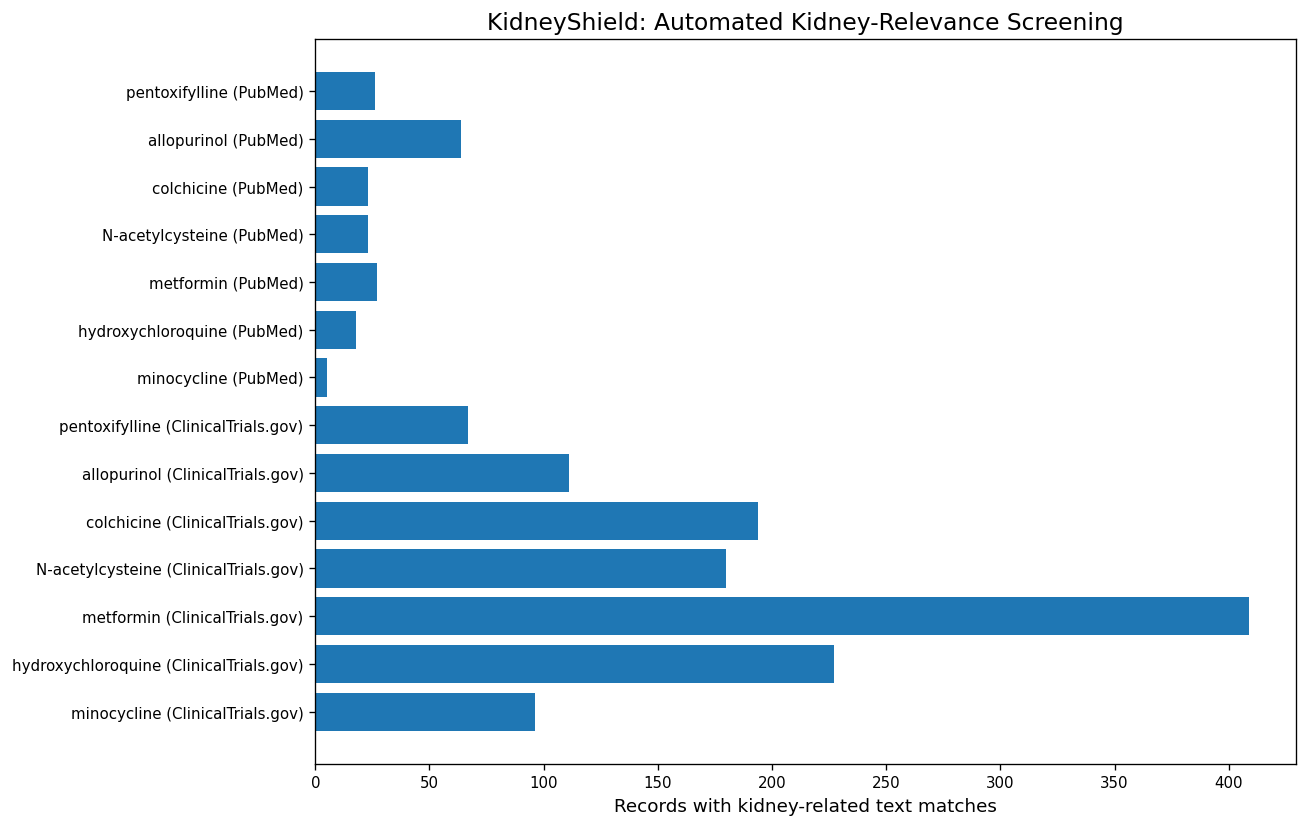

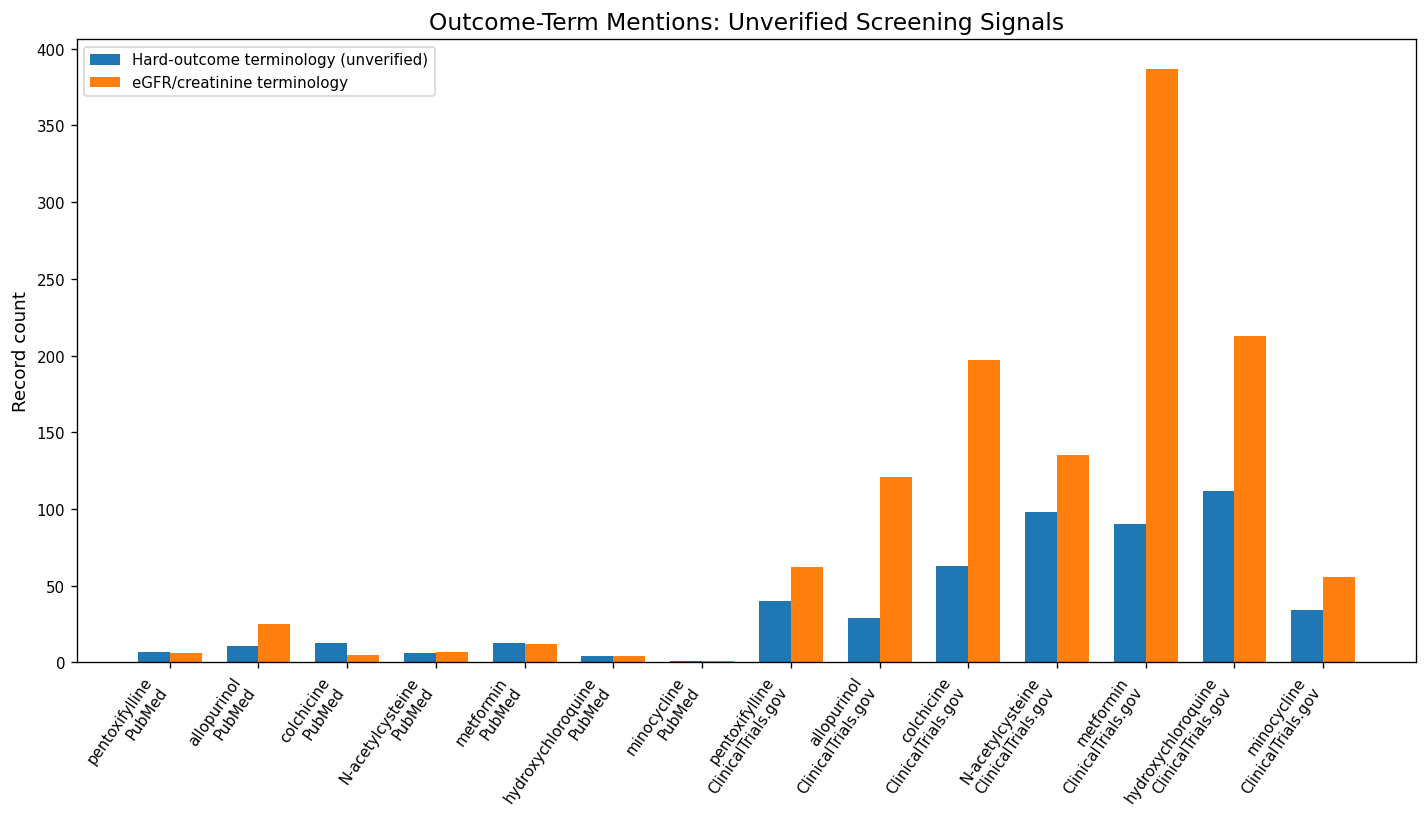


KIDNEYSHIELD — CELL 3 COMPLETE
PubMed records screened: 2087
PubMed kidney-relevance text matches: 186
PubMed manual-review queue: 207
Clinical trial records screened: 3350
Trial kidney-relevance text matches: 1277
Trial manual-review queue: 1649

Candidate screening summary:
            source          candidate  retrieved_records_assigned  kidney_relevance_text_matches  hard_outcome_mentions_not_verified  sustained_decline_mentions_not_verified  egfr_creatinine_mentions  albuminuria_proteinuria_mentions  safety_mentions  high_priority_manual_review                                interpretation
            PubMed     pentoxifylline                         298                             26                                   7                                        0                         6                                11               23                            7 Screening counts only; not efficacy evidence.
            PubMed        allopurinol                         298     

In [10]:

# ============================================================
# KIDNEYSHIELD | CELL 3 — CORRECTED
# Kidney relevance, outcome flags, review queues, and figures
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import zipfile

import pandas as pd
import matplotlib.pyplot as plt

# 1. Paths
ROOT = Path("/kaggle/working/kidneyshield")
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
LOGS = ROOT / "logs"

for folder in [PROCESSED, RESULTS, FIGURES, LOGS]:
    folder.mkdir(parents=True, exist_ok=True)

PUBMED_PATH = PROCESSED / "pubmed_records.csv"
TRIALS_PATH = PROCESSED / "clinical_trials.csv"

if not PUBMED_PATH.exists() or not TRIALS_PATH.exists():
    raise FileNotFoundError(
        "Cell 2 input files are missing. Run Cell 2 first."
    )

pubmed = pd.read_csv(PUBMED_PATH, dtype=str).fillna("")
trials = pd.read_csv(TRIALS_PATH, dtype=str).fillna("")

CANDIDATES = [
    "pentoxifylline", "allopurinol", "colchicine",
    "N-acetylcysteine", "metformin",
    "hydroxychloroquine", "minocycline",
]

print("PubMed records loaded:", len(pubmed))
print("Clinical trial records loaded:", len(trials))

# 2. Screening dictionaries
KIDNEY_TERMS = [
    r"\bchronic kidney disease\b", r"\bchronic renal disease\b",
    r"\bdiabetic kidney disease\b", r"\bdiabetic nephropath\w*\b",
    r"\bnephropath\w*\b", r"\bnephrolog\w*\b",
    r"\brenal insufficien\w*\b", r"\bkidney insufficien\w*\b",
    r"\brenal impairment\b", r"\bkidney impairment\b",
    r"\brenal function\b", r"\bkidney function\b",
    r"\bglomerul\w*\b", r"\bproteinuria\b", r"\balbuminuria\b",
    r"\bglomerular filtration\b", r"\beGFR\b",
    r"\bacute kidney injury\b", r"\bacute renal failure\b",
    r"\bchronic renal failure\b", r"\bkidney failure\b",
    r"\bend[- ]stage renal disease\b",
    r"\bend[- ]stage kidney disease\b",
    r"\bESRD\b", r"\bESKD\b", r"\bdialysis\b",
    r"\bkidney transplant\w*\b", r"\brenal transplant\w*\b",
]

HARD_OUTCOME_TERMS = [
    r"\bkidney failure\b", r"\brenal failure\b",
    r"\bend[- ]stage kidney disease\b",
    r"\bend[- ]stage renal disease\b",
    r"\bESKD\b", r"\bESRD\b", r"\bdialysis\b",
    r"\brenal replacement therapy\b",
    r"\bkidney transplant\w*\b", r"\brenal transplant\w*\b",
]

SUSTAINED_DECLINE_TERMS = [
    r"\bsustained decline\b", r"\bdecline in eGFR\b",
    r"\beGFR decline\b", r"\b40% decline\b", r"\b50% decline\b",
    r"\bdoubling of serum creatinine\b",
    r"\bdoubling of creatinine\b",
    r"\bsustained loss of kidney function\b",
    r"\bprogression of chronic kidney disease\b",
]

EGFR_TERMS = [
    r"\beGFR\b", r"\bestimated glomerular filtration rate\b",
    r"\bglomerular filtration rate\b", r"\bGFR\b",
    r"\bserum creatinine\b", r"\bcreatinine clearance\b",
]

ALBUMINURIA_TERMS = [
    r"\balbuminuria\b", r"\bproteinuria\b",
    r"\balbumin[- ]to[- ]creatinine ratio\b",
    r"\bUACR\b", r"\bUPCR\b",
    r"\burinary albumin\b", r"\burinary protein\b",
]

SAFETY_TERMS = [
    r"\badverse event\w*\b", r"\bserious adverse event\w*\b",
    r"\btoxicit\w*\b", r"\bsafety\b",
    r"\bwithdrawal due to\b", r"\bdiscontinu\w* due to adverse\b",
]

RANDOMIZED_TERMS = [
    r"\brandomi[sz]ed\b", r"\brandom allocation\b",
    r"\bcontrolled trial\b", r"\bplacebo[- ]controlled\b",
    r"\bdouble[- ]blind\b", r"\bsingle[- ]blind\b",
]

OBSERVATIONAL_TERMS = [
    r"\bcohort study\b", r"\bretrospective cohort\b",
    r"\bprospective cohort\b", r"\bcase[- ]control\b",
    r"\bcross[- ]sectional\b", r"\bobservational study\b",
    r"\bregistry[- ]based\b", r"\breal[- ]world\b",
]

REVIEW_TERMS = [
    r"\bsystematic review\b", r"\bmeta[- ]analysis\b",
    r"\bmeta analysis\b",
]

def has_pattern(text, patterns):
    text = str(text or "")
    return any(
        re.search(p, text, flags=re.IGNORECASE)
        for p in patterns
    )

def count_pattern_hits(text, patterns):
    text = str(text or "")
    return sum(
        bool(re.search(p, text, flags=re.IGNORECASE))
        for p in patterns
    )

def candidate_list(value):
    if not isinstance(value, str) or not value.strip():
        return []
    return [x.strip() for x in value.split(";") if x.strip()]

def pubmed_study_type(text, publication_types):
    combined = f"{text} {publication_types}"
    pub_types = str(publication_types).lower()

    if has_pattern(combined, REVIEW_TERMS) or \
       "systematic review" in pub_types or "meta-analysis" in pub_types:
        return "Review/meta-analysis signal"
    if has_pattern(combined, RANDOMIZED_TERMS) or \
       "randomized controlled trial" in pub_types:
        return "Randomized-trial signal"
    if has_pattern(combined, OBSERVATIONAL_TERMS):
        return "Observational-study signal"
    if "clinical trial" in pub_types:
        return "Clinical-trial publication-type signal"
    return "Other/unclear"

# 3. PubMed screening
pubmed_text_cols = [
    c for c in [
        "title", "abstract", "keywords", "publication_types", "journal"
    ] if c in pubmed.columns
]

pubmed["_screen_text"] = (
    pubmed[pubmed_text_cols].astype(str).agg(" ".join, axis=1)
)

if "candidate_matches" not in pubmed.columns:
    pubmed["candidate_matches"] = ""

pubmed["kidney_relevance_flag"] = pubmed["_screen_text"].apply(
    lambda x: has_pattern(x, KIDNEY_TERMS)
)
pubmed["kidney_term_match_count"] = pubmed["_screen_text"].apply(
    lambda x: count_pattern_hits(x, KIDNEY_TERMS)
)
pubmed["hard_outcome_mention_flag"] = pubmed["_screen_text"].apply(
    lambda x: has_pattern(x, HARD_OUTCOME_TERMS)
)
pubmed["sustained_decline_mention_flag"] = pubmed["_screen_text"].apply(
    lambda x: has_pattern(x, SUSTAINED_DECLINE_TERMS)
)
pubmed["egfr_creatinine_mention_flag"] = pubmed["_screen_text"].apply(
    lambda x: has_pattern(x, EGFR_TERMS)
)
pubmed["albuminuria_proteinuria_mention_flag"] = pubmed["_screen_text"].apply(
    lambda x: has_pattern(x, ALBUMINURIA_TERMS)
)
pubmed["safety_mention_flag"] = pubmed["_screen_text"].apply(
    lambda x: has_pattern(x, SAFETY_TERMS)
)
pubmed["study_type_signal"] = pubmed.apply(
    lambda r: pubmed_study_type(
        r.get("_screen_text", ""), r.get("publication_types", "")
    ), axis=1
)
pubmed["screening_status"] = pubmed["kidney_relevance_flag"].map({
    True: "Kidney-related text found — review",
    False: "No kidney keyword found — not yet excluded",
})
pubmed["manual_review_priority"] = (
    pubmed["kidney_relevance_flag"].astype(int) * 3
    + pubmed["hard_outcome_mention_flag"].astype(int) * 2
    + pubmed["sustained_decline_mention_flag"].astype(int) * 2
    + pubmed["egfr_creatinine_mention_flag"].astype(int)
    + pubmed["albuminuria_proteinuria_mention_flag"].astype(int)
)

def review_reason(row):
    checks = [
        ("kidney_relevance_flag", "kidney-related terminology"),
        ("hard_outcome_mention_flag", "hard-outcome terminology"),
        ("sustained_decline_mention_flag", "sustained-decline terminology"),
        ("egfr_creatinine_mention_flag", "eGFR/creatinine terminology"),
        ("albuminuria_proteinuria_mention_flag", "albuminuria/proteinuria terminology"),
    ]
    return "; ".join(label for key, label in checks if bool(row[key]))

pubmed["manual_review_reason"] = pubmed.apply(review_reason, axis=1)

# 4. ClinicalTrials.gov screening
trial_text_cols = [
    c for c in [
        "title", "official_title", "conditions", "interventions_json",
        "primary_outcomes", "secondary_outcomes",
        "eligibility_criteria", "study_type"
    ] if c in trials.columns
]

trials["_screen_text"] = (
    trials[trial_text_cols].astype(str).agg(" ".join, axis=1)
)

if "candidate_matches" not in trials.columns:
    trials["candidate_matches"] = ""

trials["kidney_relevance_flag"] = trials["_screen_text"].apply(
    lambda x: has_pattern(x, KIDNEY_TERMS)
)
trials["kidney_term_match_count"] = trials["_screen_text"].apply(
    lambda x: count_pattern_hits(x, KIDNEY_TERMS)
)
trials["hard_outcome_mention_flag"] = trials["_screen_text"].apply(
    lambda x: has_pattern(x, HARD_OUTCOME_TERMS)
)
trials["sustained_decline_mention_flag"] = trials["_screen_text"].apply(
    lambda x: has_pattern(x, SUSTAINED_DECLINE_TERMS)
)
trials["egfr_creatinine_mention_flag"] = trials["_screen_text"].apply(
    lambda x: has_pattern(x, EGFR_TERMS)
)
trials["albuminuria_proteinuria_mention_flag"] = trials["_screen_text"].apply(
    lambda x: has_pattern(x, ALBUMINURIA_TERMS)
)
trials["safety_mention_flag"] = trials["_screen_text"].apply(
    lambda x: has_pattern(x, SAFETY_TERMS)
)

def trial_study_type(row):
    value = str(row.get("study_type", "")).strip().upper()
    if value == "INTERVENTIONAL":
        return "Interventional trial"
    if value == "OBSERVATIONAL":
        return "Observational study"
    return value.title() if value else "Unclear"

trials["study_type_signal"] = trials.apply(trial_study_type, axis=1)
trials["screening_status"] = trials["kidney_relevance_flag"].map({
    True: "Kidney-related text found — review",
    False: "No kidney keyword found — not yet excluded",
})
trials["manual_review_priority"] = (
    trials["kidney_relevance_flag"].astype(int) * 3
    + trials["hard_outcome_mention_flag"].astype(int) * 2
    + trials["sustained_decline_mention_flag"].astype(int) * 2
    + trials["egfr_creatinine_mention_flag"].astype(int)
    + trials["albuminuria_proteinuria_mention_flag"].astype(int)
)
trials["manual_review_reason"] = trials.apply(review_reason, axis=1)

# 5. Save screened full tables
pubmed.drop(columns=["_screen_text"], errors="ignore").to_csv(
    PROCESSED / "pubmed_screened.csv",
    index=False, encoding="utf-8-sig"
)
trials.drop(columns=["_screen_text"], errors="ignore").to_csv(
    PROCESSED / "clinical_trials_screened.csv",
    index=False, encoding="utf-8-sig"
)

# 6. Review queues
pubmed_review = pubmed[
    pubmed["manual_review_priority"] > 0
].copy().sort_values("manual_review_priority", ascending=False)

trial_review = trials[
    trials["manual_review_priority"] > 0
].copy().sort_values("manual_review_priority", ascending=False)

pubmed_review.drop(columns=["_screen_text"], errors="ignore").to_csv(
    RESULTS / "pubmed_manual_review_queue.csv",
    index=False, encoding="utf-8-sig"
)
trial_review.drop(columns=["_screen_text"], errors="ignore").to_csv(
    RESULTS / "clinical_trials_manual_review_queue.csv",
    index=False, encoding="utf-8-sig"
)

# 7. Candidate-level summary: use stable, lowercase column names
summary_rows = []

for source_name, df in [
    ("PubMed", pubmed),
    ("ClinicalTrials.gov", trials),
]:
    for candidate in CANDIDATES:
        subset = df[
            df["candidate_matches"].apply(
                lambda value: candidate in candidate_list(value)
            )
        ]

        summary_rows.append({
            "source": source_name,
            "candidate": candidate,
            "retrieved_records_assigned": int(len(subset)),
            "kidney_relevance_text_matches": int(
                subset["kidney_relevance_flag"].sum()
            ),
            "hard_outcome_mentions_not_verified": int(
                subset["hard_outcome_mention_flag"].sum()
            ),
            "sustained_decline_mentions_not_verified": int(
                subset["sustained_decline_mention_flag"].sum()
            ),
            "egfr_creatinine_mentions": int(
                subset["egfr_creatinine_mention_flag"].sum()
            ),
            "albuminuria_proteinuria_mentions": int(
                subset["albuminuria_proteinuria_mention_flag"].sum()
            ),
            "safety_mentions": int(
                subset["safety_mention_flag"].sum()
            ),
            "high_priority_manual_review": int(
                (subset["manual_review_priority"] >= 5).sum()
            ),
            "interpretation": "Screening counts only; not efficacy evidence.",
        })

summary_df = pd.DataFrame(summary_rows)
summary_path = RESULTS / "candidate_screening_summary.csv"
summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")

screening_manifest = {
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "pubmed_records_loaded": int(len(pubmed)),
    "pubmed_kidney_relevance_text_matches": int(
        pubmed["kidney_relevance_flag"].sum()
    ),
    "pubmed_manual_review_queue": int(len(pubmed_review)),
    "clinical_trials_loaded": int(len(trials)),
    "trial_kidney_relevance_text_matches": int(
        trials["kidney_relevance_flag"].sum()
    ),
    "trial_manual_review_queue": int(len(trial_review)),
    "note": (
        "Keyword-based flags are unverified mentions. They do not establish "
        "that the endpoint was prespecified, measured, or improved."
    ),
}

with (LOGS / "screening_manifest.json").open("w", encoding="utf-8") as f:
    json.dump(screening_manifest, f, indent=2)

# 8. Figures — corrected, consistent lowercase column names
fig, ax = plt.subplots(figsize=(11, 7))
plot_df = summary_df.copy()
plot_df["label"] = plot_df["candidate"] + " (" + plot_df["source"] + ")"

ax.barh(
    plot_df["label"],
    plot_df["kidney_relevance_text_matches"]
)
ax.set_xlabel("Records with kidney-related text matches")
ax.set_title("KidneyShield: Automated Kidney-Relevance Screening")
ax.invert_yaxis()
fig.tight_layout()

fig1_path = FIGURES / "cell3_kidney_relevance_screening.png"
fig.savefig(fig1_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 7))
x = list(range(len(plot_df)))
width = 0.36

ax.bar(
    [i - width / 2 for i in x],
    plot_df["hard_outcome_mentions_not_verified"],
    width=width,
    label="Hard-outcome terminology (unverified)"
)
ax.bar(
    [i + width / 2 for i in x],
    plot_df["egfr_creatinine_mentions"],
    width=width,
    label="eGFR/creatinine terminology"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{r.candidate}\n{r.source}" for r in plot_df.itertuples()],
    rotation=55, ha="right"
)
ax.set_ylabel("Record count")
ax.set_title("Outcome-Term Mentions: Unverified Screening Signals")
ax.legend()
fig.tight_layout()

fig2_path = FIGURES / "cell3_outcome_term_mentions.png"
fig.savefig(fig2_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 9. Checkpoint ZIP outside the project directory
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
checkpoint_path = Path("/kaggle/working") / (
    f"KidneyShield_cell3_{timestamp}.zip"
)

with zipfile.ZipFile(
    checkpoint_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in ROOT.rglob("*"):
        if path.is_file() and not path.name.endswith(".tmp"):
            archive.write(path, arcname=path.relative_to(ROOT))

# 10. Update run manifest
run_manifest_path = LOGS / "run_manifest.json"
try:
    run_manifest = json.loads(
        run_manifest_path.read_text(encoding="utf-8")
    ) if run_manifest_path.exists() else {}
except Exception:
    run_manifest = {}

completed_cells = run_manifest.get("completed_cells", [])
if "cell_3" not in completed_cells:
    completed_cells.append("cell_3")

run_manifest.update({
    "updated_utc": datetime.now(timezone.utc).isoformat(),
    "completed_cells": completed_cells,
    "cell_3_status": "completed",
    "candidate_screening_summary": str(summary_path),
    "screening_manifest": str(LOGS / "screening_manifest.json"),
    "cell_3_checkpoint": str(checkpoint_path),
})

with run_manifest_path.open("w", encoding="utf-8") as f:
    json.dump(run_manifest, f, indent=2)

# 11. Final report
print("\n" + "=" * 65)
print("KIDNEYSHIELD — CELL 3 COMPLETE")
print("=" * 65)
print("PubMed records screened:", len(pubmed))
print("PubMed kidney-relevance text matches:",
      int(pubmed["kidney_relevance_flag"].sum()))
print("PubMed manual-review queue:", len(pubmed_review))
print("Clinical trial records screened:", len(trials))
print("Trial kidney-relevance text matches:",
      int(trials["kidney_relevance_flag"].sum()))
print("Trial manual-review queue:", len(trial_review))

print("\nCandidate screening summary:")
print(summary_df.to_string(index=False))

print("\nSaved outputs:")
print(" -", PROCESSED / "pubmed_screened.csv")
print(" -", PROCESSED / "clinical_trials_screened.csv")
print(" -", RESULTS / "pubmed_manual_review_queue.csv")
print(" -", RESULTS / "clinical_trials_manual_review_queue.csv")
print(" -", summary_path)
print(" -", fig1_path)
print(" -", fig2_path)
print(" -", LOGS / "screening_manifest.json")

print("\nCheckpoint:", checkpoint_path)
print("Checkpoint size (MB):", round(checkpoint_path.stat().st_size / 1e6, 2))
print("\nNOTE: These flags are screening signals, not verified efficacy.")
print("Save a new Kaggle notebook version and download the ZIP to your iPad.")

# KidneyShield — Cell 4: Kidney Visual Atlas

## Purpose

Build a small, source-attributed visual atlas for understanding kidney structure and glomerular filtration. The atlas includes:

1. **Kidney anatomy:** an illustration showing the kidney and an inset of a nephron.
2. **Nephron anatomy:** a separate illustration of the nephron.
3. **Kidney histology:** a microscopy image of stained kidney glomeruli, where the source is accessible.

## Data integrity and limitations

These are educational reference images, not patient-specific clinical evidence and not a labeled dataset for training or validating an AI model. A normal-appearing reference image must not be treated as representative of all healthy kidneys, and a histology image must not be labeled as chronic kidney disease unless its source explicitly establishes that diagnosis.

The notebook will preserve source URLs, attribution, image descriptions, and retrieval status in a catalog. It will also create a contact sheet and a ZIP checkpoint.

**Required attribution for NIDDK images:** National Institute of Diabetes and Digestive and Kidney Diseases, National Institutes of Health.

If an image source is unavailable, the cell should report that failure instead of silently substituting an unverified image.


OK: Kidney and nephron anatomy | 930 x 1200 | 190,554 bytes
OK: Nephron anatomy | 711 x 1027 | 108,613 bytes
OK: Stained kidney glomeruli | 1502 x 1127 | 738,458 bytes

Contact sheet saved: /kaggle/working/kidneyshield/results/figures/cell4_kidney_visual_atlas_contact_sheet.png


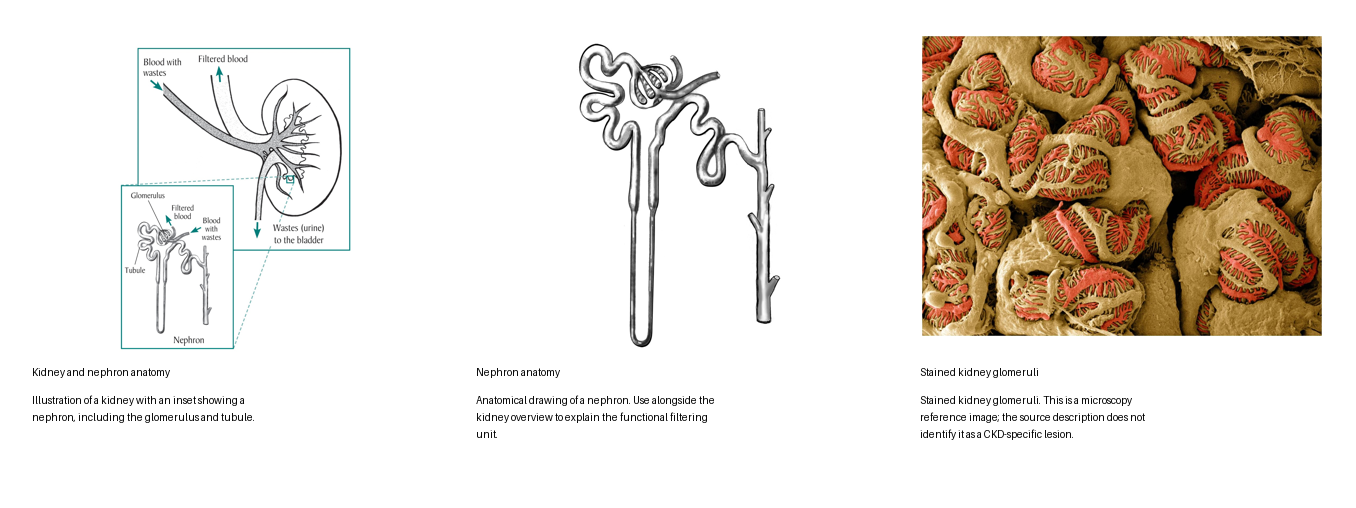


KIDNEYSHIELD — CELL 4 COMPLETE
Images attempted: 3
Images downloaded and validated: 3
Image retrieval failures: 0

Key outputs:
 - /kaggle/working/kidneyshield/results/medical_visuals/visual_atlas_catalog.csv
 - /kaggle/working/kidneyshield/results/medical_visuals/README_visual_atlas.md
 - /kaggle/working/kidneyshield/results/medical_visuals/index.html
 - /kaggle/working/kidneyshield/logs/visual_atlas_manifest.json
 - /kaggle/working/kidneyshield/results/figures/cell4_kidney_visual_atlas_contact_sheet.png

Checkpoint: /kaggle/working/KidneyShield_cell4_20261010_075044.zip
Checkpoint size (MB): 40.05


**Important:** The atlas is an educational visual component only. Review the catalog and original source pages before external redistribution. Save a new Kaggle notebook version and download the checkpoint ZIP to your iPad.

,title,visual_type,status,width_px,height_px,source_page,error
0,Kidney and nephron anatomy,Educational anatomy illustration,downloaded_and_validated,930,1200,https://www.niddk.nih.gov/news/media-library/1...,
1,Nephron anatomy,Educational anatomy illustration,downloaded_and_validated,711,1027,https://www.niddk.nih.gov/news/media-library/1...,
2,Stained kidney glomeruli,Microscopy / histology reference,downloaded_and_validated,1502,1127,https://nigms.nih.gov/image-gallery/3392,


In [11]:

# ================================================================
# KIDNEYSHIELD — CELL 4
# Kidney Visual Atlas: anatomy, nephron, and glomerular histology
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urlparse
import requests
import pandas as pd
import json
import zipfile
import shutil
import os
import re
import textwrap

from PIL import Image, ImageOps, ImageDraw
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

# -----------------------------
# 1. Paths and configuration
# -----------------------------
ROOT = Path("/kaggle/working/kidneyshield")
VISUAL_DIR = ROOT / "results" / "medical_visuals"
FIGURE_DIR = ROOT / "results" / "figures"
LOG_DIR = ROOT / "logs"
BACKUP_DIR = ROOT / "backups"

for folder in [VISUAL_DIR, FIGURE_DIR, LOG_DIR, BACKUP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

# -----------------------------
# 2. Source catalog
# -----------------------------
# Direct image URLs were identified from the official source pages.
# Histology is a stained-glomeruli reference image, NOT a CKD lesion image.
assets = [
    {
        "asset_id": "kidney_nephron_anatomy",
        "title": "Kidney and nephron anatomy",
        "filename": "kidney_nephron_anatomy_niddk.jpg",
        "url": "https://www.niddk.nih.gov/media-assets/18192/N01583-H.jpg",
        "source_page": "https://www.niddk.nih.gov/news/media-library/18192",
        "source_organization": "National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK), NIH",
        "attribution": "National Institute of Diabetes and Digestive and Kidney Diseases, National Institutes of Health.",
        "visual_type": "Educational anatomy illustration",
        "caption": (
            "Illustration of a kidney with an inset showing a nephron, "
            "including the glomerulus and tubule."
        ),
        "diagnostic_label": "Not applicable — educational illustration",
        "license_note": "NIDDK Media Library identifies these images as copyright-free for public use; preserve the requested attribution.",
        "intended_use": "Educational reference only; not model training or evaluation data."
    },
    {
        "asset_id": "nephron_anatomy",
        "title": "Nephron anatomy",
        "filename": "nephron_anatomy_niddk.jpg",
        "url": "https://www.niddk.nih.gov/media-assets/18193/N01585-H.jpg",
        "source_page": "https://www.niddk.nih.gov/news/media-library/18193",
        "source_organization": "National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK), NIH",
        "attribution": "National Institute of Diabetes and Digestive and Kidney Diseases, National Institutes of Health.",
        "visual_type": "Educational anatomy illustration",
        "caption": (
            "Anatomical drawing of a nephron. Use alongside the kidney overview "
            "to explain the functional filtering unit."
        ),
        "diagnostic_label": "Not applicable — educational illustration",
        "license_note": "NIDDK Media Library identifies these images as copyright-free for public use; preserve the requested attribution.",
        "intended_use": "Educational reference only; not model training or evaluation data."
    },
    {
        "asset_id": "stained_glomeruli_reference",
        "title": "Stained kidney glomeruli",
        "filename": "stained_kidney_glomeruli_nigms.jpg",
        "url": "https://www.nigms.nih.gov/sites/nigms/files/image-and-video-gallery/NCMIR_kidney_glomereolus.jpg",
        "source_page": "https://nigms.nih.gov/image-gallery/3392",
        "source_organization": "National Institute of General Medical Sciences (NIGMS), NIH; NCMIR",
        "attribution": "Image source credited by NIGMS to Tom Deerinck, National Center for Microscopy and Imaging Research (NCMIR).",
        "visual_type": "Microscopy / histology reference",
        "caption": (
            "Stained kidney glomeruli. This is a microscopy reference image; "
            "the source description does not identify it as a CKD-specific lesion."
        ),
        "diagnostic_label": "No CKD diagnosis inferred from this image",
        "license_note": "Check the source page for reuse terms before redistributing the image outside this research notebook.",
        "intended_use": "Visual education only; not model training or evaluation data."
    }
]

# -----------------------------
# 3. Download and validate files
# -----------------------------
session = requests.Session()
session.headers.update({
    "User-Agent": "KidneyShield-Educational-Atlas/1.0 (research notebook)"
})

catalog_rows = []

for asset in assets:
    output_path = VISUAL_DIR / asset["filename"]
    row = dict(asset)
    row.update({
        "retrieved_utc": datetime.now(timezone.utc).isoformat(),
        "status": "not_attempted",
        "http_status": None,
        "content_type": None,
        "file_size_bytes": None,
        "width_px": None,
        "height_px": None,
        "sha256": None,
        "local_path": str(output_path),
        "error": ""
    })

    try:
        response = session.get(asset["url"], timeout=45)
        row["http_status"] = response.status_code
        row["content_type"] = response.headers.get("Content-Type", "")

        response.raise_for_status()

        # Verify that the response is actually a decodable image.
        from io import BytesIO
        image = Image.open(BytesIO(response.content))
        image.load()

        if image.format not in ("JPEG", "PNG", "WEBP", "TIFF"):
            raise ValueError(f"Unexpected image format: {image.format}")

        # Preserve source pixels and image format; do not crop or relabel.
        image.save(output_path, format=image.format, quality=95 if image.format == "JPEG" else None)

        # Reopen saved image to validate output.
        with Image.open(output_path) as check_image:
            check_image.verify()

        with Image.open(output_path) as check_image:
            row["width_px"], row["height_px"] = check_image.size

        import hashlib
        row["sha256"] = hashlib.sha256(output_path.read_bytes()).hexdigest()
        row["file_size_bytes"] = output_path.stat().st_size
        row["status"] = "downloaded_and_validated"

        print(
            f"OK: {asset['title']} | "
            f"{row['width_px']} x {row['height_px']} | "
            f"{row['file_size_bytes']:,} bytes"
        )

    except Exception as exc:
        row["status"] = "failed"
        row["error"] = f"{type(exc).__name__}: {exc}"
        if output_path.exists():
            output_path.unlink()
        print(f"FAILED: {asset['title']} — {row['error']}")

    catalog_rows.append(row)

catalog = pd.DataFrame(catalog_rows)
catalog_path = VISUAL_DIR / "visual_atlas_catalog.csv"
catalog.to_csv(catalog_path, index=False)

# -----------------------------
# 4. Write attribution and use notes
# -----------------------------
notes = [
    "# KidneyShield — Kidney Visual Atlas",
    "",
    "## Purpose",
    "Educational reference images for kidney anatomy, nephron structure, and glomerular microscopy.",
    "",
    "## Important limits",
    "- These images are not a labeled patient cohort.",
    "- Do not use these images as model-training or model-evaluation data.",
    "- The stained-glomeruli image is not labeled as chronic kidney disease by this notebook.",
    "- Do not infer a diagnosis, disease severity, or drug response from these images.",
    "- Failed downloads are documented in `visual_atlas_catalog.csv`; no replacement image is silently substituted.",
    "",
    "## Attribution and sources",
    ""
]

for row in catalog_rows:
    notes.extend([
        f"### {row['title']}",
        f"- Retrieval status: `{row['status']}`",
        f"- Source organization: {row['source_organization']}",
        f"- Source page: {row['source_page']}",
        f"- Direct image URL: {row['url']}",
        f"- Caption: {row['caption']}",
        f"- Diagnostic label: {row['diagnostic_label']}",
        f"- Attribution: {row['attribution']}",
        f"- Reuse note: {row['license_note']}",
        ""
    ])

notes.extend([
    "## Attribution reminder",
    "For NIDDK images, retain this credit: National Institute of Diabetes and Digestive and Kidney Diseases, National Institutes of Health.",
    "",
    "## Separation from research datasets",
    "These visuals are included for human understanding and project presentation only. They are not part of the PubMed/ClinicalTrials.gov evidence corpus and must not be treated as training examples.",
    ""
])

readme_path = VISUAL_DIR / "README_visual_atlas.md"
readme_path.write_text("\n".join(notes), encoding="utf-8")

# -----------------------------
# 5. Generate a contact sheet
# -----------------------------
valid_assets = []

for row in catalog_rows:
    if row["status"] == "downloaded_and_validated":
        image_path = Path(row["local_path"])
        if image_path.exists():
            valid_assets.append((row, image_path))

contact_path = FIGURE_DIR / "cell4_kidney_visual_atlas_contact_sheet.png"

if valid_assets:
    tile_w, tile_h = 420, 460
    gap = 24
    columns = min(3, len(valid_assets))
    rows_n = (len(valid_assets) + columns - 1) // columns

    sheet = Image.new(
        "RGB",
        (columns * tile_w + (columns + 1) * gap,
         rows_n * tile_h + (rows_n + 1) * gap),
        "white"
    )
    draw = ImageDraw.Draw(sheet)

    for index, (row, image_path) in enumerate(valid_assets):
        col = index % columns
        row_index = index // columns
        x0 = gap + col * (tile_w + gap)
        y0 = gap + row_index * (tile_h + gap)

        with Image.open(image_path) as source_image:
            source_image = source_image.convert("RGB")
            thumb = ImageOps.contain(source_image, (tile_w - 20, 320))
            image_x = x0 + (tile_w - thumb.width) // 2
            image_y = y0 + 12
            sheet.paste(thumb, (image_x, image_y))

        title = row["title"]
        caption = row["caption"]
        draw.text((x0 + 8, y0 + 342), title, fill="black")
        wrapped = textwrap.wrap(caption, width=52)
        for line_i, line in enumerate(wrapped[:4]):
            draw.text((x0 + 8, y0 + 370 + line_i * 17), line, fill="black")

    sheet.save(contact_path)
    print(f"\nContact sheet saved: {contact_path}")
    display(sheet)
else:
    print("\nNo images downloaded successfully; contact sheet was not generated.")

# -----------------------------
# 6. Generate a simple HTML gallery
# -----------------------------
html_path = VISUAL_DIR / "index.html"

html_parts = [
    "<!doctype html>",
    '<html lang="en"><head><meta charset="utf-8">',
    '<meta name="viewport" content="width=device-width, initial-scale=1">',
    "<title>KidneyShield Visual Atlas</title>",
    "<style>body{font-family:Arial,sans-serif;max-width:1100px;margin:2rem auto;padding:0 1rem;color:#222}"
    ".grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(280px,1fr));gap:1.2rem}"
    "article{border:1px solid #ddd;border-radius:10px;padding:1rem}"
    "img{max-width:100%;max-height:480px;object-fit:contain;display:block;margin:auto}"
    "small{overflow-wrap:anywhere} .note{background:#f5f5f5;padding:1rem;border-radius:8px}</style>",
    "</head><body>",
    "<h1>KidneyShield — Kidney Visual Atlas</h1>",
    '<p class="note">Educational reference only. These images are not patient-level data, '
    "not labeled CKD training data, and not evidence of drug efficacy.</p>",
    '<div class="grid">'
]

for row in catalog_rows:
    html_parts.append("<article>")
    html_parts.append(f"<h2>{row['title']}</h2>")
    html_parts.append(f"<p><strong>Status:</strong> {row['status']}</p>")

    if row["status"] == "downloaded_and_validated":
        html_parts.append(f'<img src="{row["filename"]}" alt="{row["title"]}">')
    else:
        html_parts.append("<p>Image unavailable in this run; see the catalog for the error.</p>")

    html_parts.append(f"<p>{row['caption']}</p>")
    html_parts.append(f"<p><strong>Attribution:</strong> {row['attribution']}</p>")
    html_parts.append(f'<p><small><a href="{row["source_page"]}">Open original source page</a></small></p>')
    html_parts.append("</article>")

html_parts.extend(["</div>", "</body></html>"])
html_path.write_text("\n".join(html_parts), encoding="utf-8")

# -----------------------------
# 7. Update project manifest
# -----------------------------
manifest_path = LOG_DIR / "visual_atlas_manifest.json"

manifest = {
    "project": "KidneyShield",
    "cell": 4,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "purpose": "Educational kidney visual atlas",
    "assets_attempted": len(catalog_rows),
    "assets_downloaded_and_validated": sum(
        r["status"] == "downloaded_and_validated" for r in catalog_rows
    ),
    "assets_failed": sum(r["status"] == "failed" for r in catalog_rows),
    "catalog_csv": str(catalog_path),
    "readme": str(readme_path),
    "html_gallery": str(html_path),
    "contact_sheet": str(contact_path) if contact_path.exists() else None,
    "separation_note": (
        "Educational visuals are not to be used as model-training or evaluation data."
    ),
    "assets": [
        {
            "asset_id": r["asset_id"],
            "title": r["title"],
            "status": r["status"],
            "source_page": r["source_page"],
            "local_path": r["local_path"] if r["status"] == "downloaded_and_validated" else None,
            "error": r["error"]
        }
        for r in catalog_rows
    ]
}

manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

# -----------------------------
# 8. Update overall run manifest if present
# -----------------------------
run_manifest_path = LOG_DIR / "run_manifest.json"

if run_manifest_path.exists():
    try:
        run_manifest = json.loads(run_manifest_path.read_text(encoding="utf-8"))
    except Exception:
        run_manifest = {}

    run_manifest["cell4_visual_atlas"] = {
        "created_utc": manifest["created_utc"],
        "assets_attempted": manifest["assets_attempted"],
        "assets_downloaded_and_validated": manifest["assets_downloaded_and_validated"],
        "assets_failed": manifest["assets_failed"],
        "manifest_path": str(manifest_path)
    }
    run_manifest_path.write_text(json.dumps(run_manifest, indent=2), encoding="utf-8")

# -----------------------------
# 9. Create a checkpoint ZIP
# -----------------------------
checkpoint_path = Path(f"/kaggle/working/KidneyShield_cell4_{timestamp}.zip")

# Include the project folder; exclude caches and nested checkpoint ZIPs.
with zipfile.ZipFile(checkpoint_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in ROOT.rglob("*"):
        if not file_path.is_file():
            continue
        if "__pycache__" in file_path.parts:
            continue
        if file_path.suffix.lower() == ".pyc":
            continue
        # Avoid putting a prior project backup ZIP inside this checkpoint.
        if file_path.suffix.lower() == ".zip":
            continue
        zf.write(file_path, arcname=str(file_path.relative_to(ROOT.parent)))

print("\n" + "=" * 68)
print("KIDNEYSHIELD — CELL 4 COMPLETE")
print("=" * 68)
print(f"Images attempted: {manifest['assets_attempted']}")
print(f"Images downloaded and validated: {manifest['assets_downloaded_and_validated']}")
print(f"Image retrieval failures: {manifest['assets_failed']}")
print("\nKey outputs:")
print(f" - {catalog_path}")
print(f" - {readme_path}")
print(f" - {html_path}")
print(f" - {manifest_path}")
if contact_path.exists():
    print(f" - {contact_path}")
print(f"\nCheckpoint: {checkpoint_path}")
print(f"Checkpoint size (MB): {checkpoint_path.stat().st_size / (1024 * 1024):.2f}")

display(Markdown(
    "**Important:** The atlas is an educational visual component only. "
    "Review the catalog and original source pages before external redistribution. "
    "Save a new Kaggle notebook version and download the checkpoint ZIP to your iPad."
))

display(catalog[[
    "title", "visual_type", "status", "width_px", "height_px",
    "source_page", "error"
]])

# KidneyShield — Cell 5: Authentic Kidney Microscopy Reference Atlas

## Objective

Build a small, traceable reference gallery of real kidney research images from the official NIDDK Clinical Nephrology Section research page.

## Image coverage

* Normal glomerular architecture
* Membranous nephropathy biopsy histology
* Membranous nephropathy ultrastructure
* Normal glomerular capillary-wall ultrastructure
* Focal segmental glomerulosclerosis (FSGS)
* Anakinra-associated amyloid kidney biopsy composite

## Workflow

1. Retrieve the six source images from their recorded NIDDK media URLs.
2. Validate the HTTP response and image readability.
3. Record dimensions, file sizes, source URLs, titles, and image modality.
4. Create a contact sheet and HTML gallery for visual inspection.
5. Save a provenance README and retrieval manifest.
6. Create a checkpoint ZIP for download from Kaggle.

## Scientific limitations

These images are illustrative reference material, not a representative clinical dataset. They do not establish the number of independent patients or specimens, and they must not be used alone to train or validate a diagnostic model. Image labels, stain, magnification, specimen identifiers, and reuse permissions require confirmation from the source metadata where applicable.

**Source:** NIDDK Clinical Nephrology Section, National Institutes of Health. Retain attribution and verify reuse terms before redistribution.


KIDNEYSHIELD — AUTHENTIC KIDNEY MICROSCOPY ATLAS
Source page: https://www.niddk.nih.gov/research-funding/at-niddk/labs-branches/kidney-diseases-branch/clinical-nephrology-section/research
Images requested: 6

OK  01_normal_glomerular_architecture.png | 533x410 | 373.6 KB (already present)
OK  02_membranous_nephropathy_biopsy.jpg | 458x470 | 52.6 KB (already present)
OK  03_membranous_nephropathy_ultrastructure.png | 1551x1035 | 1289.0 KB (already present)
OK  04_normal_glomerular_capillary_wall.png | 609x602 | 416.7 KB (already present)
OK  05_fsgs_kidney_biopsy.png | 667x545 | 753.0 KB (already present)
OK  06_anakinra_associated_amyloid_biopsy.jpg | 1941x1000 | 267.0 KB (already present)


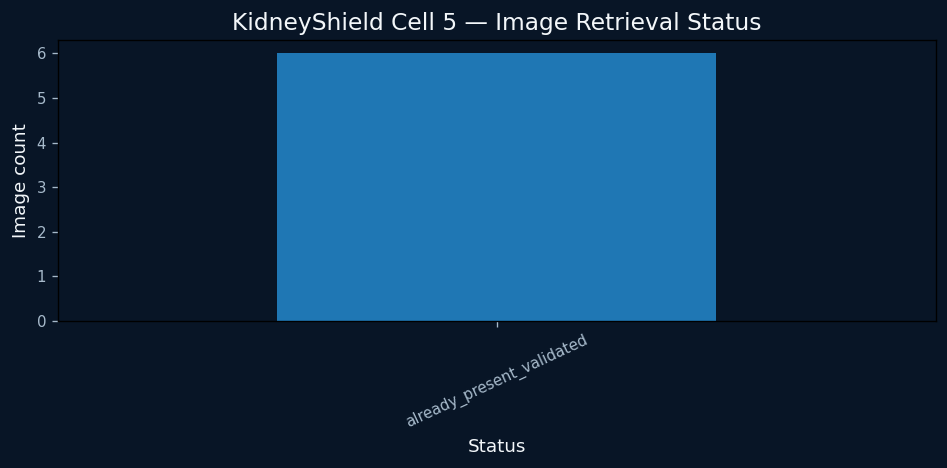


KIDNEYSHIELD — REAL MICROSCOPY ATLAS COMPLETE
Successfully validated: 6 / 6
Catalog: /kaggle/working/kidneyshield/results/medical_visuals/kidney_microscopy_catalog.csv
README: /kaggle/working/kidneyshield/results/medical_visuals/KIDNEY_MICROSCOPY_README.md
HTML gallery: /kaggle/working/kidneyshield/results/medical_visuals/kidney_microscopy_gallery.html
Contact sheet: /kaggle/working/kidneyshield/results/medical_visuals/kidney_microscopy_contact_sheet.png
Manifest: /kaggle/working/kidneyshield/logs/kidney_microscopy_manifest.json
Checkpoint ZIP: /kaggle/working/KidneyShield_cell5_20261010_080513.zip
Checkpoint size: 4.35 MB



,title,modality,width_px,height_px,download_status,source_url
0,Normal glomerular architecture,Kidney biopsy histology,533,410,already_present_validated,https://www.niddk.nih.gov/-/media/Images/labs-...
1,Kidney biopsy: membranous nephropathy,Kidney biopsy histology,458,470,already_present_validated,https://www.niddk.nih.gov/-/media/Images/labs-...
2,Membranous nephropathy ultrastructure,Electron microscopy,1551,1035,already_present_validated,https://www.niddk.nih.gov/-/media/Images/labs-...
3,Normal glomerular capillary-wall ultrastructure,Electron microscopy,609,602,already_present_validated,https://www.niddk.nih.gov/-/media/Images/labs-...
4,Kidney biopsy: focal segmental glomerulosclerosis,Kidney biopsy histology,667,545,already_present_validated,https://www.niddk.nih.gov/-/media/Images/labs-...
5,Kidney biopsy: anakinra-associated amyloid,Histology and electron microscopy composite,1941,1000,already_present_validated,https://www.niddk.nih.gov/-/media/Images/labs-...


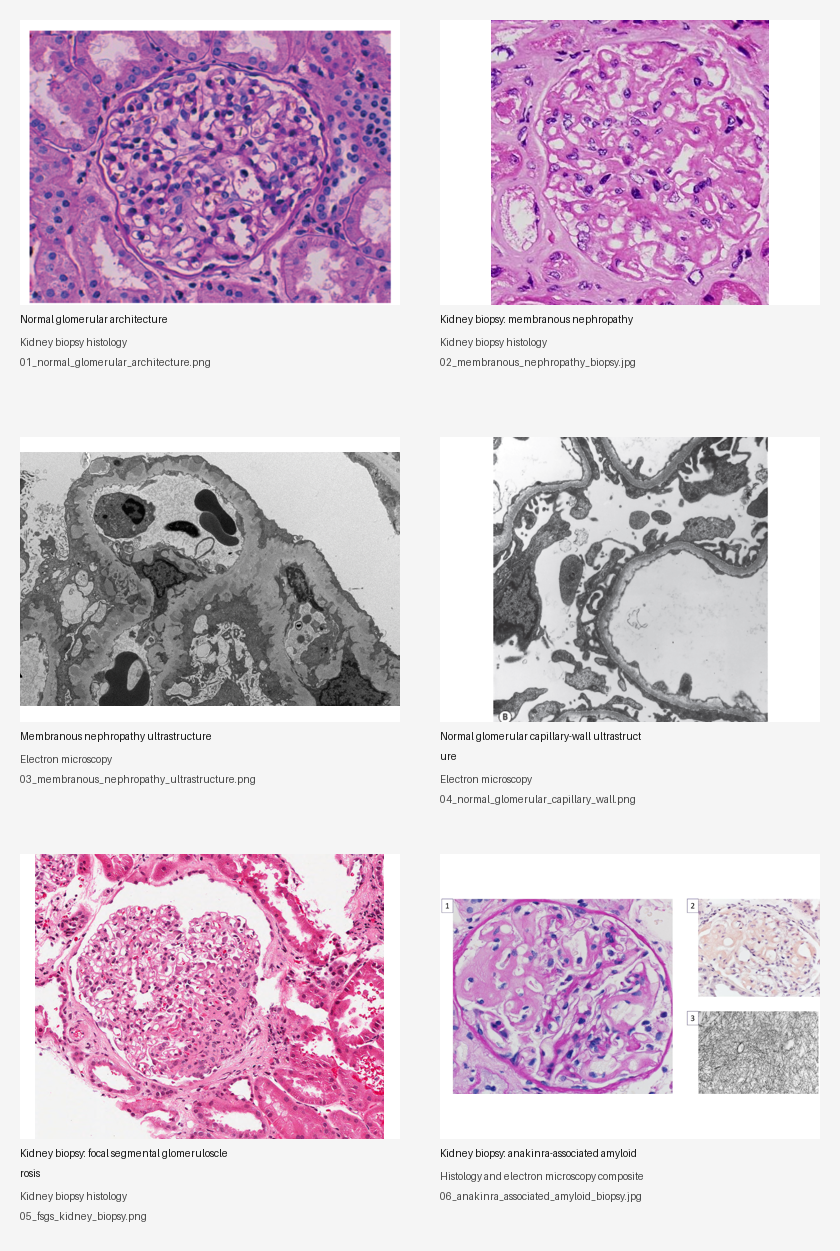

In [17]:

# ============================================================
# KIDNEYSHIELD — CELL 5B
# Authentic kidney microscopy image acquisition + gallery
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from io import BytesIO
import requests
import pandas as pd
import numpy as np
import json
import zipfile
import hashlib
import time
import re
import os

from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. Project folders
# ------------------------------------------------------------
ROOT = Path("/kaggle/working/kidneyshield")
VIS = ROOT / "results" / "medical_visuals"
FIG = ROOT / "results" / "figures"
LOGS = ROOT / "logs"
RAW = ROOT / "data" / "raw" / "kidney_microscopy"

for folder in [VIS, FIG, LOGS, RAW]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

SOURCE_PAGE = (
    "https://www.niddk.nih.gov/research-funding/at-niddk/"
    "labs-branches/kidney-diseases-branch/"
    "clinical-nephrology-section/research"
)

# ------------------------------------------------------------
# 2. Official NIDDK source images
# ------------------------------------------------------------
# These URLs correspond to the six images reported as successfully
# downloaded in the previous Cell 5 run.

IMAGE_SPECS = [
    {
        "filename": "01_normal_glomerular_architecture.png",
        "title": "Normal glomerular architecture",
        "modality": "Kidney biopsy histology",
        "description": "Normal glomerular capillary-loop architecture.",
        "url": (
            "https://www.niddk.nih.gov/-/media/Images/labs-branches-sections/"
            "kidney-disease-branch/clinical-nephrology-section/"
            "research-images/normal-glomerular-architecture_533x410.png"
        ),
    },
    {
        "filename": "02_membranous_nephropathy_biopsy.jpg",
        "title": "Kidney biopsy: membranous nephropathy",
        "modality": "Kidney biopsy histology",
        "description": (
            "Biopsy image illustrating thickening of glomerular capillary loops."
        ),
        "url": (
            "https://www.niddk.nih.gov/-/media/Images/labs-branches-sections/"
            "kidney-disease-branch/clinical-nephrology-section/"
            "research-images/kidney-biopsy-membranous-nephropathy_458x470.jpg"
        ),
    },
    {
        "filename": "03_membranous_nephropathy_ultrastructure.png",
        "title": "Membranous nephropathy ultrastructure",
        "modality": "Electron microscopy",
        "description": (
            "Ultrastructural view illustrating deposits associated with "
            "membranous nephropathy."
        ),
        "url": (
            "https://www.niddk.nih.gov/-/media/Images/labs-branches-sections/"
            "kidney-disease-branch/clinical-nephrology-section/"
            "research-images/membranous-nephropathy_1551x1035.png"
        ),
    },
    {
        "filename": "04_normal_glomerular_capillary_wall.png",
        "title": "Normal glomerular capillary-wall ultrastructure",
        "modality": "Electron microscopy",
        "description": (
            "Normal glomerular capillary-wall ultrastructure for comparison."
        ),
        "url": (
            "https://www.niddk.nih.gov/-/media/Images/labs-branches-sections/"
            "kidney-disease-branch/clinical-nephrology-section/"
            "research-images/ultrastructure-normal-glomerular-capillary_609x602.png"
        ),
    },
    {
        "filename": "05_fsgs_kidney_biopsy.png",
        "title": "Kidney biopsy: focal segmental glomerulosclerosis",
        "modality": "Kidney biopsy histology",
        "description": (
            "Biopsy image illustrating focal and segmental glomerular scarring."
        ),
        "url": (
            "https://www.niddk.nih.gov/-/media/Images/labs-branches-sections/"
            "kidney-disease-branch/clinical-nephrology-section/"
            "research-images/kidney-biopsy-fsgs_667x545.png"
        ),
    },
    {
        "filename": "06_anakinra_associated_amyloid_biopsy.jpg",
        "title": "Kidney biopsy: anakinra-associated amyloid",
        "modality": "Histology and electron microscopy composite",
        "description": (
            "Composite showing kidney biopsy findings associated with amyloid."
        ),
        "url": (
            "https://www.niddk.nih.gov/-/media/Images/labs-branches-sections/"
            "kidney-disease-branch/clinical-nephrology-section/"
            "research-images/kidney-biopsy-anakinra-associated-amyloid_1941x1000.jpg"
        ),
    },
]

# ------------------------------------------------------------
# 3. Request configuration
# ------------------------------------------------------------
session = requests.Session()
session.headers.update({
    "User-Agent": "KidneyShield-Research-Prototype/0.1",
    "Accept": "image/avif,image/webp,image/apng,image/*,*/*;q=0.8",
})

REQUEST_TIMEOUT = 45
MAX_IMAGE_BYTES = 40 * 1024 * 1024

# ------------------------------------------------------------
# 4. Download and validate
# ------------------------------------------------------------
catalog_rows = []
download_errors = []

print("=" * 72)
print("KIDNEYSHIELD — AUTHENTIC KIDNEY MICROSCOPY ATLAS")
print("=" * 72)
print("Source page:", SOURCE_PAGE)
print("Images requested:", len(IMAGE_SPECS))
print()

for spec in IMAGE_SPECS:
    filename = spec["filename"]
    destination = VIS / filename

    row = {
        "filename": filename,
        "title": spec["title"],
        "modality": spec["modality"],
        "description": spec["description"],
        "source_url": spec["url"],
        "source_page": SOURCE_PAGE,
        "credit": "National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK), NIH",
        "download_status": "failed",
        "http_status": None,
        "width_px": None,
        "height_px": None,
        "format": None,
        "file_size_bytes": None,
        "sha256": None,
        "local_path": str(destination),
        "reuse_terms_verified": False,
        "diagnostic_training_approved": False,
    }

    try:
        # Reuse an existing valid image rather than needlessly downloading it.
        if destination.exists():
            try:
                with Image.open(destination) as existing:
                    existing.verify()
                with Image.open(destination) as existing:
                    width, height = existing.size
                    image_format = existing.format

                row.update({
                    "download_status": "already_present_validated",
                    "width_px": width,
                    "height_px": height,
                    "format": image_format,
                    "file_size_bytes": destination.stat().st_size,
                    "sha256": hashlib.sha256(
                        destination.read_bytes()
                    ).hexdigest(),
                })
                print(
                    f"OK  {filename} | {width}x{height} | "
                    f"{destination.stat().st_size / 1024:.1f} KB "
                    "(already present)"
                )
                catalog_rows.append(row)
                continue

            except Exception:
                # If the existing file is corrupt, redownload it.
                destination.unlink(missing_ok=True)

        response = session.get(
            spec["url"],
            timeout=REQUEST_TIMEOUT,
            allow_redirects=True,
        )
        row["http_status"] = response.status_code

        if response.status_code != 200:
            raise RuntimeError(
                f"HTTP {response.status_code}: {response.text[:150]}"
            )

        content_type = response.headers.get("Content-Type", "").lower()
        content = response.content

        if not content:
            raise ValueError("The server returned an empty response.")

        if len(content) > MAX_IMAGE_BYTES:
            raise ValueError(
                f"Image exceeds size limit: {len(content)} bytes"
            )

        # Decode and verify the actual image, not merely the URL extension.
        with Image.open(BytesIO(content)) as im:
            im.verify()

        with Image.open(BytesIO(content)) as im:
            width, height = im.size
            image_format = im.format

        if width < 100 or height < 100:
            raise ValueError(
                f"Unexpectedly small image: {width}x{height}"
            )

        # Save only after validation.
        destination.write_bytes(content)

        row.update({
            "download_status": "downloaded",
            "width_px": width,
            "height_px": height,
            "format": image_format,
            "file_size_bytes": len(content),
            "sha256": hashlib.sha256(content).hexdigest(),
            "content_type": content_type,
            "final_response_url": response.url,
        })

        print(
            f"OK  {filename} | {width}x{height} | "
            f"{len(content) / 1024:.1f} KB"
        )

    except Exception as exc:
        row["error"] = repr(exc)
        download_errors.append({
            "filename": filename,
            "source_url": spec["url"],
            "error": repr(exc),
        })
        print(f"FAIL {filename} | {exc}")

    catalog_rows.append(row)
    time.sleep(0.25)

# ------------------------------------------------------------
# 5. Save image catalog and error log
# ------------------------------------------------------------
catalog = pd.DataFrame(catalog_rows)

catalog_path = VIS / "kidney_microscopy_catalog.csv"
catalog.to_csv(catalog_path, index=False)

errors_path = LOGS / f"kidney_microscopy_download_errors_{RUN_ID}.json"
with open(errors_path, "w", encoding="utf-8") as f:
    json.dump(download_errors, f, indent=2, ensure_ascii=False)

# ------------------------------------------------------------
# 6. Build contact sheet from successfully validated images
# ------------------------------------------------------------
valid_images = []

for row in catalog_rows:
    path = Path(row["local_path"])

    if not path.exists():
        continue

    try:
        with Image.open(path) as im:
            im.load()
            valid_images.append({
                "path": path,
                "title": row["title"],
                "modality": row["modality"],
                "image": im.convert("RGB").copy(),
            })
    except Exception as exc:
        print("Contact-sheet skip:", path.name, repr(exc))

THUMB_W = 380
THUMB_H = 285
LABEL_H = 92
PADDING = 20
COLS = 2

if valid_images:
    rows_n = (len(valid_images) + COLS - 1) // COLS
    cell_w = THUMB_W + 2 * PADDING
    cell_h = THUMB_H + LABEL_H + 2 * PADDING

    sheet = Image.new(
        "RGB",
        (COLS * cell_w, rows_n * cell_h),
        color=(245, 245, 245),
    )
    draw = ImageDraw.Draw(sheet)

    try:
        font_title = ImageFont.truetype("DejaVuSans.ttf", 15)
        font_small = ImageFont.truetype("DejaVuSans.ttf", 12)
    except Exception:
        font_title = ImageFont.load_default()
        font_small = ImageFont.load_default()

    for idx, item in enumerate(valid_images):
        r = idx // COLS
        c = idx % COLS
        x = c * cell_w + PADDING
        y = r * cell_h + PADDING

        thumb = ImageOps.contain(
            item["image"],
            (THUMB_W, THUMB_H),
        )

        # Center thumbnail in a fixed display region.
        thumb_canvas = Image.new(
            "RGB", (THUMB_W, THUMB_H), (255, 255, 255)
        )
        thumb_x = (THUMB_W - thumb.width) // 2
        thumb_y = (THUMB_H - thumb.height) // 2
        thumb_canvas.paste(thumb, (thumb_x, thumb_y))

        sheet.paste(thumb_canvas, (x, y))
        text_y = y + THUMB_H + 8

        # Wrap labels to fit the card.
        title = item["title"]
        max_chars = 44
        title_lines = [
            title[i:i + max_chars]
            for i in range(0, len(title), max_chars)
        ][:2]

        for line in title_lines:
            draw.text(
                (x, text_y),
                line,
                fill=(20, 20, 20),
                font=font_title,
            )
            text_y += 20

        draw.text(
            (x, text_y + 3),
            item["modality"],
            fill=(70, 70, 70),
            font=font_small,
        )
        draw.text(
            (x, text_y + 23),
            item["path"].name,
            fill=(70, 70, 70),
            font=font_small,
        )

    contact_path = VIS / "kidney_microscopy_contact_sheet.png"
    sheet.save(contact_path, quality=92)
else:
    contact_path = None
    print("No valid images available for the contact sheet.")

# ------------------------------------------------------------
# 7. Create HTML gallery for notebook/browser inspection
# ------------------------------------------------------------
gallery_path = VIS / "kidney_microscopy_gallery.html"

html_parts = [
    "<!DOCTYPE html>",
    '<html lang="en"><head><meta charset="utf-8">',
    "<meta name='viewport' content='width=device-width, initial-scale=1'>",
    "<title>KidneyShield Microscopy Reference Atlas</title>",
    """
    <style>
      body { font-family: Arial, sans-serif; margin: 24px; color: #202124; }
      h1 { margin-bottom: 6px; }
      .notice { padding: 12px; background: #f1f3f4; margin: 16px 0; }
      .grid { display: grid; grid-template-columns: repeat(auto-fit,minmax(280px,1fr)); gap: 18px; }
      .card { border: 1px solid #ddd; padding: 12px; border-radius: 8px; }
      img { max-width: 100%; max-height: 360px; object-fit: contain; display: block; margin: 0 auto; }
      .meta { font-size: 13px; overflow-wrap: anywhere; }
    </style></head><body>
    """,
    "<h1>KidneyShield — Kidney Microscopy Reference Atlas</h1>",
    f"<p>Generated UTC: {datetime.now(timezone.utc).isoformat()}</p>",
    """
    <div class="notice">
    <strong>Research limitation:</strong> This is a small illustrative
    reference gallery, not a representative or independently labeled
    clinical dataset. Verify each image's metadata and reuse terms before
    redistribution or machine-learning use.
    </div>
    """,
    "<div class='grid'>",
]

for row in catalog_rows:
    path = Path(row["local_path"])
    if not path.exists():
        continue

    title = row["title"]
    modality = row["modality"]
    source = row["source_url"]
    escaped_title = (
        title.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    )

    html_parts.append(f"""
      <div class="card">
        <h3>{escaped_title}</h3>
        <img src="{path.name}" alt="{escaped_title}">
        <p class="meta"><strong>Modality:</strong> {modality}</p>
        <p class="meta"><strong>File:</strong> {path.name}</p>
        <p class="meta"><a href="{source}">Original source image</a></p>
      </div>
    """)

html_parts.extend([
    "</div>",
    f"<p>Source page: <a href='{SOURCE_PAGE}'>{SOURCE_PAGE}</a></p>",
    "<p>Credit: NIDDK, National Institutes of Health, where applicable.</p>",
    "</body></html>",
])

gallery_path.write_text("\n".join(html_parts), encoding="utf-8")

# ------------------------------------------------------------
# 8. Create provenance README
# ------------------------------------------------------------
readme_path = VIS / "KIDNEY_MICROSCOPY_README.md"

readme = f"""# KidneyShield — Kidney Microscopy Reference Atlas

Generated: {datetime.now(timezone.utc).isoformat()}

## Source

NIDDK Clinical Nephrology Section research images:

{SOURCE_PAGE}

## Image inventory

"""

for row in catalog_rows:
    readme += (
        f"- **{row['title']}** (`{row['filename']}`)\\n"
        f"  - Modality: {row['modality']}\\n"
        f"  - Status: {row['download_status']}\\n"
        f"  - Dimensions: {row.get('width_px')} × {row.get('height_px')} px\\n"
        f"  - Source: {row['source_url']}\\n"
    )

readme += """
## Attribution and reuse

Credit the National Institute of Diabetes and Digestive and Kidney Diseases
(NIDDK), National Institutes of Health (NIH), for relevant images.

A source page or successful download does not automatically establish that
every image is unrestricted for redistribution. Confirm the applicable
reuse terms and any third-party rights before publishing or redistributing
these files.

## Scientific limitations

- This atlas is an illustrative collection, not a representative dataset.
- Image count is not patient count or independent specimen count.
- Titles are source descriptions, not independently validated labels.
- Do not infer a stain, magnification, diagnosis, or patient grouping when
  the source does not verify it.
- Do not use these images alone to train or validate a clinical diagnostic
  model.
- Any future train/test split must group related images at the patient or
  specimen level when those identifiers are available.
- Image pixels and visual appearance are not a substitute for expert
  pathology interpretation.

## Files generated

- `kidney_microscopy_catalog.csv`
- `kidney_microscopy_contact_sheet.png` (when images validate)
- `kidney_microscopy_gallery.html`
- `KIDNEY_MICROSCOPY_README.md`
- `kidney_microscopy_manifest.json`
"""

readme_path.write_text(readme, encoding="utf-8")

# ------------------------------------------------------------
# 9. Retrieval manifest
# ------------------------------------------------------------
manifest = {
    "project": "KidneyShield",
    "cell": "Cell 5B",
    "run_id": RUN_ID,
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "source_page": SOURCE_PAGE,
    "images_requested": len(IMAGE_SPECS),
    "images_validated": len(valid_images),
    "images_failed": len(download_errors),
    "catalog_path": str(catalog_path),
    "contact_sheet_path": str(contact_path) if contact_path else None,
    "gallery_path": str(gallery_path),
    "readme_path": str(readme_path),
    "errors_path": str(errors_path),
    "images": catalog_rows,
    "limitations": [
        "Illustrative reference atlas, not a representative clinical dataset.",
        "Successful retrieval does not confirm redistribution permission.",
        "Image titles do not constitute independently validated diagnostic labels.",
        "No model training or diagnostic evaluation performed."
    ],
}

manifest_path = LOGS / "kidney_microscopy_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False, default=str)

# ------------------------------------------------------------
# 10. Save a small run summary figure
# ------------------------------------------------------------
if not catalog.empty:
    status_counts = catalog["download_status"].value_counts()
    fig_path = FIG / "cell5_microscopy_download_summary.png"

    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8, 4))
    status_counts.plot(kind="bar", ax=ax)
    ax.set_title("KidneyShield Cell 5 — Image Retrieval Status")
    ax.set_xlabel("Status")
    ax.set_ylabel("Image count")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(fig_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 11. Checkpoint ZIP
# ------------------------------------------------------------
checkpoint_path = Path(
    f"/kaggle/working/KidneyShield_cell5_{RUN_ID}.zip"
)

# Include project files useful for continuing the notebook.
# Exclude old checkpoint ZIPs so the new archive does not grow recursively.
files_to_include = [
    catalog_path,
    gallery_path,
    readme_path,
    manifest_path,
    errors_path,
]

if contact_path and Path(contact_path).exists():
    files_to_include.append(Path(contact_path))

fig_path = FIG / "cell5_microscopy_download_summary.png"
if fig_path.exists():
    files_to_include.append(fig_path)

for row in catalog_rows:
    path = Path(row["local_path"])
    if path.exists():
        files_to_include.append(path)

with zipfile.ZipFile(
    checkpoint_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=5,
) as zf:
    for path in dict.fromkeys(files_to_include):
        if path.exists() and path.is_file():
            try:
                arcname = path.relative_to(ROOT)
            except ValueError:
                arcname = Path("external") / path.name
            zf.write(path, arcname=str(arcname))

# ------------------------------------------------------------
# 12. Display results
# ------------------------------------------------------------
print()
print("=" * 72)
print("KIDNEYSHIELD — REAL MICROSCOPY ATLAS COMPLETE")
print("=" * 72)

successful = sum(
    1 for row in catalog_rows
    if str(row["download_status"]).startswith("downloaded")
    or row["download_status"] == "already_present_validated"
)

print(f"Successfully validated: {successful} / {len(IMAGE_SPECS)}")
print("Catalog:", catalog_path)
print("README:", readme_path)
print("HTML gallery:", gallery_path)
print("Contact sheet:", contact_path)
print("Manifest:", manifest_path)
print("Checkpoint ZIP:", checkpoint_path)
print("Checkpoint size: %.2f MB" % (checkpoint_path.stat().st_size / 1e6))

print()
display(catalog[[
    "title",
    "modality",
    "width_px",
    "height_px",
    "download_status",
    "source_url",
]])

if contact_path and Path(contact_path).exists():
    display(Image.open(contact_path))

display(HTML(
    "<p><strong>Reminder:</strong> Preserve attribution and verify reuse "
    "permissions. This reference atlas is not sufficient by itself for "
    "diagnostic model training or validation.</p>"
))

# KidneyShield — Cell 6: Dataset Readiness & Provenance Audit

## Objective

Audit the authentic kidney microscopy reference images and supporting catalog before selecting data for any machine-learning experiment.

## Tasks

1. Inventory original microscopy image files.
2. Verify image readability, dimensions, formats, and file sizes.
3. Calculate SHA-256 hashes to detect exact duplicate files.
4. Match files against the Cell 5 microscopy catalog where possible.
5. Create a human annotation template for source, specimen, stain, modality, diagnosis, and reuse permissions.
6. Assess whether available metadata is sufficient for a defensible training dataset.
7. Export a dataset-readiness report and a checkpoint ZIP.

## Scientific safeguards

* A file hash identifies identical file contents; it does not establish whether two images came from the same patient.
* Different crops or images from one specimen may still be related.
* Image titles are not independently validated diagnostic labels.
* Do not assume that a downloaded image is licensed for redistribution or machine-learning use.
* Do not infer stain, magnification, specimen identity, or diagnosis from image pixels alone.
* Do not create training/test splits until specimen or patient grouping and the intended evaluation task are defined.

## Outputs

* `original_image_inventory.csv`
* `human_annotation_template.csv`
* `dataset_readiness_audit.csv`
* `dataset_readiness_summary.json`
* `DATASET_READINESS_REPORT.md`
* A timestamped checkpoint ZIP

## Completion criterion

The audit is complete when the files are inventoried and the missing metadata is explicitly documented. An incomplete metadata record is a finding to resolve—not a reason to guess.


In [18]:

# ============================================================
# KIDNEYSHIELD — CELL 6B
# Dataset readiness, image integrity, and provenance audit
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
from PIL import Image, ImageStat
import pandas as pd
import numpy as np
import hashlib
import json
import zipfile
import re
import os

# ------------------------------------------------------------
# 1. Paths and run configuration
# ------------------------------------------------------------
ROOT = Path("/kaggle/working/kidneyshield")
VIS = ROOT / "results" / "medical_visuals"
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"

for folder in [VIS, RAW, PROCESSED, RESULTS, LOGS]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

CATALOG_PATH = VIS / "kidney_microscopy_catalog.csv"

# Image extensions accepted for inventory.
IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff",
    ".bmp", ".webp"
}

# Folders and files generated by this audit or by visualization
# steps should not be mistaken for original source images.
EXCLUDED_DIR_NAMES = {
    "qc_tiles",
    "thumbnails",
    "derived",
    "generated",
    "augmented",
    "contact_sheets",
}

EXCLUDED_FILE_PATTERNS = [
    r"contact[_-]?sheet",
    r"tile[_-]?\d+",
    r"thumbnail",
    r"microscopy_qc_tile_explorer",
    r"cell\d+_.*\.png$",
    r"schematic",
]

def is_generated_or_derived(path):
    if any(part.lower() in EXCLUDED_DIR_NAMES for part in path.parts):
        return True

    name = path.name.lower()
    return any(
        re.search(pattern, name)
        for pattern in EXCLUDED_FILE_PATTERNS
    )

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def safe_text(value):
    if value is None:
        return ""
    if isinstance(value, float) and pd.isna(value):
        return ""
    return str(value).strip()

def parse_boolish(value):
    text = safe_text(value).lower()
    return text in {"yes", "true", "verified", "confirmed", "approved"}

# ------------------------------------------------------------
# 2. Load Cell 5 catalog if available
# ------------------------------------------------------------
catalog_lookup = {}
catalog_available = CATALOG_PATH.exists()

if catalog_available:
    try:
        source_catalog = pd.read_csv(CATALOG_PATH).fillna("")
        for _, row in source_catalog.iterrows():
            local_path = safe_text(row.get("local_path", ""))
            filename = safe_text(row.get("filename", ""))

            keys = set()
            if local_path:
                keys.add(Path(local_path).name.lower())
            if filename:
                keys.add(Path(filename).name.lower())

            for key in keys:
                catalog_lookup[key] = row.to_dict()

        print("Loaded Cell 5 catalog:", CATALOG_PATH)
        print("Catalog records:", len(source_catalog))

    except Exception as exc:
        source_catalog = pd.DataFrame()
        print("WARNING: Could not read Cell 5 catalog:", repr(exc))
else:
    source_catalog = pd.DataFrame()
    print("WARNING: Cell 5 catalog not found:", CATALOG_PATH)

# ------------------------------------------------------------
# 3. Inventory image files
# ------------------------------------------------------------
# Restrict this inventory to the microscopy reference directory.
# Do not automatically treat every image elsewhere in the project
# as part of the source dataset.

image_paths = []

for path in VIS.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    if is_generated_or_derived(path):
        continue

    # Skip any hidden temporary files.
    if path.name.startswith("."):
        continue

    image_paths.append(path)

image_paths = sorted(set(image_paths))

print()
print("=" * 72)
print("KIDNEYSHIELD — DATASET READINESS AUDIT")
print("=" * 72)
print("Reference directory:", VIS)
print("Candidate image files:", len(image_paths))
print()

inventory_rows = []
duplicate_groups = defaultdict(list)

for idx, path in enumerate(image_paths, start=1):
    try:
        file_size = path.stat().st_size
        file_hash = sha256_file(path)

        # verify() checks file integrity. Reopen after verify to inspect.
        with Image.open(path) as im:
            im.verify()

        with Image.open(path) as im:
            width, height = im.size
            image_format = im.format or path.suffix.lstrip(".").upper()
            mode = im.mode

            # Convert to RGB for basic technical measurements only.
            # These values are not diagnostic features.
            rgb = im.convert("RGB")
            small = rgb.copy()
            small.thumbnail((512, 512))
            stats = ImageStat.Stat(small)

            mean_brightness = float(np.mean(stats.mean))
            channel_std = float(np.mean(stats.std))

        catalog_row = catalog_lookup.get(path.name.lower(), {})

        source_url = safe_text(catalog_row.get("source_url", ""))
        source_page = safe_text(catalog_row.get("source_page", ""))
        title = safe_text(catalog_row.get("title", ""))
        modality = safe_text(catalog_row.get("modality", ""))
        credit = safe_text(catalog_row.get("credit", ""))

        row = {
            "inventory_id": f"KSIMG{idx:04d}",
            "filename": path.name,
            "relative_path": str(path.relative_to(ROOT)),
            "absolute_path": str(path),
            "file_extension": path.suffix.lower(),
            "image_format": image_format,
            "width_px": int(width),
            "height_px": int(height),
            "file_size_bytes": int(file_size),
            "sha256": file_hash,
            "readable": True,
            "image_mode": mode,
            "mean_brightness_0_255": round(mean_brightness, 3),
            "mean_channel_std_0_255": round(channel_std, 3),
            "catalog_match": bool(catalog_row),
            "catalog_title": title,
            "catalog_modality_unverified": modality,
            "source_url": source_url,
            "source_page": source_page,
            "credit_metadata": credit,
            "diagnosis_verified": False,
            "stain_verified": False,
            "specimen_id_verified": False,
            "patient_group_verified": False,
            "reuse_permission_verified": False,
            "included_in_model_dataset": False,
            "technical_error": "",
        }

        duplicate_groups[file_hash].append(path.name)
        inventory_rows.append(row)

        print(
            f"OK  {path.name} | {width}x{height} | "
            f"{file_size / 1024:.1f} KB"
        )

    except Exception as exc:
        catalog_row = catalog_lookup.get(path.name.lower(), {})
        inventory_rows.append({
            "inventory_id": f"KSIMG{idx:04d}",
            "filename": path.name,
            "relative_path": str(path.relative_to(ROOT)),
            "absolute_path": str(path),
            "file_extension": path.suffix.lower(),
            "image_format": "",
            "width_px": None,
            "height_px": None,
            "file_size_bytes": (
                path.stat().st_size if path.exists() else None
            ),
            "sha256": (
                sha256_file(path) if path.exists() else ""
            ),
            "readable": False,
            "image_mode": "",
            "mean_brightness_0_255": None,
            "mean_channel_std_0_255": None,
            "catalog_match": bool(catalog_row),
            "catalog_title": safe_text(catalog_row.get("title", "")),
            "catalog_modality_unverified": safe_text(
                catalog_row.get("modality", "")
            ),
            "source_url": safe_text(catalog_row.get("source_url", "")),
            "source_page": safe_text(catalog_row.get("source_page", "")),
            "credit_metadata": safe_text(catalog_row.get("credit", "")),
            "diagnosis_verified": False,
            "stain_verified": False,
            "specimen_id_verified": False,
            "patient_group_verified": False,
            "reuse_permission_verified": False,
            "included_in_model_dataset": False,
            "technical_error": repr(exc),
        })
        print(f"FAIL {path.name} | {exc}")

inventory = pd.DataFrame(inventory_rows)

inventory_path = VIS / "original_image_inventory.csv"
inventory.to_csv(inventory_path, index=False)

# ------------------------------------------------------------
# 4. Exact duplicate analysis
# ------------------------------------------------------------
exact_duplicate_rows = []

for file_hash, filenames in duplicate_groups.items():
    if len(filenames) > 1:
        exact_duplicate_rows.append({
            "sha256": file_hash,
            "number_of_files": len(filenames),
            "filenames": "; ".join(sorted(filenames)),
            "review_note": (
                "Exact file-content duplicate. Verify whether this is "
                "intentional before counting files separately."
            ),
        })

duplicates_df = pd.DataFrame(
    exact_duplicate_rows,
    columns=[
        "sha256",
        "number_of_files",
        "filenames",
        "review_note",
    ],
)

duplicates_path = VIS / "exact_duplicate_hash_groups.csv"
duplicates_df.to_csv(duplicates_path, index=False)

# ------------------------------------------------------------
# 5. Create a human annotation template
# ------------------------------------------------------------
# The template deliberately leaves diagnostic and specimen fields
# blank for human/source verification.

annotation_rows = []

for _, row in inventory.iterrows():
    annotation_rows.append({
        "inventory_id": row.get("inventory_id", ""),
        "filename": row.get("filename", ""),
        "relative_path": row.get("relative_path", ""),
        "sha256": row.get("sha256", ""),
        "source_url": row.get("source_url", ""),
        "source_page": row.get("source_page", ""),
        "source_organization": "NIDDK / NIH (verify for each image)",
        "source_title": row.get("catalog_title", ""),
        "diagnosis_or_finding": "",
        "diagnosis_source_reference": "",
        "diagnosis_verified_by": "",
        "stain": "",
        "stain_source_reference": "",
        "modality": row.get("catalog_modality_unverified", ""),
        "modality_verified": "",
        "magnification": "",
        "scale_bar_present": "",
        "specimen_type": "",
        "specimen_or_slide_id": "",
        "patient_or_donor_group_id": "",
        "dataset_name": "",
        "sample_origin": "",
        "collection_or_publication_date": "",
        "license_or_reuse_terms": "",
        "reuse_permission_confirmed": "",
        "annotation_status": "NOT REVIEWED",
        "reviewer_notes": "",
    })

annotation_template = pd.DataFrame(annotation_rows)

annotation_path = VIS / "human_annotation_template.csv"
annotation_template.to_csv(annotation_path, index=False)

# ------------------------------------------------------------
# 6. Readiness audit: metadata gaps per image
# ------------------------------------------------------------
audit_rows = []

for _, row in inventory.iterrows():
    missing = []

    if not safe_text(row.get("source_url", "")):
        missing.append("source_url")
    if not safe_text(row.get("source_page", "")):
        missing.append("source_page")
    if not safe_text(row.get("catalog_title", "")):
        missing.append("source_title")
    if not safe_text(row.get("catalog_modality_unverified", "")):
        missing.append("modality")
    if not bool(row.get("readable", False)):
        missing.append("image_readability")
    if not safe_text(row.get("sha256", "")):
        missing.append("sha256")
    
    audit_rows.append({
        "inventory_id": row.get("inventory_id", ""),
        "filename": row.get("filename", ""),
        "readable": bool(row.get("readable", False)),
        "catalog_match": bool(row.get("catalog_match", False)),
        "source_url_present": bool(
            safe_text(row.get("source_url", ""))
        ),
        "source_page_present": bool(
            safe_text(row.get("source_page", ""))
        ),
        "source_title_present": bool(
            safe_text(row.get("catalog_title", ""))
        ),
        "modality_metadata_present_unverified": bool(
            safe_text(row.get("catalog_modality_unverified", ""))
        ),
        "diagnosis_verified": False,
        "stain_verified": False,
        "specimen_id_verified": False,
        "patient_group_verified": False,
        "reuse_permission_verified": False,
        "missing_technical_or_provenance_fields": "; ".join(missing),
        "ready_for_diagnostic_model_training": False,
        "review_status": "REFERENCE IMAGE — METADATA REVIEW REQUIRED",
    })

audit = pd.DataFrame(audit_rows)

audit_path = VIS / "dataset_readiness_audit.csv"
audit.to_csv(audit_path, index=False)

# ------------------------------------------------------------
# 7. Summary statistics
# ------------------------------------------------------------
total_files = len(inventory)
readable_count = (
    int(inventory["readable"].fillna(False).astype(bool).sum())
    if total_files else 0
)
catalog_match_count = (
    int(inventory["catalog_match"].fillna(False).astype(bool).sum())
    if total_files else 0
)
unique_hashes = (
    int(inventory["sha256"].dropna().nunique())
    if total_files else 0
)

duplicate_file_count = sum(
    len(names)
    for names in duplicate_groups.values()
    if len(names) > 1
)

summary = {
    "project": "KidneyShield",
    "cell": "Cell 6B — Dataset Readiness & Provenance Audit",
    "run_id": RUN_ID,
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "project_root": str(ROOT),
    "reference_image_directory": str(VIS),
    "cell5_catalog_found": catalog_available,
    "total_image_files_inventoried": total_files,
    "readable_image_files": readable_count,
    "unreadable_image_files": total_files - readable_count,
    "files_matching_cell5_catalog": catalog_match_count,
    "unique_sha256_hashes": unique_hashes,
    "files_in_exact_duplicate_groups": duplicate_file_count,
    "exact_duplicate_groups": len(exact_duplicate_rows),
    "verified_diagnosis_count": 0,
    "verified_stain_count": 0,
    "verified_specimen_group_count": 0,
    "verified_patient_group_count": 0,
    "verified_reuse_permission_count": 0,
    "model_training_ready_files": 0,
    "interpretation": (
        "Technical integrity and provenance audit only. "
        "No diagnoses were inferred from pixels. No image was approved "
        "for model training by this automated audit."
    ),
    "outputs": {
        "inventory": str(inventory_path),
        "annotation_template": str(annotation_path),
        "readiness_audit": str(audit_path),
        "exact_duplicate_groups": str(duplicates_path),
    },
}

summary_path = VIS / "dataset_readiness_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)

# ------------------------------------------------------------
# 8. Human-readable report
# ------------------------------------------------------------
report_path = VIS / "DATASET_READINESS_REPORT.md"

report = f"""# KidneyShield — Dataset Readiness Report

Generated UTC: {summary['generated_utc']}

## Inventory summary

- Image files inventoried: {total_files}
- Readable image files: {readable_count}
- Unreadable image files: {total_files - readable_count}
- Files matching the Cell 5 catalog: {catalog_match_count}
- Unique SHA-256 hashes: {unique_hashes}
- Exact duplicate groups: {len(exact_duplicate_rows)}
- Files belonging to exact duplicate groups: {duplicate_file_count}

## Model readiness

**No files were approved for diagnostic model training by this audit.**

This does not mean the files are unusable as visual references. It means
the audit has not verified the labels, specimen grouping, dataset structure,
and reuse permissions needed for a defensible machine-learning experiment.

## Required manual verification

For every proposed model dataset, verify:

1. Source institution and stable source URL.
2. Actual tissue and specimen type.
3. Stain or imaging modality.
4. Diagnosis or pathology label and its source.
5. Specimen/slide identifiers and patient/donor grouping, where available.
6. License and applicable terms for downloading, redistribution, and analysis.
7. Whether labels are appropriate for the exact research question.

## Important limitations

- Exact SHA-256 matches indicate identical file contents, not identical patients.
- Different images may derive from the same tissue specimen.
- Basic brightness and image-integrity checks are not pathology assessments.
- The six-image reference atlas is too small and too heterogeneous to establish
  diagnostic accuracy or clinical generalization.
- Do not split image tiles or related slides between training and testing.
- Do not infer a diagnosis, stain, or magnification from pixels alone.

## Files

- `original_image_inventory.csv`
- `human_annotation_template.csv`
- `dataset_readiness_audit.csv`
- `exact_duplicate_hash_groups.csv`
- `dataset_readiness_summary.json`
"""

report_path.write_text(report, encoding="utf-8")

# ------------------------------------------------------------
# 9. Checkpoint ZIP
# ------------------------------------------------------------
checkpoint_path = Path(
    f"/kaggle/working/KidneyShield_cell6_{RUN_ID}.zip"
)

files_to_zip = [
    inventory_path,
    annotation_path,
    audit_path,
    duplicates_path,
    summary_path,
    report_path,
]

# Include the source catalog if it exists.
if CATALOG_PATH.exists():
    files_to_zip.append(CATALOG_PATH)

# Include the six original images and associated reference README if present.
for name in [
    "KIDNEY_MICROSCOPY_README.md",
    "kidney_microscopy_contact_sheet.png",
    "kidney_microscopy_gallery.html",
]:
    p = VIS / name
    if p.exists():
        files_to_zip.append(p)

# Include other inventoried images so the checkpoint can travel with
# the audit artifacts. Avoid adding old checkpoint ZIPs recursively.
for path in image_paths:
    if path.exists():
        files_to_zip.append(path)

with zipfile.ZipFile(
    checkpoint_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=5,
) as zf:
    for path in dict.fromkeys(files_to_zip):
        if not path.exists() or not path.is_file():
            continue

        try:
            arcname = path.relative_to(ROOT)
        except ValueError:
            arcname = Path("external") / path.name

        zf.write(path, arcname=str(arcname))

# ------------------------------------------------------------
# 10. Print results
# ------------------------------------------------------------
print()
print("=" * 72)
print("KIDNEYSHIELD — CELL 6 COMPLETE")
print("=" * 72)
print("Images inventoried:", total_files)
print("Readable images:", readable_count)
print("Unreadable images:", total_files - readable_count)
print("Cell 5 catalog matches:", catalog_match_count)
print("Unique SHA-256 hashes:", unique_hashes)
print("Exact duplicate groups:", len(exact_duplicate_rows))
print()
print("Inventory:", inventory_path)
print("Annotation template:", annotation_path)
print("Readiness audit:", audit_path)
print("Duplicate report:", duplicates_path)
print("Summary:", summary_path)
print("Human-readable report:", report_path)
print("Checkpoint ZIP:", checkpoint_path)
print("Checkpoint size: %.2f MB" % (
    checkpoint_path.stat().st_size / 1e6
))

print()
if total_files:
    display(inventory[[
        "filename",
        "width_px",
        "height_px",
        "file_size_bytes",
        "readable",
        "catalog_match",
        "source_url",
    ]])

print()
print("IMPORTANT:")
print("- This cell does not diagnose images.")
print("- This cell does not confirm image licensing.")
print("- This cell does not approve images for diagnostic model training.")
print("- Keep the checkpoint ZIP for download to your iPad.")

Loaded Cell 5 catalog: /kaggle/working/kidneyshield/results/medical_visuals/kidney_microscopy_catalog.csv
Catalog records: 6

KIDNEYSHIELD — DATASET READINESS AUDIT
Reference directory: /kaggle/working/kidneyshield/results/medical_visuals
Candidate image files: 13

FAIL 01_normal_glomerular_architecture.png | 'Stat' object has no attribute 'std'
FAIL 02_membranous_nephropathy_biopsy.jpg | 'Stat' object has no attribute 'std'
FAIL 02_membranous_nephropathy_kidney_biopsy.jpg | 'Stat' object has no attribute 'std'
FAIL 03_membranous_nephropathy_ultrastructure.png | 'Stat' object has no attribute 'std'
FAIL 04_normal_glomerular_capillary_ultrastructure.png | 'Stat' object has no attribute 'std'
FAIL 04_normal_glomerular_capillary_wall.png | 'Stat' object has no attribute 'std'
FAIL 05_focal_segmental_glomerulosclerosis_biopsy.png | 'Stat' object has no attribute 'std'
FAIL 05_fsgs_kidney_biopsy.png | 'Stat' object has no attribute 'std'
FAIL 06_anakinra_associated_amyloid_biopsy.jpg | 'Sta

,filename,width_px,height_px,file_size_bytes,readable,catalog_match,source_url
0,01_normal_glomerular_architecture.png,None,None,382542,False,True,https://www.niddk.nih.gov/-/media/Images/labs-...
1,02_membranous_nephropathy_biopsy.jpg,None,None,53857,False,True,https://www.niddk.nih.gov/-/media/Images/labs-...
2,02_membranous_nephropathy_kidney_biopsy.jpg,None,None,120141,False,False,
3,03_membranous_nephropathy_ultrastructure.png,None,None,1319891,False,True,https://www.niddk.nih.gov/-/media/Images/labs-...
4,04_normal_glomerular_capillary_ultrastructure.png,None,None,426714,False,False,
5,04_normal_glomerular_capillary_wall.png,None,None,426714,False,True,https://www.niddk.nih.gov/-/media/Images/labs-...
6,05_focal_segmental_glomerulosclerosis_biopsy.png,None,None,771046,False,False,
7,05_fsgs_kidney_biopsy.png,None,None,771046,False,True,https://www.niddk.nih.gov/-/media/Images/labs-...
8,06_anakinra_associated_amyloid_biopsy.jpg,None,None,273433,False,True,https://www.niddk.nih.gov/-/media/Images/labs-...
9,06_kidney_biopsy_amyloid_associated_disease.jpg,None,None,633740,False,False,



IMPORTANT:
- This cell does not diagnose images.
- This cell does not confirm image licensing.
- This cell does not approve images for diagnostic model training.
- Keep the checkpoint ZIP for download to your iPad.


# KidneyShield — Cell 7: Public Kidney Histology Dataset Discovery

## Objective

Discover public kidney histology datasets through the official HuBMAP Search API and prepare a traceable dataset-candidate catalog.

## Search targets

* Public, published kidney histology datasets.
* Right- and left-kidney tissue records.
* PAS microscopy and other histology modalities documented in dataset metadata.
* Related processed image-pyramid and glomerulus-segmentation resources, where identified by the source.

## Workflow

1. Query official HuBMAP metadata for published public kidney histology.
2. Save the raw API responses and search log.
3. Extract dataset IDs, source links, assay details, metadata, and available access information.
4. Create a candidate catalog and manual-review queue.
5. Record missing labels, specimen grouping, and reuse-permission information.
6. Export a timestamped checkpoint ZIP.

## Scientific safeguards

* Metadata keyword matches are discovery aids, not proof of clinical validity.
* Do not assume every kidney dataset contains disease-specific labels.
* Do not infer stain, diagnosis, patient count, or license from an image alone.
* Do not download large whole-slide images automatically.
* Do not mix related tiles or slides from the same specimen across training and testing.

## Outputs

* `hubmap_kidney_histology_candidate_catalog.csv`
* `hubmap_manual_review_queue.csv`
* Timestamped raw API responses
* Search log and discovery summary
* `HUBMAP_KIDNEY_HISTOLOGY_DISCOVERY_REPORT.md`
* A checkpoint ZIP

**Completion criterion:** identify candidate records with traceable source links and explicitly document the metadata that must be verified before dataset acquisition or model development.


In [19]:

# ============================================================
# KIDNEYSHIELD — CELL 7B
# Public kidney histology discovery using official HuBMAP API
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import quote
import requests
import pandas as pd
import json
import zipfile
import hashlib
import time
import re

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
ROOT = Path("/kaggle/working/kidneyshield")
RAW = ROOT / "data" / "raw" / "hubmap_discovery"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
VIS = RESULTS / "medical_visuals"
LOGS = ROOT / "logs"

for folder in [RAW, PROCESSED, RESULTS, VIS, LOGS]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

API_BASE = (
    "https://search.api.hubmapconsortium.org/"
    "v3/param-search/datasets"
)
PORTAL_BASE = "https://portal.hubmapconsortium.org/browse/dataset/"

SOURCE_REFERENCES = {
    "HuBMAP parameterized-search documentation":
        "https://docs.hubmapconsortium.org/param-search/",
    "HuBMAP dataset schema":
        "https://docs.hubmapconsortium.org/param-search/schema-dataset.html",
    "HuBMAP sample schema":
        "https://docs.hubmapconsortium.org/param-search/schema-sample.html",
    "HuBMAP portal":
        "https://portal.hubmapconsortium.org/",
    "Known public kidney histology example":
        PORTAL_BASE + "bb820445c6d02c53ecc7ff6e98681742",
}

session = requests.Session()
session.headers.update({
    "User-Agent": "KidneyShield-Research-Prototype/0.1",
    "Accept": "application/json",
})

TIMEOUT_SECONDS = 45

# ------------------------------------------------------------
# 2. Search plan
# ------------------------------------------------------------
# HuBMAP's parameterized search uses exact-match query parameters.
# The conditions in each query are ANDed together.
#
# We intentionally search the left and right kidney separately.
# We do not issue a broad "all histology" query that might return
# an unnecessarily large response.

QUERIES = [
    {
        "name": "public_published_right_kidney_histology",
        "params": {
            "dataset_type": "Histology",
            "status": "Published",
            "data_access_level": "public",
            "origin_samples.organ": "RK",
        },
    },
    {
        "name": "public_published_left_kidney_histology",
        "params": {
            "dataset_type": "Histology",
            "status": "Published",
            "data_access_level": "public",
            "origin_samples.organ": "LK",
        },
    },
]

# ------------------------------------------------------------
# 3. Utility functions
# ------------------------------------------------------------
def write_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)

def clean_value(value):
    if value is None:
        return ""
    if isinstance(value, (dict, list)):
        return json.dumps(value, ensure_ascii=False, default=str)
    return str(value).strip()

def get_value(record, *keys):
    if not isinstance(record, dict):
        return None
    for key in keys:
        value = record.get(key)
        if value not in (None, "", [], {}):
            return value
    return None

def dataset_uuid(record):
    return get_value(record, "uuid", "dataset_uuid", "id")

def dataset_hubmap_id(record):
    return get_value(record, "hubmap_id")

def get_dataset_title(record):
    return get_value(
        record,
        "title",
        "dataset_title",
        "display_name",
        "description",
    )

def deep_text(obj):
    """Flatten nested metadata into text for discovery only."""
    try:
        return json.dumps(
            obj,
            ensure_ascii=False,
            default=str,
        ).lower()
    except Exception:
        return str(obj).lower()

def extract_records(payload):
    """Handle the documented array response and common wrappers."""
    if isinstance(payload, list):
        return [x for x in payload if isinstance(x, dict)]

    if isinstance(payload, dict):
        for key in ("results", "entities", "data"):
            value = payload.get(key)
            if isinstance(value, list):
                return [x for x in value if isinstance(x, dict)]
            if isinstance(value, dict):
                return [
                    x for x in value.values()
                    if isinstance(x, dict)
                ]

    return []

def as_dict(value):
    """Decode JSON-encoded metadata if the API returns it as text."""
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        try:
            decoded = json.loads(value)
            if isinstance(decoded, dict):
                return decoded
        except Exception:
            pass
    return {}

def portal_url_for(record):
    uid = dataset_uuid(record)
    hubmap_id = dataset_hubmap_id(record)

    # Portal dataset pages conventionally use a 32-character UUID.
    if uid and re.fullmatch(r"[0-9a-fA-F]{32}", str(uid)):
        return PORTAL_BASE + str(uid)

    # Keep a known hubmap identifier as metadata; don't fabricate a URL.
    return "https://portal.hubmapconsortium.org/"

def infer_metadata_fields(record):
    metadata = as_dict(record.get("metadata"))
    samples = record.get("origin_samples") or []

    if isinstance(samples, dict):
        samples = [samples]
    if not isinstance(samples, list):
        samples = []

    sample_summaries = []
    for sample in samples:
        if not isinstance(sample, dict):
            continue
        sample_summaries.append({
            "uuid": sample.get("uuid"),
            "hubmap_id": sample.get("hubmap_id"),
            "organ": sample.get("organ"),
            "sample_category": sample.get("sample_category"),
            "metadata": sample.get("metadata"),
        })

    donor = record.get("donor")
    donor_summary = {}
    if isinstance(donor, dict):
        donor_summary = {
            "uuid": donor.get("uuid"),
            "hubmap_id": donor.get("hubmap_id"),
            "metadata": donor.get("metadata"),
        }

    # Collect relevant metadata keys without assuming that every
    # dataset type uses every field.
    wanted_terms = (
        "stain",
        "assay",
        "description",
        "instrument",
        "resolution",
        "protocol",
        "organ",
        "condition",
        "image",
        "file",
        "disease",
        "diagnos",
    )

    selected_metadata = {}
    for key, value in metadata.items():
        key_lower = str(key).lower()
        if any(term in key_lower for term in wanted_terms):
            selected_metadata[key] = value

    return {
        "metadata": metadata,
        "selected_metadata": selected_metadata,
        "origin_samples": sample_summaries,
        "donor": donor_summary,
    }

# ------------------------------------------------------------
# 4. Query the official API
# ------------------------------------------------------------
print("=" * 76)
print("KIDNEYSHIELD — CELL 7: HU BMAP DATASET DISCOVERY")
print("=" * 76)
print("API:", API_BASE)
print("Run ID:", RUN_ID)
print()

search_log = []
records_by_uuid = {}
raw_response_paths = []

for query in QUERIES:
    query_name = query["name"]
    params = query["params"]

    log_row = {
        "run_id": RUN_ID,
        "query_name": query_name,
        "request_url": "",
        "params_json": json.dumps(params),
        "http_status": None,
        "success": False,
        "records_returned": 0,
        "error": "",
    }

    print("Query:", query_name)
    print("Filters:", params)

    try:
        response = session.get(
            API_BASE,
            params=params,
            timeout=TIMEOUT_SECONDS,
            allow_redirects=True,
        )

        log_row["request_url"] = response.url
        log_row["http_status"] = response.status_code

        if response.status_code == 200:
            payload = response.json()
            records = extract_records(payload)

            raw_path = RAW / f"{query_name}_{RUN_ID}.json"
            write_json(raw_path, {
                "retrieved_utc": datetime.now(timezone.utc).isoformat(),
                "query_name": query_name,
                "query_parameters": params,
                "request_url": response.url,
                "http_status": response.status_code,
                "payload": payload,
            })
            raw_response_paths.append(raw_path)

            log_row["success"] = True
            log_row["records_returned"] = len(records)

            for record in records:
                record_copy = dict(record)
                record_copy["_kidneyshield_query_names"] = [query_name]

                uid = dataset_uuid(record_copy)
                hubmap_id = dataset_hubmap_id(record_copy)

                # Prefer UUID for deduplication. Fall back to HuBMAP ID.
                key = str(uid or hubmap_id or hashlib.sha256(
                    json.dumps(
                        record_copy,
                        sort_keys=True,
                        default=str,
                    ).encode("utf-8")
                ).hexdigest())

                if key not in records_by_uuid:
                    records_by_uuid[key] = record_copy
                else:
                    existing = records_by_uuid[key]
                    names = existing.get(
                        "_kidneyshield_query_names", []
                    )
                    names.append(query_name)
                    existing["_kidneyshield_query_names"] = sorted(
                        set(names)
                    )

            print(f"  Success: {len(records)} records")

        elif response.status_code == 404:
            # The official API documents 404 for no matching entities.
            # Log this as a successful query with zero matches.
            log_row["success"] = True
            log_row["records_returned"] = 0
            log_row["error"] = "No matching records (HTTP 404)."
            print("  No matching records (HTTP 404).")

            raw_path = RAW / f"{query_name}_{RUN_ID}.json"
            write_json(raw_path, {
                "retrieved_utc": datetime.now(timezone.utc).isoformat(),
                "query_name": query_name,
                "query_parameters": params,
                "request_url": response.url,
                "http_status": response.status_code,
                "note": "No matching records returned by API.",
                "response_excerpt": response.text[:2000],
            })
            raw_response_paths.append(raw_path)

        else:
            log_row["error"] = (
                f"HTTP {response.status_code}: "
                f"{response.text[:500]}"
            )
            print("  HTTP error:", response.status_code)
            print("  Response:", response.text[:250].replace("\n", " "))

    except Exception as exc:
        log_row["error"] = repr(exc)
        print("  Request failed:", repr(exc))

    search_log.append(log_row)
    time.sleep(0.3)
    print()

all_records = list(records_by_uuid.values())

# Save combined API records, including the original metadata objects.
combined_raw_path = RAW / f"combined_api_records_{RUN_ID}.json"
write_json(combined_raw_path, all_records)
raw_response_paths.append(combined_raw_path)

# ------------------------------------------------------------
# 5. Build the candidate catalog
# ------------------------------------------------------------
catalog_rows = []

for record in all_records:
    fields = infer_metadata_fields(record)
    full_text = deep_text(record)
    metadata = fields["metadata"]

    uid = dataset_uuid(record)
    hubmap_id = dataset_hubmap_id(record)
    title = get_dataset_title(record)

    # Search metadata for stain and image-processing terms.
    stain_terms = [
        term for term in [
            "PAS",
            "periodic acid-schiff",
            "H&E",
            "hematoxylin",
            "eosin",
            "trichrome",
            "silver",
            "Jones",
        ]
        if term.lower() in full_text
    ]

    image_terms = [
        term for term in [
            "histology",
            "microscopy",
            "image pyramid",
            "glomerulus segmentation",
            "ome.tiff",
            "ome-tiff",
        ]
        if term.lower() in full_text
    ]

    portal_url = portal_url_for(record)

    catalog_rows.append({
        "dataset_uuid": clean_value(uid),
        "hubmap_id": clean_value(hubmap_id),
        "title_or_description": clean_value(title),
        "dataset_type": clean_value(
            get_value(record, "dataset_type")
        ),
        "display_subtype": clean_value(
            get_value(record, "display_subtype")
        ),
        "status": clean_value(
            get_value(record, "status")
        ),
        "data_access_level": clean_value(
            get_value(record, "data_access_level")
        ),
        "registered_doi": clean_value(
            get_value(record, "registered_doi")
        ),
        "doi_url": clean_value(
            get_value(record, "doi_url")
        ),
        "origin_samples_json": json.dumps(
            fields["origin_samples"],
            ensure_ascii=False,
            default=str,
        ),
        "donor_metadata_json": json.dumps(
            fields["donor"],
            ensure_ascii=False,
            default=str,
        ),
        "assay_metadata_json": json.dumps(
            fields["selected_metadata"],
            ensure_ascii=False,
            default=str,
        ),
        "metadata_json": json.dumps(
            metadata,
            ensure_ascii=False,
            default=str,
        ),
        "possible_stain_terms": "; ".join(stain_terms),
        "possible_image_terms": "; ".join(image_terms),
        "queries_that_returned_record": "; ".join(
            record.get("_kidneyshield_query_names", [])
        ),
        "portal_url": portal_url,
        "source_api": API_BASE,
        "diagnosis_labels_verified": "NO",
        "stain_verified": "NO",
        "specimen_grouping_verified": "NO",
        "patient_grouping_verified": "NO",
        "reuse_terms_verified": "NO",
        "manual_review_status": "NOT REVIEWED",
    })

catalog = pd.DataFrame(catalog_rows)

catalog_path = RESULTS / "hubmap_kidney_histology_candidate_catalog.csv"

if not catalog.empty:
    catalog = catalog.drop_duplicates(
        subset=["dataset_uuid", "hubmap_id"],
        keep="first",
    ).reset_index(drop=True)
    catalog.to_csv(catalog_path, index=False)
else:
    catalog.to_csv(catalog_path, index=False)

# ------------------------------------------------------------
# 6. Add a known public portal reference
# ------------------------------------------------------------
# This is a source reference only. The live API result remains the
# authoritative record for the current run.

known_reference = {
    "title": (
        "Histology data from the kidney (right) of a 57-year-old "
        "donor — HuBMAP published public dataset"
    ),
    "hubmap_id": "HBM649.XFQG.775",
    "dataset_uuid": "bb820445c6d02c53ecc7ff6e98681742",
    "portal_url": (
        PORTAL_BASE + "bb820445c6d02c53ecc7ff6e98681742"
    ),
    "source": "Official HuBMAP portal",
    "reported_stain": "PAS",
    "reported_modality": "Brightfield microscopy",
    "license_reported_on_portal": "CC BY 4.0",
    "note": (
        "Verify current portal metadata and licensing terms before "
        "using or redistributing any associated files."
    ),
}

known_reference_path = RAW / f"known_portal_reference_{RUN_ID}.json"
write_json(known_reference_path, known_reference)

# ------------------------------------------------------------
# 7. Manual-review queue
# ------------------------------------------------------------
review_cols = [
    "dataset_uuid",
    "hubmap_id",
    "title_or_description",
    "dataset_type",
    "status",
    "data_access_level",
    "registered_doi",
    "portal_url",
    "possible_stain_terms",
    "possible_image_terms",
    "diagnosis_labels_verified",
    "stain_verified",
    "specimen_grouping_verified",
    "patient_grouping_verified",
    "reuse_terms_verified",
    "manual_review_status",
]

review_queue = (
    catalog[review_cols].copy()
    if not catalog.empty
    else pd.DataFrame(columns=review_cols)
)

review_path = RESULTS / "hubmap_manual_review_queue.csv"
review_queue.to_csv(review_path, index=False)

# ------------------------------------------------------------
# 8. Search log
# ------------------------------------------------------------
search_log_df = pd.DataFrame(search_log)

search_log_path = LOGS / f"cell7_hubmap_search_log_{RUN_ID}.csv"
search_log_df.to_csv(search_log_path, index=False)

# ------------------------------------------------------------
# 9. Summary and limitations
# ------------------------------------------------------------
successful_queries = sum(
    1 for row in search_log if row["success"]
)

summary = {
    "project": "KidneyShield",
    "cell": "Cell 7B — HuBMAP dataset discovery",
    "run_id": RUN_ID,
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "api_base": API_BASE,
    "queries_attempted": len(QUERIES),
    "successful_queries": successful_queries,
    "unique_api_records": len(all_records),
    "candidate_catalog_rows": len(catalog),
    "manual_review_queue_rows": len(review_queue),
    "known_portal_reference": known_reference,
    "source_references": SOURCE_REFERENCES,
    "search_log_path": str(search_log_path),
    "catalog_path": str(catalog_path),
    "review_queue_path": str(review_path),
    "raw_response_paths": [str(p) for p in raw_response_paths],
    "errors": [
        {
            "query_name": row["query_name"],
            "http_status": row["http_status"],
            "error": row["error"],
        }
        for row in search_log
        if row["error"] and row["http_status"] != 404
    ],
    "limitations": [
        "This is metadata discovery, not a validated training dataset.",
        "Search filters use exact matches and do not guarantee complete recall.",
        "A public dataset may not contain disease-specific diagnostic labels.",
        "A metadata mention of a stain does not independently validate every file.",
        "Verify donor and specimen relationships before splitting data.",
        "Verify applicable terms for the actual files and intended use.",
        "This cell does not download whole-slide images.",
        "No model was trained or evaluated."
    ],
}

summary_path = RESULTS / f"cell7_discovery_summary_{RUN_ID}.json"
write_json(summary_path, summary)

# ------------------------------------------------------------
# 10. Human-readable report
# ------------------------------------------------------------
report_path = RESULTS / "HUBMAP_KIDNEY_HISTOLOGY_DISCOVERY_REPORT.md"

report_lines = [
    "# KidneyShield — HuBMAP Kidney Histology Discovery",
    "",
    f"- Run ID: `{RUN_ID}`",
    f"- API queries attempted: {len(QUERIES)}",
    f"- Successful queries: {successful_queries}",
    f"- Unique API records: {len(all_records)}",
    f"- Catalog rows: {len(catalog)}",
    f"- Manual-review queue rows: {len(review_queue)}",
    "",
    "## Official documentation",
    "",
]

for name, url in SOURCE_REFERENCES.items():
    report_lines.append(f"- **{name}:** {url}")

report_lines += [
    "",
    "## Search results",
    "",
    "| Query | HTTP status | Records | Success |",
    "|---|---:|---:|---|",
]

for row in search_log:
    report_lines.append(
        f"| {row['query_name']} | {row['http_status']} | "
        f"{row['records_returned']} | {row['success']} |"
    )

report_lines += [
    "",
    "## Known portal reference",
    "",
    f"- Title: {known_reference['title']}",
    f"- HuBMAP ID: `{known_reference['hubmap_id']}`",
    f"- Portal: {known_reference['portal_url']}",
    f"- Reported stain: {known_reference['reported_stain']}",
    f"- Reported modality: {known_reference['reported_modality']}",
    "",
    "Verify the live portal record and applicable terms before use.",
    "",
    "## Scientific interpretation",
    "",
    "This cell discovers metadata records. It does not prove that a dataset",
    "contains validated disease labels, independent patient samples, or",
    "permission for every intended use. Review the portal record and file",
    "metadata before downloading or creating a machine-learning dataset.",
    "",
    "No whole-slide images were downloaded by this cell.",
    "No model was trained or evaluated.",
    "",
]

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 11. Checkpoint ZIP
# ------------------------------------------------------------
checkpoint_path = Path(
    f"/kaggle/working/KidneyShield_cell7_discovery_{RUN_ID}.zip"
)

files_to_zip = [
    catalog_path,
    review_path,
    search_log_path,
    summary_path,
    report_path,
    known_reference_path,
    combined_raw_path,
] + raw_response_paths

# Preserve the Cell 5 and Cell 6 audit outputs if present.
for name in [
    "kidney_microscopy_catalog.csv",
    "original_image_inventory.csv",
    "human_annotation_template.csv",
    "dataset_readiness_audit.csv",
    "dataset_readiness_summary.json",
    "DATASET_READINESS_REPORT.md",
]:
    path = VIS / name
    if path.exists():
        files_to_zip.append(path)

with zipfile.ZipFile(
    checkpoint_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=5,
) as zf:
    for path in dict.fromkeys(files_to_zip):
        if not path.exists() or not path.is_file():
            continue

        try:
            archive_name = path.relative_to(ROOT)
        except ValueError:
            archive_name = Path("external") / path.name

        zf.write(path, arcname=str(archive_name))

# ------------------------------------------------------------
# 12. Final output
# ------------------------------------------------------------
print()
print("=" * 76)
print("KIDNEYSHIELD — CELL 7 COMPLETE")
print("=" * 76)
print("Successful queries:", successful_queries, "/", len(QUERIES))
print("Unique API records:", len(all_records))
print("Candidate catalog rows:", len(catalog))
print("Manual-review queue rows:", len(review_queue))
print()
print("Catalog:", catalog_path)
print("Review queue:", review_path)
print("Search log:", search_log_path)
print("Summary:", summary_path)
print("Report:", report_path)
print("Checkpoint ZIP:", checkpoint_path)
print("Checkpoint size: %.2f MB" % (
    checkpoint_path.stat().st_size / 1e6
))

if not catalog.empty:
    display(catalog[[
        "hubmap_id",
        "title_or_description",
        "dataset_type",
        "status",
        "data_access_level",
        "possible_stain_terms",
        "portal_url",
    ]].head(25))
else:
    print()
    print("No API records were returned for these filters.")
    print("Check the search log and raw responses before changing queries.")
    print("A zero-result search does not prove that no data exists.")

print()
print("Known public portal reference:")
print(known_reference["portal_url"])
print()
print("No whole-slide images were downloaded.")
print("No model was trained.")
print("Download the checkpoint ZIP to your iPad.")

KIDNEYSHIELD — CELL 7: HU BMAP DATASET DISCOVERY
API: https://search.api.hubmapconsortium.org/v3/param-search/datasets
Run ID: 20261010_080756

Query: public_published_right_kidney_histology
Filters: {'dataset_type': 'Histology', 'status': 'Published', 'data_access_level': 'public', 'origin_samples.organ': 'RK'}
  Success: 61 records

Query: public_published_left_kidney_histology
Filters: {'dataset_type': 'Histology', 'status': 'Published', 'data_access_level': 'public', 'origin_samples.organ': 'LK'}
  Success: 75 records


KIDNEYSHIELD — CELL 7 COMPLETE
Successful queries: 2 / 2
Unique API records: 136
Candidate catalog rows: 136
Manual-review queue rows: 136

Catalog: /kaggle/working/kidneyshield/results/hubmap_kidney_histology_candidate_catalog.csv
Review queue: /kaggle/working/kidneyshield/results/hubmap_manual_review_queue.csv
Search log: /kaggle/working/kidneyshield/logs/cell7_hubmap_search_log_20261010_080756.csv
Summary: /kaggle/working/kidneyshield/results/cell7_discovery_summ

,hubmap_id,title_or_description,dataset_type,status,data_access_level,possible_stain_terms,portal_url
0,HBM324.ZGZM.874,Histology data from the kidney (right) of a 57...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
1,HBM276.ZDRC.694,Histology data from the kidney (right) of a 57...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
2,HBM592.QJSH.767,Histology data from the kidney (right) of a 57...,Histology,Published,public,PAS,https://portal.hubmapconsortium.org/browse/dat...
3,HBM979.NMNQ.958,Histology data from the kidney (right) of a 54...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
4,HBM594.SRGW.833,Histology data from the kidney (right) of a 56...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
5,HBM696.RNKK.639,Histology data from the kidney (right) of a 58...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
6,HBM297.RSTP.985,Histology data from the kidney (right) of a 31...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
7,HBM473.FKKH.583,Histology data from the kidney (right) of a 31...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
8,HBM758.CKBZ.958,Histology data from the kidney (right) of a 66...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...
9,HBM855.NBXM.637,Histology data from the kidney (right) of a 64...,Histology,Published,public,PAS; periodic acid-schiff,https://portal.hubmapconsortium.org/browse/dat...



Known public portal reference:
https://portal.hubmapconsortium.org/browse/dataset/bb820445c6d02c53ecc7ff6e98681742

No whole-slide images were downloaded.
No model was trained.
Download the checkpoint ZIP to your iPad.


# KidneyShield — Cell 8: Kidney Histology Dataset Verification & Acquisition Readiness

## Objective

Convert the candidate kidney histology records discovered in Cell 7 into an auditable dataset-readiness assessment. Verify available metadata against the official HuBMAP Data Portal, identify accessible image resources and relevant annotations, and prepare a traceable manifest for subsequent data acquisition.

HuBMAP provides a parameterized dataset-search API and a documented data-query/download workflow. Its dataset metadata can describe dataset identifiers, access levels, status, and associated samples. These fields must be checked rather than assumed. See the [official dataset schema](https://docs.hubmapconsortium.org/param-search/schema-dataset.html) and [query and download guide](https://docs.hubmapconsortium.org/param-search/data-query-download-example.html).

## Workflow

1. Load the candidate catalog from Cell 7 and preserve the original records.
2. Validate dataset identifiers, portal URLs, access status, and available metadata.
3. Check each candidate against the official HuBMAP API where possible.
4. Identify possible histology images, image pyramids, segmentation files, and annotation resources from verified metadata.
5. Flag missing stain, diagnosis, specimen grouping, image-resource, and reuse-permission information.
6. Generate a review queue and a manifest for later acquisition.
7. Save the audit results and a timestamped checkpoint ZIP.

## Scientific safeguards

* A metadata keyword is not proof of a diagnosis or label.
* A dataset-level record does not establish the number of independent patients or specimens.
* Public accessibility does not automatically establish suitability for every redistribution or reuse purpose.
* Image-resource names are leads for review, not proof that a file was downloaded or inspected.
* Do not train a model or create train/test splits in this cell.
* Do not download whole-slide images automatically; review the manifest first.

## Expected outputs

* `hubmap_verified_candidate_audit.csv`
* `hubmap_acquisition_review_queue.csv`
* `hubmap_acquisition_manifest.csv`
* `hubmap_cell8_summary.json`
* `HUBMAP_CELL8_READINESS_REPORT.md`
* Timestamped raw verification responses and search log
* Downloadable Cell 8 checkpoint ZIP

## Success criterion

A reproducible audit that clearly separates verified facts, unverified claims, and unresolved acquisition requirements. A candidate is not marked training-ready merely because its portal record exists.


In [20]:

# ============================================================
# KIDNEYSHIELD — CELL 8
# Kidney Histology Dataset Verification & Acquisition Readiness
# ============================================================
# Reads Cell 7 candidate records, verifies identifiers and
# metadata against the official HuBMAP API, and creates an
# auditable review/acquisition manifest.
#
# Does NOT download whole-slide images or train a model.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import re
import shutil
import zipfile
import time

import pandas as pd
import requests

# ---------------------------
# 1. Paths and configuration
# ---------------------------

ROOT = Path("/kaggle/working/kidneyshield")
RAW = ROOT / "data" / "raw" / "hubmap_cell8_verification"
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"

for folder in [RAW, RESULTS, LOGS]:
    folder.mkdir(parents=True, exist_ok=True)

CATALOG_PATH = RESULTS / "hubmap_kidney_histology_candidate_catalog.csv"

API_BASE = (
    "https://search.api.hubmapconsortium.org"
    "/v3/param-search/datasets"
)
PORTAL_BASE = "https://portal.hubmapconsortium.org/browse/dataset/"

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
CHECKPOINT = Path(f"/kaggle/working/KidneyShield_cell8_{RUN_ID}.zip")

session = requests.Session()
session.headers.update({
    "User-Agent": "KidneyShield-Research-Prototype/0.1",
    "Accept": "application/json"
})

print("KidneyShield Cell 8")
print("Run ID:", RUN_ID)
print("Project root:", ROOT)
print("Candidate catalog:", CATALOG_PATH)
print("Official API:", API_BASE)


# ---------------------------
# 2. Helper functions
# ---------------------------

def safe_json(value):
    """Parse JSON-like text while preserving unparseable values."""
    if isinstance(value, (dict, list)):
        return value
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return {}
    text_value = str(value).strip()
    if not text_value:
        return {}
    try:
        return json.loads(text_value)
    except Exception:
        return {"raw_text": text_value}


def first_nonempty(record, keys):
    """Return the first meaningful value among possible field names."""
    for key in keys:
        value = record.get(key)
        if value is None:
            continue
        try:
            if pd.isna(value):
                continue
        except Exception:
            pass
        value = str(value).strip()
        if value and value.lower() not in {"nan", "none", "null"}:
            return value
    return ""


def normalize_uuid(value):
    """Extract a UUID-like 32-character hexadecimal identifier."""
    if not value:
        return ""
    text_value = str(value).strip()
    match = re.search(r"(?i)\b[0-9a-f]{32}\b", text_value)
    return match.group(0).lower() if match else ""


def normalize_hubmap_id(value):
    if not value:
        return ""
    text_value = str(value).strip()
    match = re.search(r"(?i)\bHBM[A-Z0-9.]+\b", text_value)
    return match.group(0) if match else ""


def flatten_text(value):
    """Convert nested metadata into searchable text without treating it as truth."""
    if isinstance(value, dict):
        return " ".join(
            str(k) + " " + flatten_text(v)
            for k, v in value.items()
        )
    if isinstance(value, list):
        return " ".join(flatten_text(v) for v in value)
    if value is None:
        return ""
    return str(value)


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def get_nested(record, path):
    """Read a dotted path from nested dictionaries."""
    current = record
    for part in path.split("."):
        if not isinstance(current, dict):
            return None
        current = current.get(part)
    return current


def verified_portal_url(uuid, existing_url=""):
    """Prefer a URL constructed from a validated UUID."""
    if uuid:
        return PORTAL_BASE + uuid
    if existing_url.startswith(PORTAL_BASE):
        return existing_url
    return ""


# ---------------------------
# 3. Load Cell 7 candidate catalog
# ---------------------------

if CATALOG_PATH.exists():
    try:
        candidates = pd.read_csv(CATALOG_PATH, dtype=str).fillna("")
        catalog_status = "loaded"
    except Exception as exc:
        candidates = pd.DataFrame()
        catalog_status = f"read_error: {type(exc).__name__}: {exc}"
else:
    candidates = pd.DataFrame()
    catalog_status = "missing"

print("\nCell 7 catalog status:", catalog_status)
print("Rows loaded:", len(candidates))

if candidates.empty:
    print(
        "\nWARNING: Cell 7 candidate catalog is missing or empty. "
        "This cell will create an empty audit scaffold and will not "
        "claim that any candidate was verified."
    )


# ---------------------------
# 4. Normalize candidate identifiers
# ---------------------------

normalized = []

for _, row in candidates.iterrows():
    rec = row.to_dict()

    uuid_raw = first_nonempty(
        rec, ["uuid", "dataset_uuid", "UUID", "id"]
    )
    hubmap_raw = first_nonempty(
        rec, ["hubmap_id", "HuBMAP_ID", "dataset_id", "datasetId"]
    )
    title = first_nonempty(
        rec, ["title", "dataset_title", "name", "description"]
    )
    portal = first_nonempty(
        rec, ["portal_url", "url", "dataset_url", "source_url"]
    )

    uuid = normalize_uuid(uuid_raw)
    hubmap_id = normalize_hubmap_id(hubmap_raw)

    if not uuid and portal:
        uuid = normalize_uuid(portal)

    if not hubmap_id and title:
        hubmap_id = normalize_hubmap_id(title)

    normalized.append({
        "source_catalog_row": int(len(normalized)),
        "candidate_title": title,
        "candidate_uuid": uuid,
        "candidate_hubmap_id": hubmap_id,
        "candidate_portal_url": portal,
        "candidate_record_json": json.dumps(
            rec, ensure_ascii=False, default=str
        )
    })

norm_df = pd.DataFrame(normalized)

if not norm_df.empty:
    # Deduplicate records by UUID first, then HuBMAP ID.
    norm_df["_dedup_key"] = norm_df.apply(
        lambda r: (
            "uuid:" + r["candidate_uuid"]
            if r["candidate_uuid"]
            else (
                "hubmap:" + r["candidate_hubmap_id"]
                if r["candidate_hubmap_id"]
                else "row:" + str(r["source_catalog_row"])
            )
        ),
        axis=1
    )
    norm_df = norm_df.drop_duplicates("_dedup_key").drop(
        columns=["_dedup_key"]
    ).reset_index(drop=True)

print("Unique normalized candidate rows:", len(norm_df))


# ---------------------------
# 5. Official API verification
# ---------------------------

verification_rows = []
raw_response_files = []
request_log = []

for i, candidate in norm_df.iterrows():
    uuid = candidate["candidate_uuid"]
    hubmap_id = candidate["candidate_hubmap_id"]
    existing_url = candidate["candidate_portal_url"]

    record_result = {
        **candidate.to_dict(),
        "api_request_attempted": "NO",
        "api_http_status": "",
        "api_verification_status": "NOT_CHECKED",
        "api_error": "",
        "api_returned_uuid": "",
        "api_returned_hubmap_id": "",
        "api_title": "",
        "api_status": "",
        "api_access_level": "",
        "api_dataset_type": "",
        "api_doi": "",
        "api_metadata_json": "{}",
        "api_origin_samples_json": "[]",
        "api_donor_json": "{}",
        "api_raw_response_file": "",
        "official_portal_url": verified_portal_url(uuid, existing_url)
    }

    if not uuid and not hubmap_id:
        record_result["api_verification_status"] = "NO_VALID_IDENTIFIER"
        record_result["api_error"] = (
            "No recognizable UUID or HuBMAP ID in candidate catalog."
        )
        verification_rows.append(record_result)
        continue

    # Search exact UUID when available; otherwise try the HuBMAP ID.
    # API field support may vary. Errors are recorded, not silently
    # interpreted as a nonexistent dataset.
    params = {}
    if uuid:
        params["uuid"] = uuid
    else:
        params["hubmap_id"] = hubmap_id

    record_result["api_request_attempted"] = "YES"

    try:
        response = session.get(
            API_BASE,
            params=params,
            timeout=35
        )
        record_result["api_http_status"] = response.status_code

        raw_path = RAW / f"candidate_{i+1:04d}_response.json"
        raw_path.write_text(
            response.text,
            encoding="utf-8"
        )
        record_result["api_raw_response_file"] = str(raw_path)
        raw_response_files.append(raw_path)

        request_log.append({
            "candidate_index": int(i),
            "uuid": uuid,
            "hubmap_id": hubmap_id,
            "request_url": response.url,
            "http_status": response.status_code,
            "response_file": str(raw_path),
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

        if response.status_code == 200:
            try:
                payload = response.json()
            except Exception:
                payload = None

            if isinstance(payload, dict):
                if isinstance(payload.get("results"), list):
                    api_records = payload["results"]
                elif isinstance(payload.get("datasets"), list):
                    api_records = payload["datasets"]
                else:
                    api_records = [payload]
            elif isinstance(payload, list):
                api_records = payload
            else:
                api_records = []

            # Match candidate ID to returned record when possible.
            matched = None
            for api_rec in api_records:
                if not isinstance(api_rec, dict):
                    continue
                api_uuid = normalize_uuid(str(api_rec.get("uuid", "")))
                api_hid = normalize_hubmap_id(
                    str(api_rec.get("hubmap_id", ""))
                )
                if uuid and api_uuid == uuid:
                    matched = api_rec
                    break
                if not uuid and hubmap_id and api_hid == hubmap_id:
                    matched = api_rec
                    break

            if matched is None and len(api_records) == 1:
                only = api_records[0]
                if isinstance(only, dict):
                    matched = only

            if matched:
                record_result["api_verification_status"] = "RECORD_RETURNED"
                record_result["api_returned_uuid"] = str(
                    matched.get("uuid", "")
                )
                record_result["api_returned_hubmap_id"] = str(
                    matched.get("hubmap_id", "")
                )
                record_result["api_title"] = str(
                    matched.get("title", "")
                )
                record_result["api_status"] = str(
                    matched.get("status", "")
                )
                record_result["api_access_level"] = str(
                    matched.get("data_access_level", "")
                )
                record_result["api_dataset_type"] = str(
                    matched.get("dataset_type", "")
                )
                record_result["api_doi"] = str(
                    matched.get("registered_doi", "")
                    or matched.get("doi_url", "")
                )
                record_result["api_metadata_json"] = json.dumps(
                    matched.get("metadata", {}),
                    ensure_ascii=False,
                    default=str
                )
                record_result["api_origin_samples_json"] = json.dumps(
                    matched.get("origin_samples", []),
                    ensure_ascii=False,
                    default=str
                )
                record_result["api_donor_json"] = json.dumps(
                    matched.get("donor", {}),
                    ensure_ascii=False,
                    default=str
                )

                returned_uuid = normalize_uuid(
                    str(matched.get("uuid", ""))
                )
                if returned_uuid:
                    record_result["official_portal_url"] = (
                        verified_portal_url(returned_uuid)
                    )
            else:
                record_result["api_verification_status"] = (
                    "HTTP_200_NO_MATCHING_RECORD"
                )

        elif response.status_code == 404:
            record_result["api_verification_status"] = (
                "HTTP_404_NO_MATCH_OR_UNSUPPORTED_QUERY"
            )
            record_result["api_error"] = (
                "HTTP 404 does not by itself establish that the "
                "dataset is invalid; review the query and API schema."
            )
        else:
            record_result["api_verification_status"] = (
                "HTTP_ERROR_REVIEW_REQUIRED"
            )
            record_result["api_error"] = response.text[:500]

    except Exception as exc:
        record_result["api_verification_status"] = "REQUEST_EXCEPTION"
        record_result["api_error"] = (
            f"{type(exc).__name__}: {str(exc)[:400]}"
        )
        request_log.append({
            "candidate_index": int(i),
            "uuid": uuid,
            "hubmap_id": hubmap_id,
            "request_url": "",
            "http_status": "",
            "response_file": "",
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "error": record_result["api_error"]
        })

    verification_rows.append(record_result)
    time.sleep(0.15)


audit = pd.DataFrame(verification_rows)

# Save the complete verification result before further processing.
AUDIT_PATH = RESULTS / "hubmap_verified_candidate_audit.csv"
audit.to_csv(AUDIT_PATH, index=False)

LOG_PATH = LOGS / f"cell8_api_verification_log_{RUN_ID}.csv"
pd.DataFrame(request_log).to_csv(LOG_PATH, index=False)

print("\nAPI verification complete.")
print("Audit file:", AUDIT_PATH)
print("Request log:", LOG_PATH)

if not audit.empty:
    print("\nVerification status counts:")
    print(audit["api_verification_status"].value_counts(dropna=False))


# ---------------------------
# 6. Resource and evidence flags
# ---------------------------

def classify_candidate(row):
    combined = " ".join([
        str(row.get("candidate_title", "")),
        str(row.get("candidate_record_json", "")),
        str(row.get("api_title", "")),
        str(row.get("api_metadata_json", "")),
        str(row.get("api_origin_samples_json", "")),
        str(row.get("api_dataset_type", ""))
    ]).lower()

    # These are metadata text signals only. They do not prove file
    # existence, diagnosis, or suitability.
    image_terms = [
        "ome-tiff", "ometiff", "pyramid", "histology",
        "microscopy", "brightfield", "image"
    ]
    annotation_terms = [
        "segmentation", "annotation", "glomerulus",
        "glomeruli", "mask", "label"
    ]
    stain_terms = ["pas", "h&e", "hematoxylin", "trichrome"]
    diagnosis_terms = [
        "focal segmental glomerulosclerosis", "fsgs",
        "membranous nephropathy", "diabetic nephropathy",
        "amyloid", "normal", "healthy"
    ]

    def any_term(terms):
        return any(term in combined for term in terms)

    return {
        "metadata_mentions_image_resource": (
            "YES_TEXT_SIGNAL" if any_term(image_terms)
            else "NOT_FOUND_IN_AVAILABLE_METADATA"
        ),
        "metadata_mentions_annotation": (
            "YES_TEXT_SIGNAL" if any_term(annotation_terms)
            else "NOT_FOUND_IN_AVAILABLE_METADATA"
        ),
        "metadata_mentions_stain": (
            "YES_TEXT_SIGNAL" if any_term(stain_terms)
            else "NOT_FOUND_IN_AVAILABLE_METADATA"
        ),
        "metadata_mentions_diagnosis_or_reference_class": (
            "YES_TEXT_SIGNAL" if any_term(diagnosis_terms)
            else "NOT_FOUND_IN_AVAILABLE_METADATA"
        )
    }


if not audit.empty:
    flags = audit.apply(
        lambda row: pd.Series(classify_candidate(row)),
        axis=1
    )
    audit = pd.concat([audit, flags], axis=1)
else:
    for col in [
        "metadata_mentions_image_resource",
        "metadata_mentions_annotation",
        "metadata_mentions_stain",
        "metadata_mentions_diagnosis_or_reference_class"
    ]:
        audit[col] = pd.Series(dtype=str)


# ---------------------------
# 7. Acquisition review manifest
# ---------------------------

review_rows = []

for _, row in audit.iterrows():
    access_level = str(row.get("api_access_level", "")).strip().lower()
    status = str(row.get("api_status", "")).strip().lower()
    verification_status = str(
        row.get("api_verification_status", "")
    )

    identifier_ok = bool(
        str(row.get("api_returned_uuid", "")).strip()
        or str(row.get("api_returned_hubmap_id", "")).strip()
    )

    public_status = (
        "PUBLIC_AND_PUBLISHED_METADATA"
        if access_level == "public" and status == "published"
        else "ACCESS_OR_STATUS_REQUIRES_REVIEW"
    )

    review_rows.append({
        "candidate_title": row.get("api_title")
            or row.get("candidate_title", ""),
        "uuid": row.get("api_returned_uuid")
            or row.get("candidate_uuid", ""),
        "hubmap_id": row.get("api_returned_hubmap_id")
            or row.get("candidate_hubmap_id", ""),
        "portal_url": row.get("official_portal_url", ""),
        "api_verification_status": verification_status,
        "identifier_returned_by_api": "YES" if identifier_ok else "NO",
        "access_status_assessment": public_status,
        "data_access_level": row.get("api_access_level", ""),
        "dataset_status": row.get("api_status", ""),
        "dataset_type": row.get("api_dataset_type", ""),
        "doi": row.get("api_doi", ""),
        "image_resource_metadata_signal": row.get(
            "metadata_mentions_image_resource", ""
        ),
        "annotation_metadata_signal": row.get(
            "metadata_mentions_annotation", ""
        ),
        "stain_metadata_signal": row.get("metadata_mentions_stain", ""),
        "diagnosis_metadata_signal": row.get(
            "metadata_mentions_diagnosis_or_reference_class", ""
        ),
        "reuse_terms_verified": "NO",
        "specimen_grouping_verified": "NO",
        "image_file_download_verified": "NO",
        "manual_review_required": "YES",
        "acquisition_decision": "HOLD_FOR_MANUAL_REVIEW",
        "review_notes": (
            "Inspect official portal file browser, documentation, "
            "license/reuse terms, stain, labels, specimen provenance, "
            "and transfer requirements before downloading."
        )
    })

manifest = pd.DataFrame(review_rows)

MANIFEST_PATH = RESULTS / "hubmap_acquisition_manifest.csv"
REVIEW_PATH = RESULTS / "hubmap_acquisition_review_queue.csv"

manifest.to_csv(MANIFEST_PATH, index=False)

# Keep unresolved candidates in a separate review queue.
if not manifest.empty:
    review_queue = manifest[
        (manifest["api_verification_status"] != "RECORD_RETURNED")
        | (manifest["access_status_assessment"]
           != "PUBLIC_AND_PUBLISHED_METADATA")
        | (manifest["image_resource_metadata_signal"]
           != "YES_TEXT_SIGNAL")
        | (manifest["annotation_metadata_signal"]
           != "YES_TEXT_SIGNAL")
    ].copy()
else:
    review_queue = pd.DataFrame(columns=manifest.columns)

review_queue.to_csv(REVIEW_PATH, index=False)


# ---------------------------
# 8. Summary and report
# ---------------------------

def count_values(df, col):
    if df.empty or col not in df.columns:
        return {}
    return {
        str(k): int(v)
        for k, v in df[col].fillna("").value_counts().items()
    }


summary = {
    "project": "KidneyShield",
    "cell": 8,
    "run_id_utc": RUN_ID,
    "catalog_status": catalog_status,
    "input_catalog_path": str(CATALOG_PATH),
    "candidate_rows_loaded": int(len(candidates)),
    "unique_normalized_candidates": int(len(norm_df)),
    "api_verification_rows": int(len(audit)),
    "api_status_counts": count_values(
        audit, "api_verification_status"
    ),
    "access_level_counts": count_values(audit, "api_access_level"),
    "dataset_status_counts": count_values(audit, "api_status"),
    "review_queue_rows": int(len(review_queue)),
    "acquisition_manifest_rows": int(len(manifest)),
    "images_downloaded": 0,
    "model_training_performed": False,
    "training_readiness_claimed": False,
    "reuse_terms_verified_by_this_cell": False,
    "specimen_grouping_verified_by_this_cell": False,
    "outputs": {
        "audit_csv": str(AUDIT_PATH),
        "review_queue_csv": str(REVIEW_PATH),
        "manifest_csv": str(MANIFEST_PATH),
        "request_log_csv": str(LOG_PATH)
    },
    "interpretation": (
        "API metadata verification is not equivalent to image-file "
        "verification, permission review, validated diagnosis labels, "
        "specimen grouping, or ML readiness."
    )
}

SUMMARY_PATH = RESULTS / "hubmap_cell8_summary.json"
SUMMARY_PATH.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

REPORT_PATH = RESULTS / "HUBMAP_CELL8_READINESS_REPORT.md"

report_lines = [
    "# KidneyShield Cell 8 — Dataset Readiness Report",
    "",
    f"- Run ID (UTC): `{RUN_ID}`",
    f"- Cell 7 catalog status: `{catalog_status}`",
    f"- Candidate rows loaded: **{len(candidates)}**",
    f"- Unique normalized candidates: **{len(norm_df)}**",
    f"- API verification rows: **{len(audit)}**",
    f"- Acquisition review queue rows: **{len(review_queue)}**",
    "",
    "## Interpretation",
    "",
    "This report records metadata verification attempts. It does not "
    "confirm that image files were downloaded or visually inspected.",
    "Text signals for stains, diagnoses, image pyramids, or annotations "
    "are leads for manual review, not validated labels.",
    "",
    "## API verification status",
    ""
]

if audit.empty:
    report_lines.append(
        "No candidates were available for verification. Inspect Cell 7 "
        "outputs and rerun discovery if appropriate."
    )
else:
    for key, value in count_values(
        audit, "api_verification_status"
    ).items():
        report_lines.append(f"- `{key}`: {value}")

report_lines += [
    "",
    "## Required before acquisition or ML",
    "",
    "- Open the official portal record and inspect the file browser.",
    "- Confirm the specific resource and its format/size.",
    "- Review applicable license and reuse conditions.",
    "- Verify stain and diagnostic/reference labels from reliable metadata.",
    "- Identify specimen/donor grouping and plan group-level data splits.",
    "- Record download provenance and checksums after acquisition.",
    "- Do not treat metadata keyword matches as validated clinical labels.",
    "",
    "## Outputs",
    "",
    f"- Audit CSV: `{AUDIT_PATH}`",
    f"- Review queue: `{REVIEW_PATH}`",
    f"- Acquisition manifest: `{MANIFEST_PATH}`",
    f"- Summary JSON: `{SUMMARY_PATH}`",
    f"- API request log: `{LOG_PATH}`",
    ""
]

REPORT_PATH.write_text("\n".join(report_lines), encoding="utf-8")


# ---------------------------
# 9. Checkpoint ZIP
# ---------------------------

checkpoint_files = [
    AUDIT_PATH,
    REVIEW_PATH,
    MANIFEST_PATH,
    SUMMARY_PATH,
    REPORT_PATH,
    LOG_PATH
]

# Include Cell 7 outputs when they exist.
for path in [
    CATALOG_PATH,
    RESULTS / "HUBMAP_KIDNEY_HISTOLOGY_DISCOVERY_REPORT.md",
]:
    if path.exists():
        checkpoint_files.append(path)

# Include raw API responses from this run.
checkpoint_files.extend(
    p for p in raw_response_files if p.exists()
)

with zipfile.ZipFile(
    CHECKPOINT, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in checkpoint_files:
        if path.exists() and path.is_file():
            # Preserve paths relative to /kaggle/working where possible.
            try:
                arcname = str(path.relative_to("/kaggle/working"))
            except ValueError:
                arcname = path.name
            zf.write(path, arcname=arcname)

checkpoint_size_mb = CHECKPOINT.stat().st_size / (1024 * 1024)

print("\n" + "=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)
print("Candidate rows:", len(candidates))
print("Normalized unique candidates:", len(norm_df))
print("API verification rows:", len(audit))
print("Review queue rows:", len(review_queue))
print("Images downloaded: 0")
print("Model training performed: NO")
print("\nOutputs:")
print("Audit:", AUDIT_PATH)
print("Review queue:", REVIEW_PATH)
print("Manifest:", MANIFEST_PATH)
print("Summary:", SUMMARY_PATH)
print("Report:", REPORT_PATH)
print("Checkpoint:", CHECKPOINT)
print(f"Checkpoint size: {checkpoint_size_mb:.2f} MB")

if not audit.empty:
    display_cols = [
        c for c in [
            "candidate_title",
            "api_title",
            "candidate_uuid",
            "api_verification_status",
            "api_access_level",
            "api_status",
            "metadata_mentions_image_resource",
            "metadata_mentions_annotation"
        ] if c in audit.columns
    ]
    display(audit[display_cols].head(15))

print("\nNext step: inspect the manifest and portal records before")
print("choosing a dataset/resource for a controlled acquisition step.")

KidneyShield Cell 8
Run ID: 20261010T080912Z
Project root: /kaggle/working/kidneyshield
Candidate catalog: /kaggle/working/kidneyshield/results/hubmap_kidney_histology_candidate_catalog.csv
Official API: https://search.api.hubmapconsortium.org/v3/param-search/datasets

Cell 7 catalog status: loaded
Rows loaded: 136
Unique normalized candidate rows: 136

API verification complete.
Audit file: /kaggle/working/kidneyshield/results/hubmap_verified_candidate_audit.csv
Request log: /kaggle/working/kidneyshield/logs/cell8_api_verification_log_20261010T080912Z.csv

Verification status counts:
api_verification_status
RECORD_RETURNED    136
Name: count, dtype: int64

CELL 8 COMPLETE
Candidate rows: 136
Normalized unique candidates: 136
API verification rows: 136
Review queue rows: 0
Images downloaded: 0
Model training performed: NO

Outputs:
Audit: /kaggle/working/kidneyshield/results/hubmap_verified_candidate_audit.csv
Review queue: /kaggle/working/kidneyshield/results/hubmap_acquisition_review

,candidate_title,api_title,candidate_uuid,api_verification_status,api_access_level,api_status,metadata_mentions_image_resource,metadata_mentions_annotation
0,,Histology data from the kidney (right) of a 57...,32d2d8cd78933cf74f9855ca764a1391,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
1,,Histology data from the kidney (right) of a 57...,ffcc6db8dffc5c20d3d0c066656b98c3,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
2,,Histology data from the kidney (right) of a 57...,31b752455e35bdfc8deb27c359342500,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
3,,Histology data from the kidney (right) of a 54...,f4a956be1592ca6d69d13dd243f6e951,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
4,,Histology data from the kidney (right) of a 56...,5714b2b82083d6df690759a48cc70890,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
5,,Histology data from the kidney (right) of a 58...,4a5276eb0fc7f5f5c664b2a742e3c422,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
6,,Histology data from the kidney (right) of a 31...,9a2e171e15c07ca825ce72307e96316f,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
7,,Histology data from the kidney (right) of a 31...,ae7723aee8bc809afe0a05756bdf91de,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
8,,Histology data from the kidney (right) of a 66...,362c14b8500c01f4835043f800b94e57,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL
9,,Histology data from the kidney (right) of a 64...,f1f74dbbe81856132d0496600e22d389,RECORD_RETURNED,public,Published,YES_TEXT_SIGNAL,YES_TEXT_SIGNAL



Next step: inspect the manifest and portal records before
choosing a dataset/resource for a controlled acquisition step.


# KidneyShield — Cell 9: Entity, Provenance & Resource Discovery

## Objective

Inspect the official HuBMAP Entity API for the 136 verified candidate datasets. Retrieve available entity metadata and provenance, preserve raw responses, and identify any explicit file/resource references suitable for manual review.

## Workflow

1. Load the Cell 8 verification audit.
2. Query the official Entity API for each valid dataset UUID.
3. Query provenance separately where the endpoint responds successfully.
4. Extract possible resource paths, filenames, image formats, segmentation references, and related dataset identifiers from returned JSON.
5. Rank candidates for review using transparent metadata criteria.
6. Generate a resource review queue and an acquisition decision table.
7. Save raw responses and a checkpoint ZIP.

## Safeguards

* A successful entity response does not prove that a file is downloadable.
* A provenance record is not necessarily a patient-level identifier or a complete specimen map.
* Filename keywords do not establish diagnostic validity or annotation quality.
* No bulk image downloads or model training occur in this cell.
* All candidates remain on hold until resource accessibility, license/reuse conditions, label provenance, and specimen grouping are reviewed.

## Outputs

* `hubmap_entity_resource_audit.csv`
* `hubmap_entity_resource_review_queue.csv`
* `hubmap_cell9_summary.json`
* `HUBMAP_CELL9_RESOURCE_REPORT.md`
* Timestamped raw entity/provenance responses
* Downloadable Cell 9 checkpoint ZIP


In [21]:

# ============================================================
# KIDNEYSHIELD — CELL 9
# HuBMAP Entity, Provenance & Resource Discovery
# ============================================================
# Queries official entity metadata and provenance endpoints.
# It does NOT download microscopy images or train a model.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import time
import zipfile
import hashlib

import pandas as pd
import requests

# ---------------------------
# 1. Configuration
# ---------------------------

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"
RAW = ROOT / "data" / "raw" / "hubmap_cell9_entities"

for folder in [RESULTS, LOGS, RAW]:
    folder.mkdir(parents=True, exist_ok=True)

INPUT_AUDIT = RESULTS / "hubmap_verified_candidate_audit.csv"

ENTITY_BASE = "https://entity.api.hubmapconsortium.org/entities"
PORTAL_BASE = "https://portal.hubmapconsortium.org/browse/dataset/"

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
CHECKPOINT = Path(f"/kaggle/working/KidneyShield_cell9_{RUN_ID}.zip")

MAX_CANDIDATES = 136
REQUEST_DELAY_SECONDS = 0.15
TIMEOUT_SECONDS = 30

session = requests.Session()
session.headers.update({
    "User-Agent": "KidneyShield-Research-Prototype/0.1",
    "Accept": "application/json"
})

print("KidneyShield Cell 9")
print("Run ID:", RUN_ID)
print("Input audit:", INPUT_AUDIT)


# ---------------------------
# 2. Helpers
# ---------------------------

def clean_str(value):
    if value is None:
        return ""
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    return str(value).strip()


def valid_uuid(value):
    value = clean_str(value)
    return bool(re.fullmatch(r"[0-9a-fA-F]{32}", value))


def save_response(path, response):
    path.write_text(response.text, encoding="utf-8")
    return str(path)


def safe_load_json(path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        return {}


def flatten_strings(obj, prefix=""):
    """Return paths and values for inspection; do not infer labels."""
    items = []

    if isinstance(obj, dict):
        for key, value in obj.items():
            child = f"{prefix}.{key}" if prefix else str(key)
            items.extend(flatten_strings(value, child))
    elif isinstance(obj, list):
        for index, value in enumerate(obj):
            child = f"{prefix}[{index}]"
            items.extend(flatten_strings(value, child))
    elif isinstance(obj, (str, int, float, bool)):
        items.append((prefix, str(obj)))

    return items


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file_obj:
        for chunk in iter(lambda: file_obj.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def compact_json(obj, max_chars=12000):
    try:
        value = json.dumps(obj, ensure_ascii=False, default=str)
    except Exception:
        value = str(obj)
    return value[:max_chars]


def unique_join(values, limit=30):
    seen = []
    for value in values:
        value = clean_str(value)
        if value and value not in seen:
            seen.append(value)
        if len(seen) >= limit:
            break
    return " | ".join(seen)


# ---------------------------
# 3. Load Cell 8 audit
# ---------------------------

if not INPUT_AUDIT.exists():
    raise FileNotFoundError(
        f"Cell 8 audit not found: {INPUT_AUDIT}. "
        "Run Cell 8 successfully before running Cell 9."
    )

audit = pd.read_csv(INPUT_AUDIT, dtype=str).fillna("")

if audit.empty:
    raise ValueError(
        "Cell 8 audit exists but contains zero rows. "
        "Inspect Cell 8 outputs before proceeding."
    )

# Prefer UUID returned by the official API; fall back to candidate UUID.
uuid_col = (
    "api_returned_uuid"
    if "api_returned_uuid" in audit.columns
    else "candidate_uuid"
)

if uuid_col not in audit.columns:
    raise KeyError(
        "No UUID field found in Cell 8 audit. "
        f"Available columns: {list(audit.columns)}"
    )

audit["cell9_uuid"] = audit[uuid_col].map(clean_str)

if "candidate_uuid" in audit.columns:
    fallback = audit["candidate_uuid"].map(clean_str)
    audit.loc[audit["cell9_uuid"] == "", "cell9_uuid"] = fallback

audit = audit[
    audit["cell9_uuid"].map(valid_uuid)
].drop_duplicates("cell9_uuid").head(MAX_CANDIDATES).reset_index(drop=True)

print("Valid unique dataset UUIDs:", len(audit))

if audit.empty:
    raise ValueError(
        "No valid dataset UUIDs were found in the Cell 8 audit."
    )


# ---------------------------
# 4. Query entity + provenance
# ---------------------------

entity_results = []
request_log = []

for idx, row in audit.iterrows():
    uuid = row["cell9_uuid"]

    entity_url = f"{ENTITY_BASE}/{uuid}"
    provenance_url = f"{ENTITY_BASE}/{uuid}/provenance"

    result = {
        "uuid": uuid,
        "candidate_title": clean_str(row.get("candidate_title", "")),
        "api_title_from_cell8": clean_str(row.get("api_title", "")),
        "cell8_access_level": clean_str(row.get("api_access_level", "")),
        "cell8_dataset_status": clean_str(row.get("api_status", "")),
        "portal_url": PORTAL_BASE + uuid,

        "entity_http_status": "",
        "entity_result_status": "NOT_CHECKED",
        "entity_error": "",
        "entity_response_file": "",
        "entity_response_sha256": "",
        "entity_type": "",
        "entity_title": "",
        "entity_status": "",
        "entity_access_level": "",
        "entity_dataset_type": "",
        "entity_doi": "",
        "entity_json_excerpt": "",

        "provenance_http_status": "",
        "provenance_result_status": "NOT_CHECKED",
        "provenance_error": "",
        "provenance_response_file": "",
        "provenance_response_sha256": "",
        "provenance_json_excerpt": "",

        "possible_file_or_resource_references": "",
        "possible_image_resource_references": "",
        "possible_annotation_references": "",
        "possible_related_entity_ids": "",
        "resource_reference_count": 0,
        "image_reference_count": 0,
        "annotation_reference_count": 0,

        "license_or_reuse_verified": "NO",
        "image_download_verified": "NO",
        "diagnostic_labels_verified": "NO",
        "specimen_grouping_verified": "NO",
        "acquisition_decision": "HOLD_FOR_MANUAL_REVIEW"
    }

    # ----- Entity metadata request -----
    try:
        response = session.get(
            entity_url,
            timeout=TIMEOUT_SECONDS
        )
        result["entity_http_status"] = response.status_code

        entity_path = RAW / f"{uuid}_entity.json"
        result["entity_response_file"] = save_response(
            entity_path, response
        )
        result["entity_response_sha256"] = sha256_file(entity_path)

        request_log.append({
            "uuid": uuid,
            "request_type": "entity",
            "url": response.url,
            "http_status": response.status_code,
            "response_file": str(entity_path),
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

        if response.status_code == 200:
            try:
                entity_json = response.json()
            except Exception:
                entity_json = None

            if isinstance(entity_json, dict):
                result["entity_result_status"] = "RECORD_RETURNED"
                result["entity_type"] = clean_str(
                    entity_json.get("entity_type")
                    or entity_json.get("entity_subtype")
                )
                result["entity_title"] = clean_str(
                    entity_json.get("title")
                    or entity_json.get("description")
                )
                result["entity_status"] = clean_str(
                    entity_json.get("status")
                )
                result["entity_access_level"] = clean_str(
                    entity_json.get("data_access_level")
                )
                result["entity_dataset_type"] = clean_str(
                    entity_json.get("dataset_type")
                )
                result["entity_doi"] = clean_str(
                    entity_json.get("registered_doi")
                    or entity_json.get("doi_url")
                    or entity_json.get("doi")
                )
                result["entity_json_excerpt"] = compact_json(
                    entity_json
                )

                flattened = flatten_strings(entity_json)

                resource_refs = []
                image_refs = []
                annotation_refs = []
                related_ids = []

                for key_path, value in flattened:
                    lower_key = key_path.lower()
                    lower_value = value.lower()

                    # Explicit resource-like metadata keys or file paths.
                    key_is_resource = any(term in lower_key for term in [
                        "file", "path", "resource", "download",
                        "data_types", "image", "pyramid", "manifest"
                    ])

                    value_looks_path = (
                        "/" in value
                        and len(value) < 1000
                    )

                    if key_is_resource or value_looks_path:
                        resource_refs.append(
                            f"{key_path} = {value[:500]}"
                        )

                    if any(term in lower_key + " " + lower_value
                           for term in [
                               "ome.tif", "ome-tiff", "ometiff",
                               ".tiff", ".tif", ".svs", ".ndpi",
                               "image pyramid", "microscopy"
                           ]):
                        image_refs.append(
                            f"{key_path} = {value[:500]}"
                        )

                    if any(term in lower_key + " " + lower_value
                           for term in [
                               "segmentation", "annotation",
                               "glomerulus", "glomeruli", "mask"
                           ]):
                        annotation_refs.append(
                            f"{key_path} = {value[:500]}"
                        )

                    # Keep IDs only if the value itself is UUID-shaped.
                    possible_uuid = re.findall(
                        r"(?i)\b[0-9a-f]{32}\b", value
                    )
                    for found in possible_uuid:
                        if found.lower() != uuid.lower():
                            related_ids.append(found.lower())

                result["possible_file_or_resource_references"] = (
                    unique_join(resource_refs)
                )
                result["possible_image_resource_references"] = (
                    unique_join(image_refs)
                )
                result["possible_annotation_references"] = (
                    unique_join(annotation_refs)
                )
                result["possible_related_entity_ids"] = (
                    unique_join(related_ids)
                )
                result["resource_reference_count"] = len(
                    set(resource_refs)
                )
                result["image_reference_count"] = len(
                    set(image_refs)
                )
                result["annotation_reference_count"] = len(
                    set(annotation_refs)
                )

            else:
                result["entity_result_status"] = (
                    "HTTP_200_UNEXPECTED_RESPONSE"
                )
        else:
            result["entity_result_status"] = "HTTP_ERROR_REVIEW"
            result["entity_error"] = response.text[:500]

    except Exception as exc:
        result["entity_result_status"] = "REQUEST_EXCEPTION"
        result["entity_error"] = (
            f"{type(exc).__name__}: {str(exc)[:400]}"
        )

    time.sleep(REQUEST_DELAY_SECONDS)

    # ----- Provenance request -----
    try:
        response = session.get(
            provenance_url,
            timeout=TIMEOUT_SECONDS
        )
        result["provenance_http_status"] = response.status_code

        provenance_path = RAW / f"{uuid}_provenance.json"
        result["provenance_response_file"] = save_response(
            provenance_path, response
        )
        result["provenance_response_sha256"] = sha256_file(
            provenance_path
        )

        request_log.append({
            "uuid": uuid,
            "request_type": "provenance",
            "url": response.url,
            "http_status": response.status_code,
            "response_file": str(provenance_path),
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

        if response.status_code == 200:
            try:
                provenance_json = response.json()
            except Exception:
                provenance_json = None

            if provenance_json is not None:
                result["provenance_result_status"] = "RESPONSE_RETURNED"
                result["provenance_json_excerpt"] = compact_json(
                    provenance_json
                )
            else:
                result["provenance_result_status"] = (
                    "HTTP_200_UNPARSEABLE_JSON"
                )
        else:
            result["provenance_result_status"] = (
                "HTTP_ERROR_REVIEW"
            )
            result["provenance_error"] = response.text[:500]

    except Exception as exc:
        result["provenance_result_status"] = "REQUEST_EXCEPTION"
        result["provenance_error"] = (
            f"{type(exc).__name__}: {str(exc)[:400]}"
        )

    entity_results.append(result)
    time.sleep(REQUEST_DELAY_SECONDS)

    if (idx + 1) % 10 == 0:
        print(f"Processed {idx + 1}/{len(audit)} candidates")


# ---------------------------
# 5. Save resource audit
# ---------------------------

resource_audit = pd.DataFrame(entity_results)

AUDIT_PATH = RESULTS / "hubmap_entity_resource_audit.csv"
resource_audit.to_csv(AUDIT_PATH, index=False)

LOG_PATH = LOGS / f"cell9_entity_api_log_{RUN_ID}.csv"
pd.DataFrame(request_log).to_csv(LOG_PATH, index=False)

print("\nEntity and provenance requests finished.")
print("Audit:", AUDIT_PATH)
print("Request log:", LOG_PATH)

if not resource_audit.empty:
    print("\nEntity result counts:")
    print(resource_audit["entity_result_status"].value_counts())

    print("\nProvenance result counts:")
    print(resource_audit["provenance_result_status"].value_counts())


# ---------------------------
# 6. Build conservative review queue
# ---------------------------

def needs_review(row):
    # A resource mention alone is insufficient. All candidates still
    # require human review for licenses, files, labels, and grouping.
    return True


if not resource_audit.empty:
    review_queue = resource_audit[
        resource_audit.apply(needs_review, axis=1)
    ].copy()
else:
    review_queue = pd.DataFrame(columns=resource_audit.columns)

REVIEW_PATH = RESULTS / "hubmap_entity_resource_review_queue.csv"
review_queue.to_csv(REVIEW_PATH, index=False)


# ---------------------------
# 7. Transparent candidate ranking
# ---------------------------

def review_priority(row):
    score = 0
    reasons = []

    if row.get("entity_result_status") == "RECORD_RETURNED":
        score += 3
        reasons.append("entity metadata returned")

    if row.get("cell8_access_level", "").lower() == "public":
        score += 2
        reasons.append("Cell 8 reported public access")

    if row.get("cell8_dataset_status", "").lower() == "published":
        score += 2
        reasons.append("Cell 8 reported Published status")

    if int(row.get("image_reference_count", 0) or 0) > 0:
        score += 2
        reasons.append("possible image-related metadata")

    if int(row.get("annotation_reference_count", 0) or 0) > 0:
        score += 1
        reasons.append("possible annotation-related metadata")

    return pd.Series({
        "review_priority_score": score,
        "review_priority_reasons": "; ".join(reasons),
        "decision": "MANUAL_REVIEW_REQUIRED"
    })


if not resource_audit.empty:
    priority_cols = resource_audit.apply(review_priority, axis=1)
    resource_audit = pd.concat(
        [resource_audit, priority_cols], axis=1
    )

    # This is a triage order, not a scientific quality score.
    resource_audit = resource_audit.sort_values(
        ["review_priority_score", "image_reference_count"],
        ascending=[False, False]
    ).reset_index(drop=True)

    resource_audit.to_csv(AUDIT_PATH, index=False)

    review_queue = resource_audit.copy()
    review_queue.to_csv(REVIEW_PATH, index=False)


# ---------------------------
# 8. Summary and report
# ---------------------------

def counts_dict(df, column):
    if df.empty or column not in df.columns:
        return {}
    return {
        str(k): int(v)
        for k, v in df[column].fillna("").value_counts().items()
    }


summary = {
    "project": "KidneyShield",
    "cell": 9,
    "run_id_utc": RUN_ID,
    "input_cell8_audit": str(INPUT_AUDIT),
    "candidate_count": int(len(audit)),
    "entity_result_counts": counts_dict(
        resource_audit, "entity_result_status"
    ),
    "provenance_result_counts": counts_dict(
        resource_audit, "provenance_result_status"
    ),
    "possible_image_reference_rows": int(
        (resource_audit["image_reference_count"] > 0).sum()
    ) if not resource_audit.empty else 0,
    "possible_annotation_reference_rows": int(
        (resource_audit["annotation_reference_count"] > 0).sum()
    ) if not resource_audit.empty else 0,
    "review_queue_rows": int(len(review_queue)),
    "images_downloaded": 0,
    "model_training_performed": False,
    "license_verified": False,
    "diagnostic_labels_verified": False,
    "specimen_grouping_verified": False,
    "interpretation": (
        "Resource references extracted from entity metadata are leads "
        "for review, not confirmation that a file exists, is downloadable, "
        "has a validated label, or is appropriate for model training."
    )
}

SUMMARY_PATH = RESULTS / "hubmap_cell9_summary.json"
SUMMARY_PATH.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

REPORT_PATH = RESULTS / "HUBMAP_CELL9_RESOURCE_REPORT.md"

lines = [
    "# KidneyShield Cell 9 — Entity & Resource Discovery Report",
    "",
    f"- Run ID (UTC): `{RUN_ID}`",
    f"- Candidate count: **{len(audit)}**",
    f"- Review queue rows: **{len(review_queue)}**",
    "",
    "## Entity API status",
    ""
]

for key, value in summary["entity_result_counts"].items():
    lines.append(f"- `{key}`: {value}")

lines += ["", "## Provenance API status", ""]

for key, value in summary["provenance_result_counts"].items():
    lines.append(f"- `{key}`: {value}")

lines += [
    "",
    "## Resource signals",
    "",
    f"- Rows with possible image references: "
    f"**{summary['possible_image_reference_rows']}**",
    f"- Rows with possible annotation references: "
    f"**{summary['possible_annotation_reference_rows']}**",
    "",
    "These are metadata signals only. They do not establish file "
    "availability, diagnostic validity, or label quality.",
    "",
    "## Required before acquisition",
    "",
    "- Inspect the exact official dataset portal page.",
    "- Identify the exact image resource and file format.",
    "- Confirm resource accessibility and practical download method.",
    "- Verify applicable license and reuse terms.",
    "- Verify stain, labels, annotation provenance, and specimen grouping.",
    "- Plan train/validation/test splits by specimen or donor where possible.",
    "- Record downloaded file checksums and acquisition timestamps.",
    "",
    "No images were downloaded and no model was trained in this cell.",
    "",
    "## Outputs",
    "",
    f"- Resource audit: `{AUDIT_PATH}`",
    f"- Review queue: `{REVIEW_PATH}`",
    f"- Summary: `{SUMMARY_PATH}`",
    f"- API log: `{LOG_PATH}`",
    ""
]

REPORT_PATH.write_text("\n".join(lines), encoding="utf-8")


# ---------------------------
# 9. Checkpoint ZIP
# ---------------------------

checkpoint_files = [
    AUDIT_PATH,
    REVIEW_PATH,
    SUMMARY_PATH,
    REPORT_PATH,
    LOG_PATH
]

# Include raw entity/provenance responses.
checkpoint_files.extend(
    p for p in RAW.glob("*.json") if p.is_file()
)

with zipfile.ZipFile(
    CHECKPOINT, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in checkpoint_files:
        if path.exists() and path.is_file():
            try:
                arcname = str(path.relative_to("/kaggle/working"))
            except ValueError:
                arcname = path.name
            zf.write(path, arcname=arcname)

size_mb = CHECKPOINT.stat().st_size / (1024 * 1024)

print("\n" + "=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)
print("Candidate count:", len(audit))
print("Entity API status:", summary["entity_result_counts"])
print("Provenance API status:", summary["provenance_result_counts"])
print("Possible image-reference rows:",
      summary["possible_image_reference_rows"])
print("Possible annotation-reference rows:",
      summary["possible_annotation_reference_rows"])
print("Images downloaded: 0")
print("Model training: NO")
print("\nAudit:", AUDIT_PATH)
print("Review queue:", REVIEW_PATH)
print("Summary:", SUMMARY_PATH)
print("Report:", REPORT_PATH)
print("Checkpoint:", CHECKPOINT)
print(f"Checkpoint size: {size_mb:.2f} MB")

if not resource_audit.empty:
    preview_cols = [
        c for c in [
            "uuid",
            "entity_result_status",
            "provenance_result_status",
            "image_reference_count",
            "annotation_reference_count",
            "review_priority_score",
            "portal_url"
        ]
        if c in resource_audit.columns
    ]
    display(resource_audit[preview_cols].head(20))

print("\nNext: inspect the resource audit and select a small number")
print("of candidates for exact-file and license verification.")

KidneyShield Cell 9
Run ID: 20261010T081125Z
Input audit: /kaggle/working/kidneyshield/results/hubmap_verified_candidate_audit.csv
Valid unique dataset UUIDs: 136
Processed 10/136 candidates
Processed 20/136 candidates
Processed 30/136 candidates
Processed 40/136 candidates
Processed 50/136 candidates
Processed 60/136 candidates
Processed 70/136 candidates
Processed 80/136 candidates
Processed 90/136 candidates
Processed 100/136 candidates
Processed 110/136 candidates
Processed 120/136 candidates
Processed 130/136 candidates

Entity and provenance requests finished.
Audit: /kaggle/working/kidneyshield/results/hubmap_entity_resource_audit.csv
Request log: /kaggle/working/kidneyshield/logs/cell9_entity_api_log_20261010T081125Z.csv

Entity result counts:
entity_result_status
RECORD_RETURNED    136
Name: count, dtype: int64

Provenance result counts:
provenance_result_status
RESPONSE_RETURNED    136
Name: count, dtype: int64

CELL 9 COMPLETE
Candidate count: 136
Entity API status: {'RECORD

,uuid,entity_result_status,provenance_result_status,image_reference_count,annotation_reference_count,review_priority_score,portal_url
0,5eacc268fa94d3419580ff04c9a9c76d,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
1,13f68db2ce711221e402e6af2d8cad45,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
2,9eb457ab0141f7ba734e337917a9bde9,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
3,058f837db913d4c3d0854eb2229c2695,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
4,7810dadcb43b35ef9de6378f3d53b532,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
5,64fb1a207109beb61404b7e0b4c60810,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
6,484b359a4b9d4e370f52c4c3fef782a3,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
7,8030bee708b211203104616629480b52,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
8,1e9b9d5ac57ac8bd4093f2503675a2cd,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...
9,7e3f3b5d1890f9612efb91d3a820cdcc,RECORD_RETURNED,RESPONSE_RETURNED,5,4,10,https://portal.hubmapconsortium.org/browse/dat...



Next: inspect the resource audit and select a small number
of candidates for exact-file and license verification.


# KidneyShield — Cell 10: Exact Resource Audit and Acquisition Shortlist

## Objective

Use the verified HuBMAP Entity API and provenance records from Cell 9 to identify a small set of kidney histology datasets for further inspection.

## Tasks

1. Load the Cell 9 resource audit and search the saved API responses for exact resource references.
2. Separate explicit HTTP(S) URLs from storage paths, portal links, and general metadata.
3. Identify potential image, image-pyramid, and annotation resources without assuming they are valid files.
4. Rank candidate datasets for manual review using available metadata and resource signals.
5. Export a shortlist, resource-reference inventory, unresolved-items queue, report, and checkpoint ZIP.

## Scientific and data-integrity safeguards

* A resource reference is not proof that a file is accessible or suitable.
* A dataset title or text match is not a validated pathology label.
* Do not download or train on data until the exact resource, provenance, reuse terms, and label meaning have been checked.
* Do not assume multiple images are independent patients or specimens.
* This cell performs resource discovery only; it does not train a model or infer treatment efficacy.

## Official documentation

* [HuBMAP Entity API documentation](https://docs.hubmapconsortium.org/apis)
* [HuBMAP data query and download example](https://docs.hubmapconsortium.org/param-search/data-query-download-example.html)
* [HuBMAP Entity SDK](https://docs.hubmapconsortium.org/sdk/entitysdk.html)

**Expected outputs:** resource-reference inventory, ranked shortlist, manual-review queue, audit report, and checkpoint ZIP.


In [22]:

# ============================================================
# KidneyShield Cell 10
# Exact Resource Audit + Acquisition Shortlist
#
# Reads Cell 9 outputs and saved API JSON.
# Does NOT bulk-download datasets or train a model.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import hashlib
import zipfile
import shutil
import pandas as pd

# ----------------------------
# 1. Paths and run configuration
# ----------------------------

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"
RAW = ROOT / "data" / "raw"

RESULTS.mkdir(parents=True, exist_ok=True)
LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
MAX_SHORTLIST = 15
MAX_JSON_FILES_TO_SCAN = 5000

AUDIT_PATH = RESULTS / "hubmap_entity_resource_audit.csv"
CELL8_AUDIT_PATH = RESULTS / "hubmap_verified_candidate_audit.csv"

if not AUDIT_PATH.exists():
    raise FileNotFoundError(
        f"Cell 9 audit not found: {AUDIT_PATH}\n"
        "Run Cell 9 first, then rerun this complete Cell 10."
    )

audit = pd.read_csv(AUDIT_PATH, dtype=str).fillna("")

if audit.empty:
    raise RuntimeError("Cell 9 audit exists but contains zero rows.")

print("=" * 64)
print("KidneyShield Cell 10 — Exact Resource Audit")
print("Run ID:", RUN_ID)
print("Cell 9 audit rows:", len(audit))
print("=" * 64)

# ----------------------------
# 2. Normalize common fields
# ----------------------------

def find_col(df, possible_names):
    """Return the first column matching a case-insensitive alias."""
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for name in possible_names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

UUID_COL = find_col(audit, ["uuid", "dataset_uuid", "entity_uuid"])
TITLE_COL = find_col(audit, ["title", "dataset_title", "entity_title", "name"])
HUBMAP_ID_COL = find_col(audit, ["hubmap_id", "hubmap id", "dataset_id"])
PORTAL_COL = find_col(audit, ["portal_url", "portal", "dataset_url"])
IMAGE_COUNT_COL = find_col(audit, ["image_reference_count"])
ANNOTATION_COUNT_COL = find_col(audit, ["annotation_reference_count"])
PRIORITY_COL = find_col(audit, ["review_priority_score"])
ACCESS_COL = find_col(audit, ["data_access_level", "access_level"])
STATUS_COL = find_col(audit, ["status", "dataset_status"])
ENTITY_STATUS_COL = find_col(audit, ["entity_result_status"])
PROVENANCE_STATUS_COL = find_col(audit, ["provenance_result_status"])

if UUID_COL is None:
    raise ValueError(
        "Could not find a UUID column in the Cell 9 audit. "
        f"Available columns: {list(audit.columns)}"
    )

def get_value(row, col, default=""):
    if col is None:
        return default
    value = row.get(col, default)
    if pd.isna(value):
        return default
    return str(value).strip()

audit["_uuid_norm"] = audit[UUID_COL].astype(str).str.strip().str.lower()
audit = audit[
    audit["_uuid_norm"].str.fullmatch(r"[0-9a-f]{32}", na=False)
].copy()

audit = audit.drop_duplicates(subset=["_uuid_norm"], keep="first")

print("Valid unique UUIDs:", len(audit))

# ----------------------------
# 3. Locate saved Cell 9 JSON
# ----------------------------

json_files = []
for base in [RAW, RESULTS, LOGS]:
    if base.exists():
        for p in base.rglob("*.json"):
            if p.is_file():
                json_files.append(p)

json_files = json_files[:MAX_JSON_FILES_TO_SCAN]
print("JSON files available for inspection:", len(json_files))

# Load JSON files once. Only keep files that parse successfully.
json_records = []
for path in json_files:
    try:
        with path.open("r", encoding="utf-8", errors="replace") as f:
            obj = json.load(f)
        json_records.append({
            "path": path,
            "object": obj,
            "text": json.dumps(obj, ensure_ascii=False, default=str)
        })
    except Exception:
        continue

print("Readable JSON files:", len(json_records))

# ----------------------------
# 4. Extract exact resource-like strings
# ----------------------------

IMAGE_EXTENSIONS = (
    ".tif", ".tiff", ".svs", ".ndpi", ".mrxs", ".scn",
    ".ome.tif", ".ome.tiff", ".png", ".jpg", ".jpeg",
    ".webp", ".bmp", ".jp2"
)

ANNOTATION_TERMS = (
    "annotation", "segmentation", "mask", "label",
    "glomerulus", "polygon", "geojson", "parquet"
)

IMAGE_TERMS = (
    "image", "pyramid", "ome.tif", "ome.tiff",
    "histology", "microscopy", "slide"
)

URL_PATTERN = re.compile(r"https?://[^\s\"'<>]+", re.IGNORECASE)

def walk_strings(obj, path_prefix="$"):
    """Return strings found in nested JSON, preserving approximate JSON paths."""
    found = []
    if isinstance(obj, dict):
        for k, v in obj.items():
            found.extend(walk_strings(v, f"{path_prefix}.{k}"))
    elif isinstance(obj, list):
        for i, v in enumerate(obj):
            found.extend(walk_strings(v, f"{path_prefix}[{i}]"))
    elif isinstance(obj, str):
        s = obj.strip()
        if s:
            found.append((path_prefix, s))
    return found

def classify_reference(value):
    low = value.lower()
    has_image_ext = any(ext in low for ext in IMAGE_EXTENSIONS)
    has_annotation_term = any(term in low for term in ANNOTATION_TERMS)
    has_image_term = any(term in low for term in IMAGE_TERMS)
    is_http = low.startswith("http://") or low.startswith("https://")
    is_portal_only = "portal.hubmapconsortium.org/browse/dataset/" in low

    if has_annotation_term and (has_image_ext or has_image_term or "/" in value):
        kind = "POSSIBLE_ANNOTATION_REFERENCE"
    elif has_image_ext:
        kind = "POSSIBLE_IMAGE_FILE_REFERENCE"
    elif has_image_term:
        kind = "POSSIBLE_IMAGE_RESOURCE_REFERENCE"
    elif is_portal_only:
        kind = "PORTAL_PAGE_REFERENCE"
    elif is_http:
        kind = "OTHER_HTTP_REFERENCE"
    else:
        kind = "POSSIBLE_STORAGE_PATH_OR_IDENTIFIER"

    if is_portal_only:
        kind = "PORTAL_PAGE_REFERENCE"

    return kind, is_http, has_image_ext, has_annotation_term

resource_rows = []
json_match_rows = []

for _, row in audit.iterrows():
    uuid = get_value(row, UUID_COL).lower()
    title = get_value(row, TITLE_COL)
    hubmap_id = get_value(row, HUBMAP_ID_COL)
    portal_url = get_value(row, PORTAL_COL)

    # First look for JSON files whose names contain the UUID.
    matched = [
        item for item in json_records
        if uuid in item["path"].name.lower()
    ]

    # If filenames don't identify the entity, use an exact UUID string match.
    if not matched:
        matched = [
            item for item in json_records
            if re.search(rf"(?<![0-9a-f]){re.escape(uuid)}(?![0-9a-f])",
                         item["text"].lower())
        ]

    json_match_rows.append({
        "uuid": uuid,
        "title": title,
        "hubmap_id": hubmap_id,
        "matching_json_file_count": len(matched),
        "matching_json_files": " ; ".join(
            str(item["path"].relative_to(ROOT))
            if item["path"].is_relative_to(ROOT)
            else str(item["path"])
            for item in matched[:20]
        ),
        "portal_url": portal_url
    })

    # Always retain the portal URL as a portal reference, not a file URL.
    if portal_url:
        kind, is_http, has_ext, has_ann = classify_reference(portal_url)
        resource_rows.append({
            "uuid": uuid,
            "hubmap_id": hubmap_id,
            "title": title,
            "resource_reference": portal_url,
            "reference_kind": kind,
            "is_http_url": is_http,
            "looks_like_image_file": has_ext,
            "looks_like_annotation": has_ann,
            "json_source_file": "Cell 9 audit CSV",
            "json_field_path": PORTAL_COL or "",
            "http_verified": "NO",
            "file_download_verified": "NO",
            "license_verified_for_this_file": "NO",
            "notes": "Portal page only; not a direct image-file confirmation."
        })

    for item in matched:
        for json_path, value in walk_strings(item["object"]):
            # Extract URLs as individual resources.
            urls = URL_PATTERN.findall(value)
            candidates = urls if urls else []

            # Keep explicit file-like strings even if they are not URLs.
            low = value.lower()
            if any(ext in low for ext in IMAGE_EXTENSIONS):
                candidates.append(value)

            # Keep explicit storage/annotation references, but avoid every
            # generic slash-containing string becoming a resource.
            if any(term in low for term in [
                "globus", "annotation", "segmentation", "image pyramid",
                "image_pyramid", "download_url", "file_url", "files_url"
            ]):
                if len(value) < 2000:
                    candidates.append(value)

            for candidate in sorted(set(candidates)):
                candidate = candidate.strip().rstrip(".,);]")
                if not candidate:
                    continue

                kind, is_http, has_ext, has_ann = classify_reference(candidate)

                # Exclude a bare repeated portal link; it is already recorded.
                if kind == "PORTAL_PAGE_REFERENCE":
                    continue

                resource_rows.append({
                    "uuid": uuid,
                    "hubmap_id": hubmap_id,
                    "title": title,
                    "resource_reference": candidate,
                    "reference_kind": kind,
                    "is_http_url": is_http,
                    "looks_like_image_file": has_ext,
                    "looks_like_annotation": has_ann,
                    "json_source_file": str(item["path"]),
                    "json_field_path": json_path,
                    "http_verified": "NO",
                    "file_download_verified": "NO",
                    "license_verified_for_this_file": "NO",
                    "notes": (
                        "Extracted from API JSON; existence, access, file type, "
                        "and reuse terms remain unverified."
                    )
                })

resources = pd.DataFrame(resource_rows)
json_matches = pd.DataFrame(json_match_rows)

if resources.empty:
    resources = pd.DataFrame(columns=[
        "uuid", "hubmap_id", "title", "resource_reference",
        "reference_kind", "is_http_url", "looks_like_image_file",
        "looks_like_annotation", "json_source_file", "json_field_path",
        "http_verified", "file_download_verified",
        "license_verified_for_this_file", "notes"
    ])
else:
    resources = resources.drop_duplicates(
        subset=["uuid", "resource_reference", "reference_kind"]
    ).reset_index(drop=True)

# ----------------------------
# 5. Rank datasets for manual review
# ----------------------------

def safe_int(value, default=0):
    try:
        return int(float(str(value).strip()))
    except Exception:
        return default

shortlist_rows = []

for _, row in audit.iterrows():
    uuid = get_value(row, UUID_COL).lower()
    title = get_value(row, TITLE_COL)
    hubmap_id = get_value(row, HUBMAP_ID_COL)
    portal_url = get_value(row, PORTAL_COL)

    subset = resources[resources["uuid"] == uuid] if not resources.empty else resources

    possible_image_refs = int(
        subset["looks_like_image_file"].astype(str).str.lower().isin(["true", "1"]).sum()
    ) if not subset.empty else 0

    possible_annotation_refs = int(
        subset["looks_like_annotation"].astype(str).str.lower().isin(["true", "1"]).sum()
    ) if not subset.empty else 0

    # Use existing counts as weak metadata signals only.
    existing_image_count = safe_int(get_value(row, IMAGE_COUNT_COL))
    existing_annotation_count = safe_int(get_value(row, ANNOTATION_COUNT_COL))
    existing_priority = safe_int(get_value(row, PRIORITY_COL))

    access = get_value(row, ACCESS_COL).lower()
    status = get_value(row, STATUS_COL).lower()
    entity_status = get_value(row, ENTITY_STATUS_COL)
    provenance_status = get_value(row, PROVENANCE_STATUS_COL)

    score = 0
    reasons = []

    if access == "public":
        score += 3
        reasons.append("metadata says public")
    else:
        reasons.append("public access not confirmed by this audit")

    if status == "published":
        score += 2
        reasons.append("metadata says published")
    else:
        reasons.append("published status not confirmed by this audit")

    if possible_image_refs > 0 or existing_image_count > 0:
        score += 2
        reasons.append("possible image references detected")

    if possible_annotation_refs > 0 or existing_annotation_count > 0:
        score += 2
        reasons.append("possible annotation references detected")

    if entity_status == "RECORD_RETURNED":
        score += 1

    if provenance_status == "RESPONSE_RETURNED":
        score += 1

    # This is a ranking heuristic, not a scientific quality score.
    score += min(existing_priority, 10) * 0.1

    shortlist_rows.append({
        "uuid": uuid,
        "hubmap_id": hubmap_id,
        "title": title,
        "portal_url": portal_url,
        "metadata_access_level": get_value(row, ACCESS_COL),
        "metadata_status": get_value(row, STATUS_COL),
        "cell9_entity_status": entity_status,
        "cell9_provenance_status": provenance_status,
        "cell9_image_reference_count": existing_image_count,
        "cell9_annotation_reference_count": existing_annotation_count,
        "image_file_like_references_extracted": possible_image_refs,
        "annotation_like_references_extracted": possible_annotation_refs,
        "manual_review_rank_score": round(score, 2),
        "ranking_reasons": "; ".join(reasons),
        "exact_file_verified": "NO",
        "license_verified_for_selected_file": "NO",
        "specimen_grouping_verified": "NO",
        "recommended_next_action": "Inspect portal and exact resource references manually"
    })

shortlist = pd.DataFrame(shortlist_rows)
shortlist = shortlist.sort_values(
    ["manual_review_rank_score", "image_file_like_references_extracted",
     "annotation_like_references_extracted"],
    ascending=False
).reset_index(drop=True)

shortlist.insert(0, "shortlist_rank", range(1, len(shortlist) + 1))
top_shortlist = shortlist.head(MAX_SHORTLIST).copy()

# ----------------------------
# 6. Manual-review queue
# ----------------------------

review_queue = top_shortlist.copy()
review_queue["review_checklist"] = (
    "1) Open official portal; 2) confirm exact image resource; "
    "3) verify access and license/reuse terms; "
    "4) confirm stain, modality, and annotation meaning; "
    "5) identify specimen/donor grouping; "
    "6) record file checksum after acquisition."
)

# ----------------------------
# 7. Save outputs
# ----------------------------

RESOURCE_PATH = RESULTS / "hubmap_cell10_resource_reference_inventory.csv"
MATCH_PATH = RESULTS / "hubmap_cell10_json_match_audit.csv"
SHORTLIST_PATH = RESULTS / "hubmap_cell10_acquisition_shortlist.csv"
REVIEW_PATH = RESULTS / "hubmap_cell10_manual_review_queue.csv"
SUMMARY_PATH = RESULTS / "hubmap_cell10_summary.json"
REPORT_PATH = RESULTS / "HUBMAP_CELL10_RESOURCE_SHORTLIST_REPORT.md"

resources.to_csv(RESOURCE_PATH, index=False)
json_matches.to_csv(MATCH_PATH, index=False)
shortlist.to_csv(SHORTLIST_PATH, index=False)
review_queue.to_csv(REVIEW_PATH, index=False)

kind_counts = (
    resources["reference_kind"].value_counts(dropna=False).to_dict()
    if not resources.empty else {}
)

summary = {
    "run_id": RUN_ID,
    "cell": 10,
    "input_audit": str(AUDIT_PATH),
    "candidate_count": int(len(audit)),
    "json_files_scanned": int(len(json_records)),
    "datasets_with_matching_json": int(
        (json_matches["matching_json_file_count"] > 0).sum()
    ) if not json_matches.empty else 0,
    "resource_reference_rows": int(len(resources)),
    "resource_reference_type_counts": {
        str(k): int(v) for k, v in kind_counts.items()
    },
    "shortlist_limit": MAX_SHORTLIST,
    "shortlist_rows": int(len(top_shortlist)),
    "direct_http_urls_verified": 0,
    "exact_image_files_verified": 0,
    "licenses_verified_for_exact_files": 0,
    "images_downloaded": 0,
    "model_training_performed": False,
    "interpretation": (
        "Resource references were extracted and ranked for review. "
        "No reference was treated as a verified downloadable file, "
        "license, or validated pathology label."
    )
}

with SUMMARY_PATH.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

report = f"""# KidneyShield Cell 10 — Resource Shortlist Report

**Run ID:** {RUN_ID}

## Summary

- Cell 9 candidate rows audited: {len(audit)}
- Readable JSON files inspected: {len(json_records)}
- Candidates with matching JSON files: {summary['datasets_with_matching_json']}
- Extracted resource-reference rows: {len(resources)}
- Shortlist rows: {len(top_shortlist)}
- Exact image files verified: 0
- File-specific reuse licenses verified: 0
- Images downloaded: 0
- Model training: NO

## Resource reference types

{json.dumps(summary['resource_reference_type_counts'], indent=2)}

## Important interpretation

The shortlist score is an operational ranking heuristic. It is not a measure
of scientific value, pathology quality, representativeness, or model suitability.

A URL, filename, image-pyramid reference, or annotation-like string does not
prove that the resource exists, is publicly downloadable, has the expected
content, or may be reused. Those properties require separate verification.

## Recommended manual review

Open the top rows in `hubmap_cell10_manual_review_queue.csv`. For each
candidate, confirm the official portal record, exact resource identifier,
stain and imaging modality, reuse terms, annotation meaning, and specimen/donor
grouping. Do not start training until these checks are documented.

## Output files

- `hubmap_cell10_resource_reference_inventory.csv`
- `hubmap_cell10_json_match_audit.csv`
- `hubmap_cell10_acquisition_shortlist.csv`
- `hubmap_cell10_manual_review_queue.csv`
- `hubmap_cell10_summary.json`
"""

REPORT_PATH.write_text(report, encoding="utf-8")

# ----------------------------
# 8. Checkpoint ZIP
# ----------------------------

CHECKPOINT = Path(f"/kaggle/working/KidneyShield_cell10_{RUN_ID}.zip")

checkpoint_files = [
    RESOURCE_PATH, MATCH_PATH, SHORTLIST_PATH, REVIEW_PATH,
    SUMMARY_PATH, REPORT_PATH, AUDIT_PATH
]

# Include Cell 9 report/summary when available.
for p in [
    RESULTS / "hubmap_cell9_summary.json",
    RESULTS / "HUBMAP_CELL9_RESOURCE_REPORT.md",
]:
    if p.exists():
        checkpoint_files.append(p)

with zipfile.ZipFile(CHECKPOINT, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in checkpoint_files:
        if p.exists():
            zf.write(p, arcname=str(p.relative_to(ROOT)) if p.is_relative_to(ROOT) else p.name)

print("\n" + "=" * 64)
print("CELL 10 COMPLETE")
print("=" * 64)
print("Candidate rows:", len(audit))
print("Readable JSON files:", len(json_records))
print("Candidates with matching JSON:", summary["datasets_with_matching_json"])
print("Resource reference rows:", len(resources))
print("Shortlist rows:", len(top_shortlist))
print("Exact image files verified: 0")
print("File-specific licenses verified: 0")
print("Images downloaded: 0")
print("Model training: NO")

print("\nResource reference types:")
print(pd.Series(kind_counts, name="rows").to_string())

print("\nTop shortlist preview:")
preview_cols = [
    "shortlist_rank", "uuid", "hubmap_id", "title",
    "image_file_like_references_extracted",
    "annotation_like_references_extracted",
    "manual_review_rank_score"
]
preview_cols = [c for c in preview_cols if c in top_shortlist.columns]
display(top_shortlist[preview_cols].head(10))

print("\nOutputs:")
print("Resource inventory:", RESOURCE_PATH)
print("JSON match audit:", MATCH_PATH)
print("Shortlist:", SHORTLIST_PATH)
print("Review queue:", REVIEW_PATH)
print("Summary:", SUMMARY_PATH)
print("Report:", REPORT_PATH)
print("Checkpoint:", CHECKPOINT)
print("Checkpoint size MB:", round(CHECKPOINT.stat().st_size / (1024**2), 2))

KidneyShield Cell 10 — Exact Resource Audit
Run ID: 20261010T081653Z
Cell 9 audit rows: 136
Valid unique UUIDs: 136
JSON files available for inspection: 469
Readable JSON files: 469

CELL 10 COMPLETE
Candidate rows: 136
Readable JSON files: 469
Candidates with matching JSON: 136
Resource reference rows: 1065
Shortlist rows: 15
Exact image files verified: 0
File-specific licenses verified: 0
Images downloaded: 0
Model training: NO

Resource reference types:
OTHER_HTTP_REFERENCE                   809
PORTAL_PAGE_REFERENCE                  136
POSSIBLE_STORAGE_PATH_OR_IDENTIFIER     60
POSSIBLE_IMAGE_FILE_REFERENCE           30
POSSIBLE_ANNOTATION_REFERENCE           30

Top shortlist preview:


,shortlist_rank,uuid,hubmap_id,title,image_file_like_references_extracted,annotation_like_references_extracted,manual_review_rank_score
0,1,5eacc268fa94d3419580ff04c9a9c76d,,Histology data from the kidney (right) of a 44...,1,3,7.0
1,2,13f68db2ce711221e402e6af2d8cad45,,Histology data from the kidney (right) of a 58...,0,3,7.0
2,3,9eb457ab0141f7ba734e337917a9bde9,,Histology data from the kidney (right) of a 48...,0,3,7.0
3,4,058f837db913d4c3d0854eb2229c2695,,Histology data from the kidney (right) of a 58...,0,3,7.0
4,5,7810dadcb43b35ef9de6378f3d53b532,,Histology data from the kidney (left) of a 53-...,0,3,7.0
5,6,64fb1a207109beb61404b7e0b4c60810,,Histology data from the kidney (left) of a 58-...,0,3,7.0
6,7,484b359a4b9d4e370f52c4c3fef782a3,,Histology data from the kidney (left) of a 56-...,0,3,7.0
7,8,8030bee708b211203104616629480b52,,Histology data from the kidney (left) of a 56-...,0,3,7.0
8,9,1e9b9d5ac57ac8bd4093f2503675a2cd,,Histology data from the kidney (left) of a 76-...,0,3,7.0
9,10,7e3f3b5d1890f9612efb91d3a820cdcc,,Histology data from the kidney (left) of a 61-...,0,3,7.0



Outputs:
Resource inventory: /kaggle/working/kidneyshield/results/hubmap_cell10_resource_reference_inventory.csv
JSON match audit: /kaggle/working/kidneyshield/results/hubmap_cell10_json_match_audit.csv
Shortlist: /kaggle/working/kidneyshield/results/hubmap_cell10_acquisition_shortlist.csv
Review queue: /kaggle/working/kidneyshield/results/hubmap_cell10_manual_review_queue.csv
Summary: /kaggle/working/kidneyshield/results/hubmap_cell10_summary.json
Report: /kaggle/working/kidneyshield/results/HUBMAP_CELL10_RESOURCE_SHORTLIST_REPORT.md
Checkpoint: /kaggle/working/KidneyShield_cell10_20261010T081653Z.zip
Checkpoint size MB: 0.23


# KidneyShield — Cell 11: Direct Resource Verification

## Objective

Determine whether image-like references from the leading HuBMAP candidates resolve to accessible resources.

## Checks

* Select the leading five candidates from Cell 10.
* Inspect exact resource references recorded in the Cell 10 inventory.
* Test only a limited number of HTTP(S) references that look like image files.
* Record HTTP status, content type, content length when provided, redirect destination, and any request errors.
* Keep portal pages, API endpoints, and storage identifiers separate from direct image-file candidates.

## Limitations

An HTTP 200 response does not prove that the response contains a valid image. A server may return an HTML page, redirect to a landing page, require authentication, or return a partial response.

A successful resource check also does not establish the file's license, pathology label, specimen identity, or scientific suitability.

No full-slide downloads or model training will occur in this cell.


In [23]:

# ============================================================
# KidneyShield Cell 11
# Limited Direct-Resource Verification
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urlparse
import json
import zipfile
import requests
import pandas as pd

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"

RESULTS.mkdir(parents=True, exist_ok=True)
LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

SHORTLIST_PATH = RESULTS / "hubmap_cell10_acquisition_shortlist.csv"
RESOURCE_PATH = RESULTS / "hubmap_cell10_resource_reference_inventory.csv"

if not SHORTLIST_PATH.exists():
    raise FileNotFoundError(
        f"Missing Cell 10 shortlist: {SHORTLIST_PATH}. Run Cell 10 first."
    )

if not RESOURCE_PATH.exists():
    raise FileNotFoundError(
        f"Missing Cell 10 resource inventory: {RESOURCE_PATH}. Run Cell 10 first."
    )

shortlist = pd.read_csv(SHORTLIST_PATH, dtype=str).fillna("")
resources = pd.read_csv(RESOURCE_PATH, dtype=str).fillna("")

if shortlist.empty:
    raise RuntimeError("Cell 10 shortlist is empty.")

required_resource_cols = {"uuid", "resource_reference", "reference_kind"}
missing = required_resource_cols - set(resources.columns)
if missing:
    raise ValueError(f"Resource inventory is missing columns: {sorted(missing)}")

# Restrict the review to the leading five candidates.
TOP_N_CANDIDATES = 5
MAX_HTTP_TESTS = 20
REQUEST_TIMEOUT_SECONDS = 15

top = shortlist.head(TOP_N_CANDIDATES).copy()
top_uuids = set(top["uuid"].astype(str).str.lower())

candidate_resources = resources[
    resources["uuid"].astype(str).str.lower().isin(top_uuids)
].copy()

# Keep only explicit HTTP(S) URLs with image-file-like signals.
# Portal pages are excluded even if their URL contains the word "image".
def is_http_url(value):
    try:
        parsed = urlparse(str(value).strip())
        return parsed.scheme.lower() in {"http", "https"} and bool(parsed.netloc)
    except Exception:
        return False

def is_portal_page(value):
    return "portal.hubmapconsortium.org/browse/dataset/" in str(value).lower()

def is_image_file_candidate(row):
    ref = str(row.get("resource_reference", "")).strip().lower()
    kind = str(row.get("reference_kind", "")).strip().upper()
    looks_like_image = str(row.get("looks_like_image_file", "")).strip().lower()

    return (
        is_http_url(ref)
        and not is_portal_page(ref)
        and (
            looks_like_image in {"true", "1", "yes"}
            or kind == "POSSIBLE_IMAGE_FILE_REFERENCE"
        )
    )

candidate_resources = candidate_resources[
    candidate_resources.apply(is_image_file_candidate, axis=1)
].drop_duplicates(subset=["uuid", "resource_reference"])

candidate_resources = candidate_resources.head(MAX_HTTP_TESTS).copy()

print("=" * 64)
print("KidneyShield Cell 11 — Direct Resource Verification")
print("Run ID:", RUN_ID)
print("Leading candidates:", len(top))
print("Image-like HTTP references selected:", len(candidate_resources))
print("=" * 64)

# HEAD is tried first. If the server rejects HEAD, a tiny ranged GET is tried.
# We never intentionally download an entire slide or image.
session = requests.Session()
session.headers.update({
    "User-Agent": "KidneyShield-Research-ResourceAudit/1.0"
})

verification_rows = []

for i, (_, row) in enumerate(candidate_resources.iterrows(), start=1):
    url = str(row["resource_reference"]).strip()
    result = {
        "run_id": RUN_ID,
        "uuid": str(row.get("uuid", "")),
        "hubmap_id": str(row.get("hubmap_id", "")),
        "title": str(row.get("title", "")),
        "resource_reference": url,
        "reference_kind": str(row.get("reference_kind", "")),
        "verification_method": "",
        "http_status": "",
        "final_url": "",
        "content_type": "",
        "content_length_header": "",
        "content_range_header": "",
        "accept_ranges_header": "",
        "request_error": "",
        "direct_file_access_status": "NOT_VERIFIED",
        "license_verified": "NO",
        "image_content_verified": "NO",
        "notes": ""
    }

    print(f"Checking {i}/{len(candidate_resources)}")

    try:
        response = session.head(
            url,
            allow_redirects=True,
            timeout=REQUEST_TIMEOUT_SECONDS
        )

        result["verification_method"] = "HEAD"
        result["http_status"] = response.status_code
        result["final_url"] = response.url
        result["content_type"] = response.headers.get("Content-Type", "")
        result["content_length_header"] = response.headers.get("Content-Length", "")
        result["accept_ranges_header"] = response.headers.get("Accept-Ranges", "")

        # Try a very small ranged GET when HEAD is unsupported or uninformative.
        if response.status_code in {403, 405, 501} or not result["content_type"]:
            response.close()
            response = session.get(
                url,
                headers={"Range": "bytes=0-1023"},
                allow_redirects=True,
                timeout=REQUEST_TIMEOUT_SECONDS,
                stream=True
            )
            result["verification_method"] = "RANGE_GET"
            result["http_status"] = response.status_code
            result["final_url"] = response.url
            result["content_type"] = response.headers.get("Content-Type", "")
            result["content_length_header"] = response.headers.get("Content-Length", "")
            result["content_range_header"] = response.headers.get("Content-Range", "")
            result["accept_ranges_header"] = response.headers.get("Accept-Ranges", "")

            # Read at most 1 KiB for the diagnostic request.
            try:
                response.raw.read(1024)
            except Exception:
                pass

        ctype = result["content_type"].lower()
        final_url = result["final_url"].lower()
        status = int(result["http_status"]) if str(result["http_status"]).isdigit() else 0

        if status in {200, 206} and ctype.startswith("image/"):
            result["direct_file_access_status"] = "HTTP_IMAGE_CONTENT_TYPE_CANDIDATE"
            result["notes"] = (
                "Server returned an image content type. Actual image integrity, "
                "resource meaning, license, and label still require verification."
            )
        elif status in {200, 206} and (
            "html" in ctype or "portal.hubmapconsortium.org/browse/dataset/" in final_url
        ):
            result["direct_file_access_status"] = "LIKELY_HTML_OR_LANDING_PAGE"
            result["notes"] = "Response appears to be a web page rather than a direct image."
        elif status in {200, 206}:
            result["direct_file_access_status"] = "HTTP_REACHABLE_TYPE_UNCONFIRMED"
            result["notes"] = (
                "HTTP response received, but the content type does not establish "
                "that this is a usable image."
            )
        elif status in {401, 403}:
            result["direct_file_access_status"] = "ACCESS_RESTRICTED_OR_AUTH_REQUIRED"
            result["notes"] = "Access may require authentication or different permissions."
        elif status == 404:
            result["direct_file_access_status"] = "NOT_FOUND"
            result["notes"] = "The requested URL returned 404."
        elif status:
            result["direct_file_access_status"] = "HTTP_ERROR_OR_UNEXPECTED_STATUS"
            result["notes"] = "Review status, redirects, and the official resource documentation."
        else:
            result["direct_file_access_status"] = "NO_HTTP_STATUS"
            result["notes"] = "No usable HTTP status was recorded."

        response.close()

    except Exception as exc:
        result["request_error"] = f"{type(exc).__name__}: {str(exc)[:500]}"
        result["direct_file_access_status"] = "REQUEST_FAILED"
        result["notes"] = "Request failed; this does not prove the resource is unavailable."

    verification_rows.append(result)

verification = pd.DataFrame(verification_rows)

# Add explicit rows for the leading candidates with no image-like HTTP references.
tested_uuids = set(verification["uuid"].astype(str).str.lower()) if not verification.empty else set()
no_test_rows = []

for _, candidate in top.iterrows():
    uuid = str(candidate.get("uuid", "")).lower()
    if uuid not in tested_uuids:
        no_test_rows.append({
            "run_id": RUN_ID,
            "uuid": uuid,
            "hubmap_id": candidate.get("hubmap_id", ""),
            "title": candidate.get("title", ""),
            "resource_reference": "",
            "reference_kind": "",
            "verification_method": "NONE",
            "http_status": "",
            "final_url": "",
            "content_type": "",
            "content_length_header": "",
            "content_range_header": "",
            "accept_ranges_header": "",
            "request_error": "",
            "direct_file_access_status": "NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED",
            "license_verified": "NO",
            "image_content_verified": "NO",
            "notes": (
                "No direct image-like HTTP reference was selected from the "
                "Cell 10 inventory. Inspect the official portal and transfer resources."
            )
        })

if no_test_rows:
    verification = pd.concat(
        [verification, pd.DataFrame(no_test_rows)],
        ignore_index=True
    )

OUT_PATH = RESULTS / "hubmap_cell11_direct_resource_verification.csv"
SUMMARY_PATH = RESULTS / "hubmap_cell11_summary.json"
REPORT_PATH = RESULTS / "HUBMAP_CELL11_DIRECT_RESOURCE_REPORT.md"

verification.to_csv(OUT_PATH, index=False)

status_counts = (
    verification["direct_file_access_status"].value_counts(dropna=False).to_dict()
    if not verification.empty else {}
)

summary = {
    "run_id": RUN_ID,
    "cell": 11,
    "top_candidates_reviewed": int(len(top)),
    "image_like_http_references_tested": int(
        (verification["verification_method"].astype(str) != "NONE").sum()
    ) if not verification.empty else 0,
    "verification_status_counts": {
        str(k): int(v) for k, v in status_counts.items()
    },
    "license_verified": False,
    "image_integrity_verified": False,
    "images_fully_downloaded": 0,
    "model_training_performed": False,
    "interpretation": (
        "Limited HTTP metadata checks only. No result confirms license, "
        "image integrity, validated pathology labels, or specimen independence."
    )
}

with SUMMARY_PATH.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

report = f"""# KidneyShield Cell 11 — Direct Resource Verification

**Run ID:** {RUN_ID}

## Summary

- Leading candidates reviewed: {len(top)}
- Image-like HTTP references tested: {summary['image_like_http_references_tested']}
- Fully downloaded images: 0
- Image integrity verified: NO
- File-specific reuse licenses verified: NO
- Model training: NO

## Status counts

{json.dumps(summary['verification_status_counts'], indent=2)}

## Interpretation

This cell performs limited HTTP metadata checks. A response with an image
content type is only a candidate for further inspection. It is not proof that
the response is a valid pathology image, that it has the expected stain or
label, or that it can legally be reused.

If resources are represented by HuBMAP storage identifiers, image pyramids,
or Globus transfer paths, use the documented HuBMAP access workflow instead
of treating the identifier as a direct HTTP file URL.

## Output files

- `hubmap_cell11_direct_resource_verification.csv`
- `hubmap_cell11_summary.json`
- `HUBMAP_CELL11_DIRECT_RESOURCE_REPORT.md`
"""

REPORT_PATH.write_text(report, encoding="utf-8")

CHECKPOINT = Path(f"/kaggle/working/KidneyShield_cell11_{RUN_ID}.zip")

with zipfile.ZipFile(CHECKPOINT, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in [
        OUT_PATH, SUMMARY_PATH, REPORT_PATH,
        SHORTLIST_PATH, RESOURCE_PATH
    ]:
        if path.exists():
            zf.write(path, arcname=str(path.relative_to(ROOT)))

print("\n" + "=" * 64)
print("CELL 11 COMPLETE")
print("=" * 64)
print("HTTP references tested:", summary["image_like_http_references_tested"])
print("Status counts:", summary["verification_status_counts"])
print("Image integrity verified: NO")
print("License verified: NO")
print("Full images downloaded: 0")
print("Model training: NO")
print("\nVerification CSV:", OUT_PATH)
print("Summary:", SUMMARY_PATH)
print("Report:", REPORT_PATH)
print("Checkpoint:", CHECKPOINT)
print("Checkpoint MB:", round(CHECKPOINT.stat().st_size / (1024**2), 2))

if not verification.empty:
    display(verification[[
        "uuid", "direct_file_access_status", "http_status",
        "content_type", "final_url", "notes"
    ]].head(20))

KidneyShield Cell 11 — Direct Resource Verification
Run ID: 20261010T081822Z
Leading candidates: 5
Image-like HTTP references selected: 0

CELL 11 COMPLETE
HTTP references tested: 0
Status counts: {'NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED': 5}
Image integrity verified: NO
License verified: NO
Full images downloaded: 0
Model training: NO

Verification CSV: /kaggle/working/kidneyshield/results/hubmap_cell11_direct_resource_verification.csv
Summary: /kaggle/working/kidneyshield/results/hubmap_cell11_summary.json
Report: /kaggle/working/kidneyshield/results/HUBMAP_CELL11_DIRECT_RESOURCE_REPORT.md
Checkpoint: /kaggle/working/KidneyShield_cell11_20261010T081822Z.zip
Checkpoint MB: 0.02


,uuid,direct_file_access_status,http_status,content_type,final_url,notes
0,5eacc268fa94d3419580ff04c9a9c76d,NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED,,,,No direct image-like HTTP reference was select...
1,13f68db2ce711221e402e6af2d8cad45,NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED,,,,No direct image-like HTTP reference was select...
2,9eb457ab0141f7ba734e337917a9bde9,NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED,,,,No direct image-like HTTP reference was select...
3,058f837db913d4c3d0854eb2229c2695,NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED,,,,No direct image-like HTTP reference was select...
4,7810dadcb43b35ef9de6378f3d53b532,NO_IMAGE_LIKE_HTTP_REFERENCE_SELECTED,,,,No direct image-like HTTP reference was select...


# KidneyShield — Cell 12: Official HuBMAP Transfer Discovery

## Objective

Use the official HuBMAP Entity API to request the Globus URL for the five leading kidney histology candidates.

## Why this approach

HuBMAP's documented `Get Globus URL` method returns the transfer location associated with an entity. The returned URL may lead to a Globus resource rather than a directly downloadable HTTP image.

## Outputs

* Transfer-resource discovery CSV
* Candidate transfer manifest
* Request log
* Summary and report
* Checkpoint ZIP

## Safety and scientific safeguards

* Do not expose authentication tokens or credentials in notebook output.
* Do not initiate transfers automatically.
* Do not assume a transfer URL confirms that the dataset contains the desired image files.
* Verify the exact files, reuse terms, stain, annotation meaning, and specimen grouping before acquisition.
* This cell does not download images or train a model.


In [24]:

# ============================================================
# KidneyShield Cell 12
# Official HuBMAP Globus Transfer Resource Discovery
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import zipfile
import requests
import pandas as pd

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"

RESULTS.mkdir(parents=True, exist_ok=True)
LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

SHORTLIST_PATH = RESULTS / "hubmap_cell10_acquisition_shortlist.csv"

if not SHORTLIST_PATH.exists():
    raise FileNotFoundError(
        f"Missing shortlist: {SHORTLIST_PATH}. Run Cell 10 first."
    )

shortlist = pd.read_csv(SHORTLIST_PATH, dtype=str).fillna("")
if shortlist.empty:
    raise RuntimeError("The Cell 10 shortlist is empty.")

TOP_N = 5
TIMEOUT_SECONDS = 20

ENTITY_API = "https://entity.api.hubmapconsortium.org"
selected = shortlist.head(TOP_N).copy()

session = requests.Session()
session.headers.update({
    "Accept": "application/json",
    "User-Agent": "KidneyShield-TransferDiscovery/1.0"
})

rows = []
request_logs = []

print("=" * 64)
print("KidneyShield Cell 12 — Official Transfer Discovery")
print("Run ID:", RUN_ID)
print("Candidates:", len(selected))
print("Entity API:", ENTITY_API)
print("=" * 64)

for i, (_, candidate) in enumerate(selected.iterrows(), start=1):
    uuid = str(candidate.get("uuid", "")).strip().lower()
    title = str(candidate.get("title", "")).strip()
    hubmap_id = str(candidate.get("hubmap_id", "")).strip()
    portal_url = str(candidate.get("portal_url", "")).strip()

    # The official Entity API supports identifiers. Use the UUID from Cell 8/9.
    endpoint = f"{ENTITY_API}/entities/{uuid}/globus-url"

    record = {
        "run_id": RUN_ID,
        "uuid": uuid,
        "hubmap_id_from_catalog": hubmap_id,
        "title": title,
        "portal_url": portal_url,
        "request_endpoint": endpoint,
        "http_status": "",
        "api_result_status": "NOT_REQUESTED",
        "returned_globus_url": "",
        "returned_value_type": "",
        "transfer_url_verified": "NO",
        "direct_image_url_verified": "NO",
        "transfer_started": "NO",
        "notes": ""
    }

    print(f"Requesting {i}/{len(selected)}: {uuid}")

    try:
        response = session.get(
            endpoint,
            timeout=TIMEOUT_SECONDS,
            allow_redirects=True
        )
        record["http_status"] = response.status_code

        try:
            payload = response.json()
        except Exception:
            payload = response.text[:2000]

        if response.ok:
            # Preserve the response's structure for review.
            # Do not assume every returned string is a valid transfer link.
            record["api_result_status"] = "HTTP_SUCCESS"

            if isinstance(payload, str):
                returned_value = payload.strip()
            elif isinstance(payload, dict):
                returned_value = ""
                for key in [
                    "globus_url", "globusUrl", "url",
                    "data", "result", "message"
                ]:
                    value = payload.get(key)
                    if isinstance(value, str) and value.strip():
                        returned_value = value.strip()
                        break
                if not returned_value:
                    returned_value = json.dumps(payload, ensure_ascii=False)
            else:
                returned_value = json.dumps(payload, ensure_ascii=False)

            record["returned_globus_url"] = returned_value
            record["returned_value_type"] = type(payload).__name__

            low = returned_value.lower()

            if "globus" in low:
                record["api_result_status"] = "GLOBUS_REFERENCE_RETURNED"
                record["notes"] = (
                    "A Globus-related value was returned. It has not been "
                    "used to start a transfer."
                )
            elif returned_value.startswith("http://") or returned_value.startswith("https://"):
                record["api_result_status"] = "URL_RETURNED_NOT_CLASSIFIED"
                record["notes"] = (
                    "An HTTP(S) value was returned, but its function and "
                    "downloadability require review."
                )
            elif not returned_value:
                record["api_result_status"] = "EMPTY_RESPONSE_VALUE"
                record["notes"] = "Successful response contained no recognizable URL value."
            else:
                record["api_result_status"] = "RESPONSE_RETURNED_NOT_URL"
                record["notes"] = (
                    "Response was successful, but no recognizable transfer URL was extracted."
                )

        else:
            record["api_result_status"] = f"HTTP_{response.status_code}"
            record["notes"] = response.text[:500].replace("\n", " ")

        request_logs.append({
            "run_id": RUN_ID,
            "uuid": uuid,
            "endpoint": endpoint,
            "http_status": response.status_code,
            "api_result_status": record["api_result_status"],
            "error": ""
        })

    except Exception as exc:
        record["api_result_status"] = "REQUEST_FAILED"
        record["notes"] = f"{type(exc).__name__}: {str(exc)[:500]}"
        request_logs.append({
            "run_id": RUN_ID,
            "uuid": uuid,
            "endpoint": endpoint,
            "http_status": "",
            "api_result_status": "REQUEST_FAILED",
            "error": f"{type(exc).__name__}: {str(exc)[:500]}"
        })

    rows.append(record)

discovery = pd.DataFrame(rows)
request_log = pd.DataFrame(request_logs)

# A manifest for review only. It is not a command file and cannot trigger transfers.
manifest = discovery[[
    "uuid", "hubmap_id_from_catalog", "title", "portal_url",
    "api_result_status", "returned_globus_url",
    "transfer_url_verified", "direct_image_url_verified",
    "transfer_started", "notes"
]].copy()

OUT_PATH = RESULTS / "hubmap_cell12_transfer_resource_discovery.csv"
MANIFEST_PATH = RESULTS / "hubmap_cell12_transfer_review_manifest.csv"
LOG_PATH = LOGS / f"cell12_globus_url_request_log_{RUN_ID}.csv"
SUMMARY_PATH = RESULTS / "hubmap_cell12_summary.json"
REPORT_PATH = RESULTS / "HUBMAP_CELL12_TRANSFER_DISCOVERY_REPORT.md"

discovery.to_csv(OUT_PATH, index=False)
manifest.to_csv(MANIFEST_PATH, index=False)
request_log.to_csv(LOG_PATH, index=False)

status_counts = (
    discovery["api_result_status"].value_counts(dropna=False).to_dict()
    if not discovery.empty else {}
)

summary = {
    "run_id": RUN_ID,
    "cell": 12,
    "candidate_count": int(len(selected)),
    "api_result_status_counts": {
        str(k): int(v) for k, v in status_counts.items()
    },
    "globus_reference_returned_count": int(
        (discovery["api_result_status"] == "GLOBUS_REFERENCE_RETURNED").sum()
    ),
    "transfer_started": False,
    "images_downloaded": 0,
    "direct_image_urls_verified": 0,
    "model_training_performed": False,
    "interpretation": (
        "Official Entity API transfer-resource discovery only. "
        "No transfers or image downloads were initiated."
    )
}

with SUMMARY_PATH.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

report = f"""# KidneyShield Cell 12 — Transfer Resource Discovery

**Run ID:** {RUN_ID}

## Summary

- Candidates queried: {len(selected)}
- Globus-related references returned: {summary['globus_reference_returned_count']}
- Transfer started: NO
- Images downloaded: 0
- Direct image URLs verified: 0
- Model training: NO

## API status counts

{json.dumps(summary['api_result_status_counts'], indent=2)}

## Interpretation

This cell queried the official HuBMAP Entity API for transfer-resource
information. A returned URL or Globus-related value does not itself prove
that a specific image file is available, valid, correctly labeled, or
licensed for reuse.

Review the returned values and use the official HuBMAP download workflow
when a Globus transfer is required. Do not place authentication tokens in
the notebook, output files, or checkpoint.

## Output files

- `hubmap_cell12_transfer_resource_discovery.csv`
- `hubmap_cell12_transfer_review_manifest.csv`
- `cell12_globus_url_request_log_{RUN_ID}.csv`
- `hubmap_cell12_summary.json`
"""

REPORT_PATH.write_text(report, encoding="utf-8")

CHECKPOINT = Path(f"/kaggle/working/KidneyShield_cell12_{RUN_ID}.zip")

with zipfile.ZipFile(CHECKPOINT, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in [
        OUT_PATH, MANIFEST_PATH, LOG_PATH, SUMMARY_PATH, REPORT_PATH
    ]:
        if path.exists():
            zf.write(path, arcname=str(path.relative_to(ROOT)))

print("\n" + "=" * 64)
print("CELL 12 COMPLETE")
print("=" * 64)
print("API status counts:", summary["api_result_status_counts"])
print("Globus references returned:", summary["globus_reference_returned_count"])
print("Transfer started: NO")
print("Images downloaded: 0")
print("Model training: NO")

print("\nOutput:", OUT_PATH)
print("Review manifest:", MANIFEST_PATH)
print("Request log:", LOG_PATH)
print("Summary:", SUMMARY_PATH)
print("Report:", REPORT_PATH)
print("Checkpoint:", CHECKPOINT)
print("Checkpoint MB:", round(CHECKPOINT.stat().st_size / (1024**2), 2))

display(discovery[[
    "uuid", "api_result_status", "http_status",
    "returned_value_type", "returned_globus_url", "notes"
]])

KidneyShield Cell 12 — Official Transfer Discovery
Run ID: 20261010T081934Z
Candidates: 5
Entity API: https://entity.api.hubmapconsortium.org
Requesting 1/5: 5eacc268fa94d3419580ff04c9a9c76d
Requesting 2/5: 13f68db2ce711221e402e6af2d8cad45
Requesting 3/5: 9eb457ab0141f7ba734e337917a9bde9
Requesting 4/5: 058f837db913d4c3d0854eb2229c2695
Requesting 5/5: 7810dadcb43b35ef9de6378f3d53b532

CELL 12 COMPLETE
API status counts: {'GLOBUS_REFERENCE_RETURNED': 5}
Globus references returned: 5
Transfer started: NO
Images downloaded: 0
Model training: NO

Output: /kaggle/working/kidneyshield/results/hubmap_cell12_transfer_resource_discovery.csv
Review manifest: /kaggle/working/kidneyshield/results/hubmap_cell12_transfer_review_manifest.csv
Request log: /kaggle/working/kidneyshield/logs/cell12_globus_url_request_log_20261010T081934Z.csv
Summary: /kaggle/working/kidneyshield/results/hubmap_cell12_summary.json
Report: /kaggle/working/kidneyshield/results/HUBMAP_CELL12_TRANSFER_DISCOVERY_REPORT.md
Chec

,uuid,api_result_status,http_status,returned_value_type,returned_globus_url,notes
0,5eacc268fa94d3419580ff04c9a9c76d,GLOBUS_REFERENCE_RETURNED,200,str,https://app.globus.org/file-manager?origin_id=...,A Globus-related value was returned. It has no...
1,13f68db2ce711221e402e6af2d8cad45,GLOBUS_REFERENCE_RETURNED,200,str,https://app.globus.org/file-manager?origin_id=...,A Globus-related value was returned. It has no...
2,9eb457ab0141f7ba734e337917a9bde9,GLOBUS_REFERENCE_RETURNED,200,str,https://app.globus.org/file-manager?origin_id=...,A Globus-related value was returned. It has no...
3,058f837db913d4c3d0854eb2229c2695,GLOBUS_REFERENCE_RETURNED,200,str,https://app.globus.org/file-manager?origin_id=...,A Globus-related value was returned. It has no...
4,7810dadcb43b35ef9de6378f3d53b532,GLOBUS_REFERENCE_RETURNED,200,str,https://app.globus.org/file-manager?origin_id=...,A Globus-related value was returned. It has no...


## Cell 13 — Safe HuBMAP Metadata Audit

**Objective:** Consolidate existing HuBMAP dataset metadata and resource-discovery results into a transparent review table.

**Safety boundaries**

* No external network requests or transfer links opened.
* No authentication, credentials, or tokens.
* No images downloaded and no model training.
* Dataset availability, image availability, annotation availability, and reuse permission are assessed separately.
* A metadata match is not proof that an image is downloadable or suitable for scientific analysis.

**Deliverables:** A consolidated CSV, manual-review queue, audit report, and checkpoint ZIP.


In [26]:

# ============================================================
# KIDNEYSHIELD — CELL 13 (FIXED)
# Safe, local-only HuBMAP metadata consolidation
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import json
import zipfile
import re

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"

RESULTS.mkdir(parents=True, exist_ok=True)
LOGS.mkdir(parents=True, exist_ok=True)

STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

print("KidneyShield Cell 13 — Safe metadata audit (fixed)")
print("UTC:", STAMP)
print("Network requests: 0")
print("Transfers: 0")
print("Image downloads: 0")
print("Model training: 0")


# ------------------------------------------------------------
# 1. Load local audit files
# ------------------------------------------------------------

candidate_files = {
    "cell10_shortlist": RESULTS / "hubmap_cell10_acquisition_shortlist.csv",
    "cell10_inventory": RESULTS / "hubmap_cell10_resource_reference_inventory.csv",
    "cell10_json_matches": RESULTS / "hubmap_cell10_json_match_audit.csv",
    "cell11_verification": RESULTS / "hubmap_cell11_direct_resource_verification.csv",
    "cell12_transfer": RESULTS / "hubmap_cell12_transfer_resource_discovery.csv",
    "cell12_manifest": RESULTS / "hubmap_cell12_transfer_review_manifest.csv",
    "cell9_entity_audit": RESULTS / "hubmap_entity_resource_audit.csv",
}

loaded = {}
file_status = []

for name, path in candidate_files.items():
    if path.exists():
        try:
            df = pd.read_csv(path, low_memory=False)
            loaded[name] = df
            file_status.append({
                "source_name": name,
                "path": str(path),
                "exists": True,
                "rows": len(df),
                "columns": len(df.columns),
                "read_status": "READ_OK",
            })
            print(f"Loaded {name}: {len(df)} rows")
        except Exception as exc:
            file_status.append({
                "source_name": name,
                "path": str(path),
                "exists": True,
                "rows": None,
                "columns": None,
                "read_status": f"READ_ERROR: {type(exc).__name__}: {exc}",
            })
            print(f"Read error for {name}: {type(exc).__name__}")
    else:
        file_status.append({
            "source_name": name,
            "path": str(path),
            "exists": False,
            "rows": None,
            "columns": None,
            "read_status": "FILE_NOT_FOUND",
        })

pd.DataFrame(file_status).to_csv(
    RESULTS / "hubmap_cell13_input_file_status.csv", index=False
)


# ------------------------------------------------------------
# 2. Schema helpers
# ------------------------------------------------------------

def find_col(df, patterns):
    if df is None or df.empty:
        return None
    for col in df.columns:
        norm = re.sub(r"[^a-z0-9]", "", str(col).lower())
        for pat in patterns:
            if re.search(pat, norm):
                return col
    return None


def clean_text(value, limit=1000):
    if value is None:
        return ""
    try:
        if pd.isna(value):
            return ""
    except (TypeError, ValueError):
        pass
    s = str(value).strip()
    return "" if s.lower() in {"nan", "none", "null"} else s[:limit]


def extract_uuid(value):
    match = re.search(r"\b[a-fA-F0-9]{32}\b", clean_text(value))
    return match.group(0).lower() if match else ""


def safe_host(value):
    match = re.match(
        r"^https?://([^/?#]+)", clean_text(value), flags=re.I
    )
    return match.group(1).lower() if match else ""


# ------------------------------------------------------------
# 3. Consolidate local metadata
# ------------------------------------------------------------

records = {}


def get_record(uuid):
    return records.setdefault(uuid, {
        "dataset_uuid": uuid,
        "source_tables": set(),
        "title": "",
        "portal_url": "",
        "reported_status": "",
        "reported_license": "",
        "reported_data_type": "",
        "resource_reference_count": 0,
        "globus_reference_seen": False,
        "direct_image_reference_seen": False,
    })


def add_dataframe(df, source_name):
    if df is None or df.empty:
        return

    id_col = find_col(
        df,
        [
            r"uuid$", r"entityuuid", r"datasetuuid",
            r"hubmapid", r"entityid", r"datasetid", r"identifier"
        ],
    )
    title_col = find_col(df, [r"title$", r"datasettitle", r"name$"])
    portal_col = find_col(df, [r"portalurl", r"dataseturl", r"browseurl"])
    status_col = find_col(df, [r"status$", r"publicationstatus"])
    resource_col = find_col(df, [r"resource", r"reference", r"url", r"globus"])
    license_col = find_col(df, [r"license", r"licence", r"reuse"])
    type_col = find_col(df, [r"assaytype", r"datatypes", r"datatype", r"modality"])

    for _, row in df.iterrows():
        uuid = extract_uuid(row[id_col]) if id_col else ""

        if not uuid:
            for col in df.columns:
                uuid = extract_uuid(row[col])
                if uuid:
                    break

        if not uuid:
            continue

        rec = get_record(uuid)
        rec["source_tables"].add(source_name)

        for col, key in [
            (title_col, "title"),
            (portal_col, "portal_url"),
            (status_col, "reported_status"),
            (license_col, "reported_license"),
            (type_col, "reported_data_type"),
        ]:
            if col and not rec[key]:
                rec[key] = clean_text(row[col])

        if resource_col:
            resource = clean_text(row[resource_col])
            if resource:
                rec["resource_reference_count"] += 1

                if "globus" in safe_host(resource):
                    rec["globus_reference_seen"] = True

                if re.search(
                    r"\.(tif|tiff|svs|ndpi|png|jpg|jpeg)(?:$|[?#])",
                    resource,
                    flags=re.I,
                ):
                    rec["direct_image_reference_seen"] = True


for name, df in loaded.items():
    add_dataframe(df, name)


# ------------------------------------------------------------
# 4. Enrich from reference inventory
# ------------------------------------------------------------

inventory = loaded.get("cell10_inventory")

if inventory is not None and not inventory.empty:
    id_col = find_col(
        inventory,
        [r"uuid$", r"entityuuid", r"datasetuuid", r"hubmapid", r"entityid"],
    )
    type_col = find_col(
        inventory, [r"referencetype", r"category", r"type$"]
    )
    value_col = find_col(
        inventory,
        [r"referencevalue", r"referenceurl", r"referencetext", r"value$"],
    )

    if id_col:
        for _, row in inventory.iterrows():
            uuid = extract_uuid(row[id_col])
            if not uuid:
                continue

            rec = get_record(uuid)
            rec["source_tables"].add("cell10_inventory")

            ref_type = clean_text(row[type_col]).upper() if type_col else ""
            ref_value = clean_text(row[value_col]) if value_col else ""

            if ref_value:
                rec["resource_reference_count"] += 1

            if "GLOBUS" in ref_type or "GLOBUS" in ref_value.upper():
                rec["globus_reference_seen"] = True

            if "POSSIBLE_IMAGE_FILE_REFERENCE" in ref_type:
                rec["direct_image_reference_seen"] = True


# ------------------------------------------------------------
# 5. Create normalized audit table
# Keep the underlying evidence flags as columns.
# ------------------------------------------------------------

rows = []

for uuid, rec in records.items():
    title = rec["title"]
    title_lower = title.lower()

    if "kidney" in title_lower or "renal" in title_lower:
        tissue_relevance = "KIDNEY_MENTIONED_IN_TITLE"
    elif title:
        tissue_relevance = "REVIEW_TITLE"
    else:
        tissue_relevance = "TITLE_MISSING"

    license_text = rec["reported_license"].lower()

    if any(term in license_text for term in [
        "cc by 4.0", "cc-by-4.0", "creative commons attribution"
    ]):
        license_status = "LICENSE_TEXT_SUGGESTS_CC_BY_4_0_VERIFY_SCOPE"
    elif rec["reported_license"]:
        license_status = "LICENSE_TEXT_PRESENT_VERIFY_SCOPE"
    else:
        license_status = "LICENSE_NOT_CONFIRMED"

    if rec["direct_image_reference_seen"]:
        image_status = "IMAGE_LIKE_REFERENCE_MENTIONED_NOT_FILE_VERIFIED"
    elif rec["globus_reference_seen"]:
        image_status = "GLOBUS_REFERENCE_SEEN_FILE_LIST_NOT_VERIFIED"
    else:
        image_status = "NO_DIRECT_IMAGE_FILE_VERIFIED"

    rows.append({
        "dataset_uuid": uuid,
        "title": title,
        "tissue_relevance": tissue_relevance,
        "reported_status": rec["reported_status"],
        "reported_data_type": rec["reported_data_type"],
        "reported_license_text": rec["reported_license"],
        "license_review_status": license_status,
        "portal_url_recorded": rec["portal_url"],
        "source_tables": ";".join(sorted(rec["source_tables"])),
        "resource_reference_count": rec["resource_reference_count"],
        "globus_reference_seen": bool(rec["globus_reference_seen"]),
        "direct_image_reference_seen": bool(
            rec["direct_image_reference_seen"]
        ),
        "image_resource_status": image_status,
        "download_verified": False,
        "image_integrity_verified": False,
        "annotation_verified": False,
        "file_specific_reuse_permission_verified": False,
        "model_training_ready": False,
        "next_action": (
            "Review official dataset metadata and file-specific terms"
            if title else
            "Recover title and dataset metadata from official record"
        ),
    })

columns = [
    "dataset_uuid", "title", "tissue_relevance", "reported_status",
    "reported_data_type", "reported_license_text", "license_review_status",
    "portal_url_recorded", "source_tables", "resource_reference_count",
    "globus_reference_seen", "direct_image_reference_seen",
    "image_resource_status", "download_verified", "image_integrity_verified",
    "annotation_verified", "file_specific_reuse_permission_verified",
    "model_training_ready", "next_action",
]

audit = pd.DataFrame(rows, columns=columns)

if not audit.empty:
    audit = audit.sort_values(
        by=["tissue_relevance", "title"], ascending=[True, True]
    )

audit_path = RESULTS / "hubmap_cell13_consolidated_metadata_audit.csv"
audit.to_csv(audit_path, index=False)


# ------------------------------------------------------------
# 6. Review queue
# ------------------------------------------------------------

if not audit.empty:
    review = audit[
        audit["tissue_relevance"].isin([
            "KIDNEY_MENTIONED_IN_TITLE", "TITLE_MISSING"
        ])
    ].copy()

    review["review_priority"] = review["tissue_relevance"].map({
        "KIDNEY_MENTIONED_IN_TITLE": "REVIEW_KIDNEY_CANDIDATE",
        "TITLE_MISSING": "RECOVER_METADATA",
    })

    review["review_reason"] = (
        "Metadata-only candidate. Specimen, stain, actual image files, "
        "annotations, and file-specific reuse terms remain unverified."
    )
else:
    review = pd.DataFrame(columns=columns + [
        "review_priority", "review_reason"
    ])

review_path = RESULTS / "hubmap_cell13_manual_review_queue.csv"
review.to_csv(review_path, index=False)


# ------------------------------------------------------------
# 7. Counts: use actual columns with safe empty-table behavior
# ------------------------------------------------------------

total = len(audit)

kidney_titles = int(
    audit["tissue_relevance"].eq("KIDNEY_MENTIONED_IN_TITLE").sum()
) if total else 0

globus_seen = int(
    audit["globus_reference_seen"].fillna(False).astype(bool).sum()
) if total else 0

image_refs = int(
    audit["direct_image_reference_seen"].fillna(False).astype(bool).sum()
) if total else 0


# ------------------------------------------------------------
# 8. Report
# ------------------------------------------------------------

report = f"""# KidneyShield Cell 13 — Safe HuBMAP Metadata Audit

Generated UTC: {STAMP}

## Safety scope

Local files only. No network requests, links opened, authentication,
transfers, image downloads, or model training.

## Counts

- Unique dataset UUIDs consolidated: {total}
- Titles mentioning kidney or renal: {kidney_titles}
- Existing Globus references observed: {globus_seen}
- Image-like references observed: {image_refs}
- Images downloaded in this cell: 0
- Image integrity verified in this cell: 0
- Annotations verified in this cell: 0
- Training-ready datasets established in this cell: 0

## Interpretation

These counts summarize collected metadata. They do not establish image
availability, scientific suitability, clinical validity, or permission to
reuse a specific file.

A Globus reference is not a direct-download URL. An image-like filename
or reference is not proof that a file was retrieved or validated.

License text is a lead for review, not a final determination of whether
specific files may be reused for the intended purpose.

## Output files

- `hubmap_cell13_input_file_status.csv`
- `hubmap_cell13_consolidated_metadata_audit.csv`
- `hubmap_cell13_manual_review_queue.csv`
- `hubmap_cell13_summary.json`
- `HUBMAP_CELL13_SAFE_METADATA_AUDIT.md`

## Next decision

Select candidates only after specimen details, stain/modality, actual image
files, annotation provenance, and file-specific reuse terms can be verified.
Do not treat the illustrative NIDDK reference images as a patient-level
training dataset.
"""

report_path = RESULTS / "HUBMAP_CELL13_SAFE_METADATA_AUDIT.md"
report_path.write_text(report, encoding="utf-8")


# ------------------------------------------------------------
# 9. Summary and checkpoint
# ------------------------------------------------------------

summary = {
    "cell": 13,
    "generated_utc": STAMP,
    "network_requests_made": 0,
    "links_opened": 0,
    "authentication_attempted": False,
    "transfers_started": 0,
    "images_downloaded": 0,
    "models_trained": 0,
    "unique_dataset_uuids": total,
    "kidney_or_renal_titles": kidney_titles,
    "globus_references_seen": globus_seen,
    "image_like_references_seen": image_refs,
    "verified_image_files": 0,
    "verified_annotations": 0,
    "training_ready_datasets_established": 0,
    "consolidated_csv": str(audit_path),
    "review_queue_csv": str(review_path),
    "report": str(report_path),
}

summary_path = RESULTS / "hubmap_cell13_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

checkpoint = Path(f"/kaggle/working/KidneyShield_cell13_{STAMP}.zip")

include_paths = [
    RESULTS / "hubmap_cell13_input_file_status.csv",
    audit_path,
    review_path,
    summary_path,
    report_path,
]

with zipfile.ZipFile(
    checkpoint, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in include_paths:
        if path.exists():
            zf.write(path, arcname=f"cell13/{path.name}")

print("\nCELL 13 COMPLETE")
print("Unique dataset UUIDs:", total)
print("Kidney/renal titles:", kidney_titles)
print("Globus references observed:", globus_seen)
print("Image-like references observed:", image_refs)
print("Verified image files: 0")
print("Training-ready datasets established: 0")
print("\nAudit CSV:", audit_path)
print("Review queue:", review_path)
print("Report:", report_path)
print("Checkpoint:", checkpoint)
print("Checkpoint size MB:", round(checkpoint.stat().st_size / (1024**2), 3))

KidneyShield Cell 13 — Safe metadata audit (fixed)
UTC: 20261010T082246Z
Network requests: 0
Transfers: 0
Image downloads: 0
Model training: 0
Loaded cell10_shortlist: 136 rows
Loaded cell10_inventory: 1065 rows
Loaded cell10_json_matches: 136 rows
Loaded cell11_verification: 5 rows
Loaded cell12_transfer: 5 rows
Loaded cell12_manifest: 5 rows
Loaded cell9_entity_audit: 136 rows

CELL 13 COMPLETE
Unique dataset UUIDs: 136
Kidney/renal titles: 136
Globus references observed: 0
Image-like references observed: 13
Verified image files: 0
Training-ready datasets established: 0

Audit CSV: /kaggle/working/kidneyshield/results/hubmap_cell13_consolidated_metadata_audit.csv
Review queue: /kaggle/working/kidneyshield/results/hubmap_cell13_manual_review_queue.csv
Report: /kaggle/working/kidneyshield/results/HUBMAP_CELL13_SAFE_METADATA_AUDIT.md
Checkpoint: /kaggle/working/KidneyShield_cell13_20261010T082246Z.zip
Checkpoint size MB: 0.012


In [32]:

# ============================================================
# KIDNEYSHIELD — CELL 14
# Local Kaggle dataset discovery; no network or transfers
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import json
import zipfile

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = WORK_ROOT / "results"

RESULTS.mkdir(parents=True, exist_ok=True)

STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

IMAGE_EXTS = {
    ".tif", ".tiff", ".svs", ".ndpi", ".mrxs",
    ".png", ".jpg", ".jpeg", ".bmp", ".webp"
}
ANNOTATION_EXTS = {".json", ".geojson", ".xml", ".mask", ".rle"}
TABULAR_EXTS = {".csv", ".tsv", ".parquet"}
ARCHIVE_EXTS = {".zip", ".tar", ".gz", ".7z"}

print("KidneyShield Cell 14 — Local dataset inventory")
print("UTC:", STAMP)
print("Network requests: 0")
print("Transfers: 0")
print("Input root:", INPUT_ROOT)


# ------------------------------------------------------------
# 1. Inventory files already mounted in Kaggle
# ------------------------------------------------------------

records = []
errors = []

if not INPUT_ROOT.exists():
    print("WARNING: /kaggle/input does not exist.")
else:
    for path in INPUT_ROOT.rglob("*"):
        try:
            if not path.is_file():
                continue

            suffix = path.suffix.lower()
            size = path.stat().st_size

            if suffix in IMAGE_EXTS:
                category = "IMAGE_CANDIDATE"
            elif suffix in ANNOTATION_EXTS:
                category = "ANNOTATION_OR_METADATA"
            elif suffix in TABULAR_EXTS:
                category = "TABULAR_DATA"
            elif suffix in ARCHIVE_EXTS:
                category = "ARCHIVE_NOT_EXTRACTED"
            else:
                category = "OTHER_FILE"

            records.append({
                "relative_path": str(path.relative_to(INPUT_ROOT)),
                "extension": suffix,
                "size_bytes": size,
                "size_mb": round(size / (1024 ** 2), 3),
                "category": category,
            })

        except (PermissionError, OSError) as exc:
            errors.append({
                "path": str(path),
                "error": type(exc).__name__,
            })

inventory = pd.DataFrame(records, columns=[
    "relative_path", "extension", "size_bytes", "size_mb", "category"
])

inventory_path = RESULTS / "cell14_kaggle_local_file_inventory.csv"
inventory.to_csv(inventory_path, index=False)


# ------------------------------------------------------------
# 2. Summarize local availability
# ------------------------------------------------------------

if inventory.empty:
    summary_by_type = pd.DataFrame(
        columns=["category", "file_count", "total_size_mb"]
    )
else:
    summary_by_type = (
        inventory.groupby("category", as_index=False)
        .agg(
            file_count=("relative_path", "count"),
            total_size_mb=("size_mb", "sum"),
        )
        .sort_values("file_count", ascending=False)
    )

summary_by_type.to_csv(
    RESULTS / "cell14_kaggle_file_type_summary.csv", index=False
)

image_rows = inventory[
    inventory["category"] == "IMAGE_CANDIDATE"
].copy() if not inventory.empty else pd.DataFrame()

annotation_rows = inventory[
    inventory["category"] == "ANNOTATION_OR_METADATA"
].copy() if not inventory.empty else pd.DataFrame()

archive_rows = inventory[
    inventory["category"] == "ARCHIVE_NOT_EXTRACTED"
].copy() if not inventory.empty else pd.DataFrame()

# A local file's extension does not prove its scientific suitability.
# Do not claim that images are histology until their content is checked.
report = f"""# KidneyShield Cell 14 — Local Kaggle Inventory

Generated UTC: {STAMP}

## Safety

- Network requests: 0
- Transfers: 0
- Files downloaded: 0
- Archives extracted: 0
- Model training: 0

## Results

- Total files found: {len(inventory)}
- Image-extension candidates: {len(image_rows)}
- Annotation/metadata-extension candidates: {len(annotation_rows)}
- Archives requiring separate review: {len(archive_rows)}
- Files that could not be inspected: {len(errors)}

## Important limitation

File extensions alone cannot establish that a file contains kidney histology,
that annotations match the images, or that the dataset is permitted for the
intended use. This cell only inventories files already mounted in Kaggle.

## Outputs

- `cell14_kaggle_local_file_inventory.csv`
- `cell14_kaggle_file_type_summary.csv`
- `cell14_kaggle_local_inventory_summary.json`
- `KIDNEYSHIELD_CELL14_LOCAL_INVENTORY.md`
"""

report_path = RESULTS / "KIDNEYSHIELD_CELL14_LOCAL_INVENTORY.md"
report_path.write_text(report, encoding="utf-8")

summary = {
    "cell": 14,
    "generated_utc": STAMP,
    "network_requests": 0,
    "downloads": 0,
    "transfers": 0,
    "archives_extracted": 0,
    "model_training": 0,
    "total_files_found": len(inventory),
    "image_extension_candidates": len(image_rows),
    "annotation_metadata_candidates": len(annotation_rows),
    "archives_for_review": len(archive_rows),
    "inspection_errors": len(errors),
    "inventory_csv": str(inventory_path),
    "type_summary_csv": str(
        RESULTS / "cell14_kaggle_file_type_summary.csv"
    ),
    "report": str(report_path),
}

summary_path = RESULTS / "cell14_kaggle_local_inventory_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

if errors:
    pd.DataFrame(errors).to_csv(
        RESULTS / "cell14_inventory_errors.csv", index=False
    )

checkpoint = Path(
    f"/kaggle/working/KidneyShield_cell14_{STAMP}.zip"
)

with zipfile.ZipFile(
    checkpoint, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in [
        inventory_path,
        RESULTS / "cell14_kaggle_file_type_summary.csv",
        summary_path,
        report_path,
    ]:
        if path.exists():
            zf.write(path, arcname=f"cell14/{path.name}")

print("\nCELL 14 COMPLETE")
print("Total local files:", len(inventory))
print("Image-extension candidates:", len(image_rows))
print("Annotation/metadata candidates:", len(annotation_rows))
print("Archives:", len(archive_rows))
print("\nFile-type summary:")
print(summary_by_type.to_string(index=False))
print("\nInventory:", inventory_path)
print("Checkpoint:", checkpoint)
print("Checkpoint MB:", round(checkpoint.stat().st_size / (1024**2), 3))

print("\nFirst 20 image candidates:")
if image_rows.empty:
    print("None found in /kaggle/input.")
else:
    print(image_rows[["relative_path", "size_mb"]].head(20).to_string(index=False))

KidneyShield Cell 14 — Local dataset inventory
UTC: 20261010T085437Z
Network requests: 0
Transfers: 0
Input root: /kaggle/input

CELL 14 COMPLETE
Total local files: 59
Image-extension candidates: 20
Annotation/metadata candidates: 35
Archives: 0

File-type summary:
              category  file_count  total_size_mb
ANNOTATION_OR_METADATA          35         11.781
       IMAGE_CANDIDATE          20      31414.825
          TABULAR_DATA           4         16.624

Inventory: /kaggle/working/kidneyshield/results/cell14_kaggle_local_file_inventory.csv
Checkpoint: /kaggle/working/KidneyShield_cell14_20261010T085437Z.zip
Checkpoint MB: 0.003

First 20 image candidates:
                                               relative_path  size_mb
 competitions/hubmap-kidney-segmentation/test/aa05346ff.tiff 2759.295
 competitions/hubmap-kidney-segmentation/test/2ec3f1bb9.tiff  454.874
 competitions/hubmap-kidney-segmentation/test/3589adb90.tiff  174.193
 competitions/hubmap-kidney-segmentation/test/d4

KIDNEYSHIELD — CELL 15
UTC: 2026-10-10T08:58:24.290555+00:00
Network requests: 0
TIFF processing: 0

Small research files found: 46

--- LOAD SUMMARY ---
                                           file status  rows_loaded                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

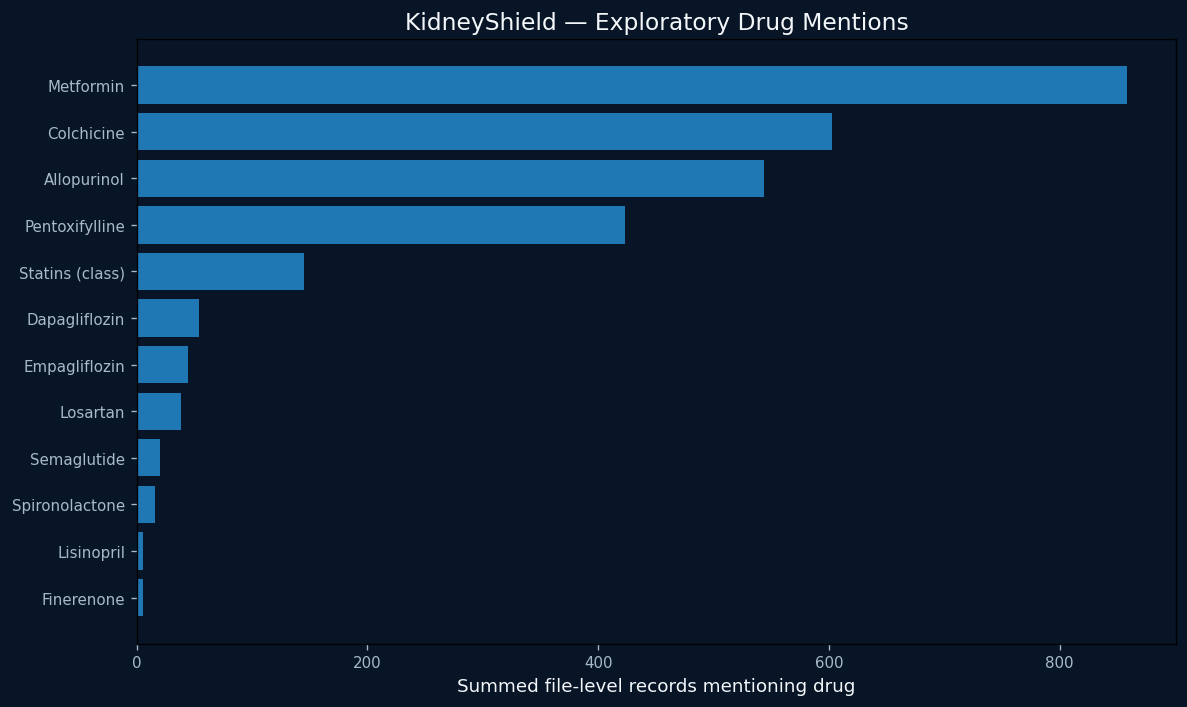

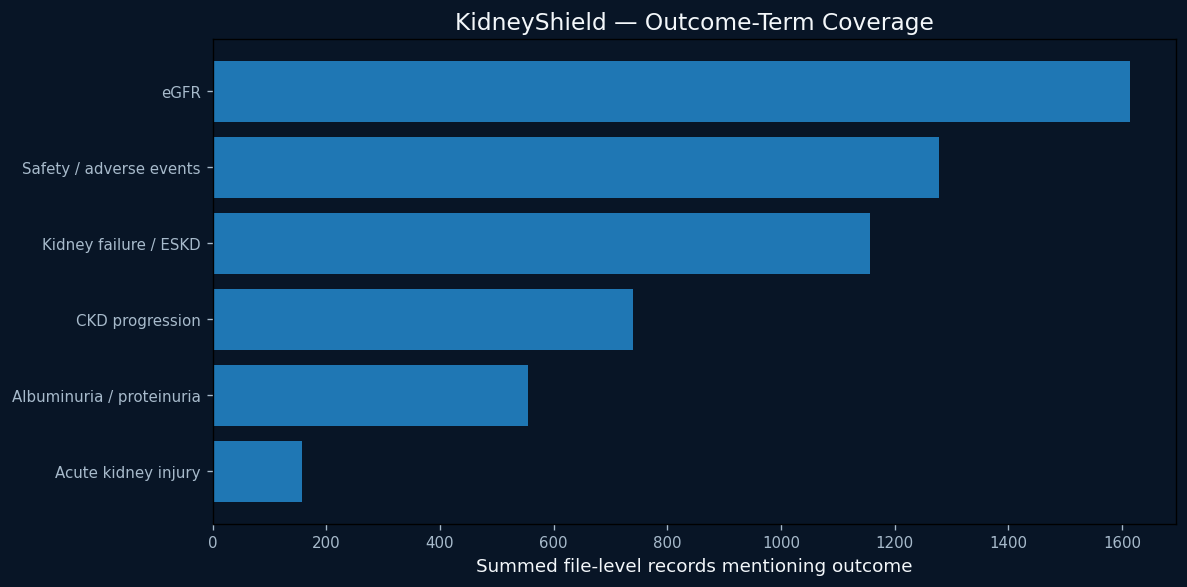


--- FINAL SUMMARY ---
Tables loaded: 44

Drug mentions:
           drug  records_mentioning_drug
      Metformin                      858
     Colchicine                      603
    Allopurinol                      544
 Pentoxifylline                      423
Statins (class)                      145
  Dapagliflozin                       54
  Empagliflozin                       44
       Losartan                       38
    Semaglutide                       20
 Spironolactone                       16
     Finerenone                        5
     Lisinopril                        5

Outcome mentions:
                  outcome  records_mentioning_outcome
                     eGFR                        1614
  Safety / adverse events                        1278
    Kidney failure / ESKD                        1156
          CKD progression                         740
Albuminuria / proteinuria                         555
      Acute kidney injury                         158

Outputs: /ka

In [34]:

# ============================================================
# KIDNEYSHIELD — CELL 15 (CORRECTED)
# Small-dataset exploratory analysis
# No network requests. No TIFF processing.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import warnings

import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

BASE = Path("/kaggle/working/kidneyshield")
RESULTS = BASE / "results"
OUT = RESULTS / "cell15_small_data_analysis"
OUT.mkdir(parents=True, exist_ok=True)

MAX_FILE_MB = 50
MAX_ROWS = 5000

print("KIDNEYSHIELD — CELL 15")
print("UTC:", datetime.now(timezone.utc).isoformat())
print("Network requests: 0")
print("TIFF processing: 0")

if not RESULTS.exists():
    raise FileNotFoundError(f"Missing results directory: {RESULTS}")

# 1. Discover manageable existing research files.
files = []
for p in RESULTS.rglob("*"):
    if not p.is_file() or OUT in p.parents:
        continue
    if p.suffix.lower() not in {".csv", ".json", ".jsonl", ".ndjson"}:
        continue
    size = p.stat().st_size
    if size <= MAX_FILE_MB * 1024 * 1024:
        files.append(p)

print("\nSmall research files found:", len(files))

inventory = []
loaded = []
load_log = []

def json_to_records(path):
    with path.open("r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return obj

    if isinstance(obj, dict):
        for key in ("records", "results", "data", "articles",
                    "studies", "trials", "items"):
            if isinstance(obj.get(key), list):
                return obj[key]
        return [obj]

    return []

for p in files:
    inventory.append({
        "file": str(p.relative_to(RESULTS)),
        "format": p.suffix.lower(),
        "size_MB": round(p.stat().st_size / (1024 ** 2), 3),
    })

    try:
        if p.suffix.lower() == ".csv":
            df = pd.read_csv(p, nrows=MAX_ROWS, low_memory=False)
        elif p.suffix.lower() in {".jsonl", ".ndjson"}:
            df = pd.read_json(p, lines=True, nrows=MAX_ROWS)
        else:
            df = pd.json_normalize(json_to_records(p), sep=".")
            df = df.head(MAX_ROWS)

        if df.empty:
            status = "EMPTY"
        else:
            loaded.append({
                "file": str(p.relative_to(RESULTS)),
                "data": df.copy(),
            })
            status = "OK"

        load_log.append({
            "file": str(p.relative_to(RESULTS)),
            "status": status,
            "rows_loaded": len(df),
            "columns": " | ".join(map(str, df.columns)),
        })

    except Exception as e:
        load_log.append({
            "file": str(p.relative_to(RESULTS)),
            "status": "ERROR: " + repr(e)[:200],
            "rows_loaded": 0,
            "columns": "",
        })

pd.DataFrame(inventory).to_csv(
    OUT / "input_file_inventory.csv", index=False
)
pd.DataFrame(load_log).to_csv(
    OUT / "load_log_and_schemas.csv", index=False
)

print("\n--- LOAD SUMMARY ---")
print(pd.DataFrame(load_log).to_string(index=False)
      if load_log else "No eligible files found.")

# 2. Classify likely sources using filenames and column names.
def source_type(filename, columns):
    text = (filename + " " + " ".join(map(str, columns))).lower()
    if any(x in text for x in ("clinicaltrials", "clinical_trials",
                                "ctg", "trial")):
        return "ClinicalTrials.gov / trial-like"
    if any(x in text for x in ("pubmed", "publication",
                                "abstract", "article", "literature")):
        return "PubMed / literature-like"
    return "Other research output"

source_rows = []
for item in loaded:
    source_rows.append({
        "file": item["file"],
        "source_class": source_type(
            item["file"], item["data"].columns
        ),
        "rows": len(item["data"]),
        "columns": len(item["data"].columns),
    })

source_df = pd.DataFrame(source_rows)
source_df.to_csv(OUT / "source_classification.csv", index=False)

print("\n--- SOURCE CLASSIFICATION ---")
print(source_df.to_string(index=False)
      if not source_df.empty else "No tables loaded.")

# 3. Search text fields for drug and outcome mentions.
# These are exploratory keyword counts, NOT efficacy estimates.
drug_patterns = {
    "Pentoxifylline": [r"\bpentoxifylline\b"],
    "Metformin": [r"\bmetformin\b"],
    "Allopurinol": [r"\ballopurinol\b"],
    "Colchicine": [r"\bcolchicine\b"],
    "Losartan": [r"\blosartan\b"],
    "Lisinopril": [r"\blisinopril\b"],
    "Spironolactone": [r"\bspironolactone\b"],
    "Finerenone": [r"\bfinerenone\b"],
    "Dapagliflozin": [r"\bdapagliflozin\b"],
    "Empagliflozin": [r"\bempagliflozin\b"],
    "Semaglutide": [r"\bsemaglutide\b"],
    "Statins (class)": [
        r"\bstatins?\b", r"\batorvastatin\b",
        r"\brosuvastatin\b", r"\bsimvastatin\b"
    ],
}

outcome_patterns = {
    "CKD progression": [
        r"\bchronic kidney disease\b", r"\bckd progression\b",
        r"\bdisease progression\b"
    ],
    "Kidney failure / ESKD": [
        r"\bkidney failure\b", r"\bend.stage kidney disease\b",
        r"\bend.stage renal disease\b", r"\beskd\b",
        r"\brenal replacement therapy\b", r"\bdialysis\b"
    ],
    "eGFR": [
        r"\begfr\b", r"\bestimated glomerular filtration\b",
        r"\bglomerular filtration rate\b"
    ],
    "Albuminuria / proteinuria": [
        r"\balbuminuria\b", r"\bproteinuria\b",
        r"\buacr\b", r"\burine albumin\b"
    ],
    "Acute kidney injury": [
        r"\bacute kidney injury\b", r"\baki\b"
    ],
    "Safety / adverse events": [
        r"\badverse events?\b", r"\bsafety\b",
        r"\bdrug interaction\b", r"\bdiscontinuation\b"
    ],
}

def make_record_text(df):
    cols = [
        c for c in df.columns
        if (df[c].dtype == "object"
            or pd.api.types.is_string_dtype(df[c]))
    ]
    if not cols:
        return pd.Series([""] * len(df), index=df.index)

    return (
        df[cols].fillna("").astype(str)
        .agg(" ".join, axis=1).str.lower()
    )

drug_rows = []
outcome_rows = []

for item in loaded:
    df = item["data"]
    texts = make_record_text(df)
    stype = source_type(item["file"], df.columns)

    for drug, patterns in drug_patterns.items():
        regex = re.compile("|".join(patterns), re.I)
        count = int(texts.map(lambda t: bool(regex.search(t))).sum())
        drug_rows.append({
            "file": item["file"],
            "source_class": stype,
            "drug": drug,
            "records_mentioning_drug": count,
            "records_analyzed": len(df),
        })

    for outcome, patterns in outcome_patterns.items():
        regex = re.compile("|".join(patterns), re.I)
        count = int(texts.map(lambda t: bool(regex.search(t))).sum())
        outcome_rows.append({
            "file": item["file"],
            "source_class": stype,
            "outcome": outcome,
            "records_mentioning_outcome": count,
            "records_analyzed": len(df),
        })

drug_df = pd.DataFrame(drug_rows)
outcome_df = pd.DataFrame(outcome_rows)

drug_df.to_csv(OUT / "drug_mentions_by_file.csv", index=False)
outcome_df.to_csv(OUT / "outcome_mentions_by_file.csv", index=False)

if not drug_df.empty:
    drug_agg = (
        drug_df.groupby("drug", as_index=False)
        ["records_mentioning_drug"].sum()
        .sort_values("records_mentioning_drug", ascending=False)
    )
else:
    drug_agg = pd.DataFrame(
        columns=["drug", "records_mentioning_drug"]
    )

if not outcome_df.empty:
    outcome_agg = (
        outcome_df.groupby("outcome", as_index=False)
        ["records_mentioning_outcome"].sum()
        .sort_values("records_mentioning_outcome", ascending=False)
    )
else:
    outcome_agg = pd.DataFrame(
        columns=["outcome", "records_mentioning_outcome"]
    )

drug_agg.to_csv(OUT / "drug_mentions_aggregate.csv", index=False)
outcome_agg.to_csv(OUT / "outcome_mentions_aggregate.csv", index=False)

# 4. Create figures only when there are records to plot.
if not drug_agg.empty:
    plot_df = drug_agg.head(12).sort_values(
        "records_mentioning_drug"
    )
    plt.figure(figsize=(10, 6))
    plt.barh(plot_df["drug"], plot_df["records_mentioning_drug"])
    plt.xlabel("Summed file-level records mentioning drug")
    plt.title("KidneyShield — Exploratory Drug Mentions")
    plt.tight_layout()
    plt.savefig(OUT / "drug_mentions.png", dpi=150)
    plt.show()
    plt.close()

if not outcome_agg.empty:
    plot_df = outcome_agg.sort_values("records_mentioning_outcome")
    plt.figure(figsize=(10, 5))
    plt.barh(plot_df["outcome"],
             plot_df["records_mentioning_outcome"])
    plt.xlabel("Summed file-level records mentioning outcome")
    plt.title("KidneyShield — Outcome-Term Coverage")
    plt.tight_layout()
    plt.savefig(OUT / "outcome_mentions.png", dpi=150)
    plt.show()
    plt.close()

# 5. Save concise report.
report = [
    "# KidneyShield Cell 15 — Small-Dataset Analysis",
    "",
    f"- UTC: {datetime.now(timezone.utc).isoformat()}",
    f"- Small data files discovered: {len(files)}",
    f"- Tables loaded: {len(loaded)}",
    "- Network requests: 0",
    "- TIFF processing: 0",
    "",
    "## Important limitations",
    "- Keyword mentions do not establish drug efficacy or safety.",
    "- A record may occur in multiple files; totals are not unique-study counts.",
    "- Outcome-term counts are not clinical event counts.",
    "- Drug ranking requires primary-study review and quantitative evidence.",
    "",
    "## Outputs",
    "- `input_file_inventory.csv`",
    "- `load_log_and_schemas.csv`",
    "- `source_classification.csv`",
    "- `drug_mentions_by_file.csv`",
    "- `outcome_mentions_by_file.csv`",
    "- `drug_mentions_aggregate.csv`",
    "- `outcome_mentions_aggregate.csv`",
    "- `drug_mentions.png` and `outcome_mentions.png` when data are available",
]
(OUT / "CELL15_REPORT.md").write_text(
    "\n".join(report), encoding="utf-8"
)

print("\n--- FINAL SUMMARY ---")
print("Tables loaded:", len(loaded))
print("\nDrug mentions:")
print(drug_agg.to_string(index=False)
      if not drug_agg.empty else "No usable records.")
print("\nOutcome mentions:")
print(outcome_agg.to_string(index=False)
      if not outcome_agg.empty else "No usable records.")
print("\nOutputs:", OUT)
print("Report:", OUT / "CELL15_REPORT.md")
print("\nCell 15 complete.")

# Cell 16 — Evidence Source Discovery and Deduplication

## Objective

Identify the actual PubMed literature and ClinicalTrials.gov records collected by KidneyShield, audit their schemas, and prepare traceable datasets for quantitative evidence analysis.

## Workflow

1. Inspect existing small CSV, JSON, and JSONL files.
2. Identify candidate literature and clinical-trial files using filenames, column names, and stable identifiers.
3. Audit available PMIDs, NCT identifiers, titles, abstracts, and other fields.
4. Deduplicate records within their source using stable identifiers, retaining source-file provenance.
5. Export source audits, candidate records, deduplicated datasets, and a Markdown report.

## Scientific safeguards

* Keyword mentions are not counts of unique studies or evidence of efficacy.
* ClinicalTrials.gov registrations are not proof of treatment benefit.
* Reviews, randomized trials, and observational studies must be distinguished before evaluating treatment effects.
* Records without reliable identifiers are retained for inspection but are not counted as uniquely identified studies.
* Source classifications are provisional and require verification.

**Success criterion:** Produce an auditable, deduplicated inventory of genuine literature or trial records, or clearly identify which source files are missing.

This cell performs local file analysis only. It does not download data, access the internet, or open large microscopy images.


In [35]:

# Cell 16 — KidneyShield evidence source discovery and deduplication
# Local-only: no downloads, no network, no microscopy image processing.

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import pandas as pd

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
OUT = RESULTS / "cell16_evidence_source_audit"
OUT.mkdir(parents=True, exist_ok=True)

MAX_FILE_MB = 30
MAX_CSV_ROWS = 200_000
SUPPORTED = {".csv", ".json", ".jsonl", ".ndjson"}

EXCLUDED_DIRS = {
    "medical_visuals",
    "hubmap",
    "cell15_small_data_analysis",
    "cell16_evidence_source_audit",
    "__pycache__",
}
EXCLUDED_TERMS = (
    "inventory", "manifest", "catalog", "readiness",
    "microscopy", "visual_atlas", "tile_catalog",
    "image_qc", "cell15", "cell14", "cell13",
    "cell12", "cell11", "checkpoint",
)
SOURCE_TERMS = (
    "pubmed", "clinicaltrials", "clinical_trials",
    "clinical-trials", "ctg", "literature",
    "trial_records", "trialrecords", "research_articles",
)

def normalize(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def excluded(path):
    if any(part.lower() in EXCLUDED_DIRS for part in path.parts):
        return True
    stem = path.stem.lower()
    return any(term in stem for term in EXCLUDED_TERMS)

def flatten_dict(obj, prefix=""):
    result = {}
    if not isinstance(obj, dict):
        return result

    for key, value in obj.items():
        key = str(key)
        full_key = f"{prefix}.{key}" if prefix else key

        if isinstance(value, dict):
            result.update(flatten_dict(value, full_key))
        elif isinstance(value, list):
            result[full_key] = json.dumps(
                value, ensure_ascii=False, default=str
            )
        else:
            result[full_key] = value

    return result

def looks_like_record(record):
    keys = [normalize(k) for k in record.keys()]

    has_id = any(
        "pmid" in key
        or "nctid" in key
        or key in {"nctnumber", "nctno", "trialid", "clinicaltrialid"}
        for key in keys
    )
    has_title = any("title" in key for key in keys)
    has_abstract = any("abstract" in key for key in keys)

    return has_id or (has_title and has_abstract)

def extract_json_records(obj):
    records = []

    if isinstance(obj, dict):
        flat = flatten_dict(obj)

        if looks_like_record(flat):
            records.append(flat)

        for value in obj.values():
            if isinstance(value, (dict, list)):
                records.extend(extract_json_records(value))

    elif isinstance(obj, list):
        for value in obj:
            if isinstance(value, (dict, list)):
                records.extend(extract_json_records(value))

    return records

def load_file(path):
    suffix = path.suffix.lower()

    if suffix == ".csv":
        return pd.read_csv(
            path,
            dtype=str,
            low_memory=False,
            nrows=MAX_CSV_ROWS,
        ).fillna("")

    if suffix in {".jsonl", ".ndjson"}:
        records = []

        with path.open("r", encoding="utf-8", errors="replace") as handle:
            for index, line in enumerate(handle):
                if index >= MAX_CSV_ROWS:
                    break

                line = line.strip()
                if not line:
                    continue

                try:
                    obj = json.loads(line)
                    if isinstance(obj, dict):
                        records.append(flatten_dict(obj))
                    elif isinstance(obj, list):
                        records.extend(extract_json_records(obj))
                except Exception:
                    continue

        return pd.DataFrame(records).fillna("")

    if suffix == ".json":
        with path.open("r", encoding="utf-8", errors="replace") as handle:
            obj = json.load(handle)

        return pd.DataFrame(extract_json_records(obj)).fillna("")

    return pd.DataFrame()

def get_stable_id(record):
    """Return a PMID or NCT ID only when an appropriate field is present."""
    pmids = []
    ncts = []

    for key, value in record.items():
        key_norm = normalize(key)
        value = str(value).strip()

        if not value or value.lower() in {"nan", "none", "null"}:
            continue

        if "pmid" in key_norm:
            match = re.fullmatch(r"\s*(\d{5,10})\s*", value)
            if match:
                pmids.append(match.group(1))

        is_nct_field = (
            "nctid" in key_norm
            or key_norm in {"nctnumber", "nctno"}
            or key_norm in {"trialid", "clinicaltrialid"}
        )

        if is_nct_field:
            match = re.search(r"\bNCT\d{8}\b", value, re.I)
            if match:
                ncts.append(match.group(0).upper())

    if pmids:
        return "PubMed", pmids[0]

    if ncts:
        return "ClinicalTrials.gov", ncts[0]

    return "", ""

def classify_source(path, columns):
    name = path.name.lower()
    keys = [normalize(c) for c in columns]

    if "pubmed" in name or any("pmid" in key for key in keys):
        return "PubMed"

    if any(term in name for term in (
        "clinicaltrials", "clinical_trials", "clinical-trials", "ctg"
    )):
        return "ClinicalTrials.gov"

    if any(
        "nctid" in key or key in {"nctnumber", "nctno"}
        for key in keys
    ):
        return "ClinicalTrials.gov"

    if any(term in name for term in ("literature", "research_articles")):
        return "Literature / uncertain source"

    return "Unclassified"

def find_columns(columns, term):
    return [str(c) for c in columns if term in normalize(c)]

if not RESULTS.exists():
    raise FileNotFoundError(
        f"KidneyShield results directory not found: {RESULTS}. "
        "Run the project setup and data-collection cells first."
    )

print("KidneyShield Cell 16")
print("Scanning small structured files under:", RESULTS)
print("No network access. No large image files opened.")
print()

# 1. Discover eligible files.
files = []

for path in RESULTS.rglob("*"):
    if not path.is_file():
        continue
    if path.suffix.lower() not in SUPPORTED:
        continue
    if excluded(path):
        continue

    try:
        size_mb = path.stat().st_size / (1024 * 1024)
    except OSError:
        continue

    if size_mb > MAX_FILE_MB:
        print(f"Skipped large file ({size_mb:.1f} MB): {path.name}")
        continue

    files.append((path, size_mb))

file_rows = []
schema_rows = []
candidate_frames = []

# 2. Load and audit each discovered file.
for path, size_mb in sorted(files, key=lambda item: str(item[0]).lower()):
    relative_path = str(path.relative_to(RESULTS))
    filename_signal = any(
        term in path.name.lower() for term in SOURCE_TERMS
    )

    try:
        df = load_file(path)
        columns = [str(column) for column in df.columns]
        source_type = classify_source(path, columns)

        id_columns = [
            column for column in columns
            if (
                "pmid" in normalize(column)
                or "nctid" in normalize(column)
                or normalize(column) in {
                    "nctnumber", "nctno", "trialid", "clinicaltrialid"
                }
            )
        ]
        title_columns = find_columns(columns, "title")
        abstract_columns = find_columns(columns, "abstract")

        id_found = any(
            bool(get_stable_id(row.to_dict())[1])
            for _, row in df.head(500).iterrows()
        )

        schema_signal = bool(
            id_columns or (title_columns and abstract_columns)
        )
        selected = filename_signal or schema_signal

        file_rows.append({
            "relative_path": relative_path,
            "size_mb": round(size_mb, 3),
            "format": path.suffix.lower(),
            "rows_loaded": len(df),
            "column_count": len(columns),
            "source_type": source_type,
            "filename_signal": filename_signal,
            "schema_signal": schema_signal,
            "identifier_columns": "; ".join(id_columns),
            "title_columns": "; ".join(title_columns),
            "abstract_columns": "; ".join(abstract_columns),
            "identifier_found_in_first_500_rows": id_found,
            "status": (
                "LOADED_CANDIDATE" if selected
                else "LOADED_NOT_STRONGLY_IDENTIFIED"
            ),
            "error": "",
        })

        schema_rows.append({
            "relative_path": relative_path,
            "source_type": source_type,
            "rows_loaded": len(df),
            "column_names": " | ".join(columns),
            "identifier_columns": " | ".join(id_columns),
            "title_columns": " | ".join(title_columns),
            "abstract_columns": " | ".join(abstract_columns),
            "selected_for_review": selected,
        })

        if selected and not df.empty:
            df = df.copy()
            df["_kidneyshield_source_file"] = relative_path
            df["_kidneyshield_source_type"] = source_type
            candidate_frames.append(df)

    except Exception as exc:
        file_rows.append({
            "relative_path": relative_path,
            "size_mb": round(size_mb, 3),
            "format": path.suffix.lower(),
            "rows_loaded": 0,
            "column_count": 0,
            "source_type": "Unclassified",
            "filename_signal": filename_signal,
            "schema_signal": False,
            "identifier_columns": "",
            "title_columns": "",
            "abstract_columns": "",
            "identifier_found_in_first_500_rows": False,
            "status": "LOAD_ERROR",
            "error": repr(exc)[:500],
        })

file_audit = pd.DataFrame(file_rows)
schema_audit = pd.DataFrame(schema_rows)

file_audit_path = OUT / "cell16_source_file_audit.csv"
schema_audit_path = OUT / "cell16_schema_audit.csv"

file_audit.to_csv(file_audit_path, index=False)
schema_audit.to_csv(schema_audit_path, index=False)

# 3. Combine candidate records and attach stable identifiers.
if candidate_frames:
    candidates = pd.concat(
        candidate_frames,
        ignore_index=True,
        sort=False,
    ).fillna("")
else:
    candidates = pd.DataFrame()

if not candidates.empty:
    stable_ids = candidates.apply(
        lambda row: get_stable_id(row.to_dict()),
        axis=1,
    )
    candidates["_kidneyshield_id_type"] = [
        item[0] for item in stable_ids
    ]
    candidates["_kidneyshield_stable_id"] = [
        item[1] for item in stable_ids
    ]

candidate_path = OUT / "cell16_candidate_records_inventory.csv"
candidates.to_csv(candidate_path, index=False)

# 4. Deduplicate independently by inferred source.
summary_rows = []
deduplicated_paths = []

if not candidates.empty:
    for source_type in sorted(
        candidates["_kidneyshield_source_type"].astype(str).unique()
    ):
        source_df = candidates[
            candidates["_kidneyshield_source_type"].astype(str) == source_type
        ].copy()

        identified = source_df[
            source_df["_kidneyshield_stable_id"].astype(str).str.len() > 0
        ].copy()

        if identified.empty:
            summary_rows.append({
                "source_type": source_type,
                "candidate_rows": len(source_df),
                "rows_with_stable_ids": 0,
                "unique_stable_ids": 0,
                "duplicate_rows_collapsed": 0,
                "rows_without_stable_ids": len(source_df),
                "output_file": "",
            })
            continue

        # Stable identifier is the deduplication key. Keep all contributing
        # source paths in a provenance column.
        clean_rows = []

        for stable_id, group in identified.groupby(
            "_kidneyshield_stable_id", sort=False
        ):
            merged = group.iloc[0].to_dict()
            merged["_kidneyshield_duplicate_rows_collapsed"] = len(group)
            merged["_kidneyshield_source_files_all"] = " ; ".join(
                sorted(set(group["_kidneyshield_source_file"].astype(str)))
            )
            clean_rows.append(merged)

        clean = pd.DataFrame(clean_rows)
        safe_source = re.sub(
            r"[^a-z0-9]+", "_", source_type.lower()
        ).strip("_")

        clean_path = OUT / f"cell16_deduplicated_{safe_source}.csv"
        clean.to_csv(clean_path, index=False)
        deduplicated_paths.append(clean_path)

        summary_rows.append({
            "source_type": source_type,
            "candidate_rows": len(source_df),
            "rows_with_stable_ids": len(identified),
            "unique_stable_ids": len(clean),
            "duplicate_rows_collapsed": len(identified) - len(clean),
            "rows_without_stable_ids": len(source_df) - len(identified),
            "output_file": str(clean_path),
        })

summary = pd.DataFrame(summary_rows)
summary_path = OUT / "cell16_deduplication_summary.csv"
summary.to_csv(summary_path, index=False)

# 5. Write a concise report.
candidate_file_count = (
    int((file_audit["status"] == "LOADED_CANDIDATE").sum())
    if not file_audit.empty else 0
)

report_lines = [
    "# KidneyShield Cell 16 — Evidence Source Audit",
    "",
    f"- Run time UTC: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')}",
    f"- Files inspected: {len(file_audit)}",
    f"- Candidate source files: {candidate_file_count}",
    f"- Candidate record rows: {len(candidates)}",
    "",
    "## Deduplication results",
    "",
]

if summary.empty:
    report_lines.extend([
        "No candidate record datasets were found.",
        "",
        "This does not mean that kidney evidence is unavailable. "
        "It means this audit did not identify candidate raw-record files "
        "in the searched results directory.",
    ])
else:
    report_lines.append(summary.to_markdown(index=False))

report_lines.extend([
    "",
    "## Interpretation safeguards",
    "",
    "- Source classification is heuristic and must be verified.",
    "- Identifiers are deduplicated within each inferred source type.",
    "- Records without reliable PMID/NCT IDs are not counted as unique studies.",
    "- Keyword counts are not treatment-effect estimates.",
    "- No efficacy ranking is produced by this cell.",
    "",
    "## Output files",
    "",
    f"- Source file audit: `{file_audit_path}`",
    f"- Schema audit: `{schema_audit_path}`",
    f"- Candidate records: `{candidate_path}`",
    f"- Deduplication summary: `{summary_path}`",
])

for path in deduplicated_paths:
    report_lines.append(f"- Deduplicated records: `{path}`")

report_path = OUT / "CELL16_REPORT.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

# 6. Print results.
print("=== FILE DISCOVERY ===")
print("Files inspected:", len(file_audit))
print("Candidate source files:", candidate_file_count)
print("Candidate record rows:", len(candidates))
print()

print("=== CANDIDATE SOURCE FILES ===")
if not file_audit.empty:
    view = file_audit[
        file_audit["status"] == "LOADED_CANDIDATE"
    ]
    display(view.head(100))
else:
    print("No supported files found.")

print()
print("=== DEDUPLICATION SUMMARY ===")
if not summary.empty:
    display(summary)
else:
    print("No candidate datasets available.")

print()
print("=== OUTPUTS ===")
for path in [
    file_audit_path,
    schema_audit_path,
    candidate_path,
    summary_path,
    report_path,
    *deduplicated_paths,
]:
    print(path)

if summary.empty or not (
    summary["unique_stable_ids"].fillna(0) > 0
).any():
    print("\nNEXT STEP:")
    print("No deduplicated dataset with reliable stable IDs was produced.")
    print("Inspect cell16_source_file_audit.csv and locate the original")
    print("PubMed and ClinicalTrials.gov raw outputs from Cell 2.")
else:
    print("\nNEXT STEP:")
    print("Verify source types, study designs, and outcome columns before")
    print("performing quantitative clinical evidence extraction.")

print("\nCell 16 complete.")

KidneyShield Cell 16
Scanning small structured files under: /kaggle/working/kidneyshield/results
No network access. No large image files opened.

=== FILE DISCOVERY ===
Files inspected: 17
Candidate source files: 3
Candidate record rows: 3851

=== CANDIDATE SOURCE FILES ===


,relative_path,size_mb,format,rows_loaded,column_count,source_type,filename_signal,schema_signal,identifier_columns,title_columns,abstract_columns,identifier_found_in_first_500_rows,status,error
3,clinical_trials_manual_review_queue.csv,8.302,.csv,1649,32,ClinicalTrials.gov,True,True,nct_id,title; official_title,,True,LOADED_CANDIDATE,
15,manual_review_queue.csv,3.372,.csv,1995,14,PubMed,False,True,pmid,title,abstract,True,LOADED_CANDIDATE,
16,pubmed_manual_review_queue.csv,0.394,.csv,207,23,PubMed,True,True,pmid,title,abstract,True,LOADED_CANDIDATE,



=== DEDUPLICATION SUMMARY ===


,source_type,candidate_rows,rows_with_stable_ids,unique_stable_ids,duplicate_rows_collapsed,rows_without_stable_ids,output_file
0,ClinicalTrials.gov,1649,1649,1649,0,0,/kaggle/working/kidneyshield/results/cell16_ev...
1,PubMed,2202,2202,2136,66,0,/kaggle/working/kidneyshield/results/cell16_ev...



=== OUTPUTS ===
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/cell16_source_file_audit.csv
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/cell16_schema_audit.csv
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/cell16_candidate_records_inventory.csv
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/cell16_deduplication_summary.csv
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/CELL16_REPORT.md
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/cell16_deduplicated_clinicaltrials_gov.csv
/kaggle/working/kidneyshield/results/cell16_evidence_source_audit/cell16_deduplicated_pubmed.csv

NEXT STEP:
Verify source types, study designs, and outcome columns before
performing quantitative clinical evidence extraction.

Cell 16 complete.


# Cell 17 — Clinical Evidence Screening and Extraction

## Objective

Screen the deduplicated PubMed and ClinicalTrials.gov records to identify candidate generic drugs, kidney outcomes, study designs, and records requiring primary-study review.

## Methods

1. Load the deduplicated PubMed and clinical-trial datasets from Cell 16.
2. Inspect the actual available fields rather than assuming a fixed schema.
3. Search titles, abstracts, intervention fields, conditions, and outcome descriptions for candidate drugs and kidney endpoints.
4. Classify records into provisional study-design categories using transparent text rules.
5. Generate separate PubMed and trial screening tables, drug–outcome evidence maps, and manual-review queues.
6. Record which signals triggered screening so that results can be reproduced and checked.

## Scientific safeguards

* Keyword screening is a retrieval method, not a systematic review or efficacy determination.
* A drug mention does not establish that the drug was tested for kidney protection.
* A kidney outcome mention does not establish that a study reported a favorable result.
* Clinical-trial registration, study completion, and published findings are separate concepts.
* Drug names and study designs require manual verification, including brand/generic equivalence and combination products.
* Effect sizes, confidence intervals, sample sizes, and follow-up durations must be extracted from source records or full-text primary studies, not inferred from keywords.

**Deliverables:** screening tables, review queues, a drug–outcome map, screening summaries, and a Markdown report for the next evidence-extraction stage.


In [36]:

# Cell 17 — KidneyShield clinical evidence screening
# Local processing only. No network calls and no microscopy image processing.
#
# IMPORTANT:
# This cell performs candidate retrieval, not efficacy assessment.
# Keyword matches must be verified against primary studies.

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import pandas as pd

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
INPUT_DIR = RESULTS / "cell16_evidence_source_audit"
OUT = RESULTS / "cell17_clinical_evidence_screening"
OUT.mkdir(parents=True, exist_ok=True)

PUBMED_FILE = INPUT_DIR / "cell16_deduplicated_pubmed.csv"
TRIALS_FILE = INPUT_DIR / "cell16_deduplicated_clinicaltrials_gov.csv"

# Candidate generic drugs. Names are retrieval terms, not recommendations.
DRUG_TERMS = {
    "SGLT2 inhibitors": [
        "dapagliflozin", "empagliflozin", "canagliflozin",
        "ertugliflozin", "sotagliflozin",
    ],
    "GLP-1 receptor agonists": [
        "semaglutide", "liraglutide", "dulaglutide",
        "exenatide", "lixisenatide", "tirzepatide",
    ],
    "ACE inhibitors": [
        "lisinopril", "enalapril", "ramipril",
        "benazepril", "captopril", "perindopril",
    ],
    "ARBs": [
        "losartan", "valsartan", "irbesartan",
        "candesartan", "telmisartan", "olmesartan",
    ],
    "Mineralocorticoid receptor antagonists": [
        "finerenone", "spironolactone", "eplerenone",
    ],
    "Metformin": ["metformin"],
    "Statins": [
        "atorvastatin", "rosuvastatin", "simvastatin",
        "pravastatin", "pitavastatin", "lovastatin",
        "fluvastatin",
    ],
    "Colchicine": ["colchicine"],
    "Allopurinol": ["allopurinol"],
    "Pentoxifylline": ["pentoxifylline"],
    "GLP-1/GIP dual agonist": ["tirzepatide"],
    "Other candidate drugs": [
        "hydroxychloroquine", "pioglitazone",
        "acetylcysteine", "N-acetylcysteine",
        "pentoxifylline", "bardoxolone",
        "roxadustat", "febuxostat",
    ],
}

# Kidney outcomes and related terms. Broad terms are intentionally flagged
# for review because their clinical meaning varies across records.
OUTCOME_TERMS = {
    "eGFR / kidney function": [
        "egfr", "estimated glomerular filtration rate",
        "glomerular filtration rate", "kidney function",
        "renal function", "creatinine clearance",
    ],
    "Albuminuria / proteinuria": [
        "albuminuria", "proteinuria", "urine albumin",
        "urinary albumin", "uacr", "acr",
        "urine protein", "protein excretion",
    ],
    "CKD progression": [
        "ckd progression", "chronic kidney disease progression",
        "disease progression", "progression of kidney disease",
        "progressive kidney disease",
    ],
    "Kidney failure / ESKD": [
        "kidney failure", "renal failure", "end stage kidney",
        "end-stage kidney", "end stage renal",
        "end-stage renal", "esrd", "eskd",
        "renal replacement therapy", "dialysis",
    ],
    "Acute kidney injury": [
        "acute kidney injury", "aki", "acute renal injury",
    ],
    "Kidney-related mortality": [
        "renal death", "kidney death", "kidney-related mortality",
        "renal mortality",
    ],
    "Kidney histology / pathology": [
        "renal biopsy", "kidney biopsy", "glomerulosclerosis",
        "interstitial fibrosis", "tubular atrophy",
        "glomerular injury", "histopathology",
    ],
    "Safety / adverse events": [
        "adverse event", "adverse events", "serious adverse",
        "safety outcome", "hyperkalemia", "hyperkalaemia",
        "acute kidney injury", "hypoglycemia", "hypoglycaemia",
    ],
}

# Broad condition signals, used for prioritization rather than eligibility.
CONDITION_TERMS = {
    "Chronic kidney disease": [
        "chronic kidney disease", "ckd",
    ],
    "Diabetic kidney disease": [
        "diabetic kidney disease", "diabetic nephropathy",
        "diabetic renal disease",
    ],
    "Glomerular disease": [
        "glomerulonephritis", "iga nephropathy",
        "membranous nephropathy", "focal segmental",
        "minimal change disease",
    ],
    "Polycystic kidney disease": [
        "polycystic kidney disease", "adpkd",
    ],
    "Transplant": [
        "kidney transplant", "renal transplant",
        "kidney transplantation",
    ],
    "Hypertension-related kidney disease": [
        "hypertensive nephropathy", "hypertensive kidney",
    ],
    "General kidney / renal": [
        "kidney disease", "renal disease", "nephropathy",
        "nephrology",
    ],
}

# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------

def normalize_key(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def safe_text(value):
    if value is None:
        return ""
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    return str(value)

def read_csv_required(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Required Cell 16 output not found: {path}\n"
            "Run Cell 16 successfully before running Cell 17."
        )
    return pd.read_csv(path, dtype=str, low_memory=False).fillna("")

def find_columns(df, terms):
    """Find columns whose normalized names contain any supplied term."""
    found = []
    for column in df.columns:
        name = normalize_key(column)
        if any(term in name for term in terms):
            found.append(column)
    return found

def choose_text_columns(df, source_type):
    """
    Select likely fields containing scientific content.
    Keep all columns as a fallback if schemas differ from expectations.
    """
    preferred_terms = [
        "title", "abstract", "summary", "description",
        "intervention", "condition", "outcome", "endpoint",
        "objective", "studytype", "design", "phase",
        "eligibility", "primarypurpose", "officialtitle",
        "briefsummary", "detaileddescription",
        "primaryoutcome", "secondaryoutcome",
    ]
    selected = find_columns(df, preferred_terms)

    # Add identifiers for traceability.
    selected += find_columns(
        df,
        ["pmid", "nctid", "nctnumber", "trialid", "doi", "url"],
    )

    # Preserve order and remove duplicates.
    selected = list(dict.fromkeys(selected))
    if not selected:
        selected = list(df.columns)

    return selected

def make_record_text(row, columns):
    return " ".join(
        safe_text(row.get(column, ""))
        for column in columns
    ).lower()

def find_term_hits(text, term_dictionary):
    hits = {}
    for label, terms in term_dictionary.items():
        matched = []
        for term in terms:
            # Word boundaries reduce accidental substring matches.
            pattern = r"(?<![a-z0-9])" + re.escape(term.lower()) + r"(?![a-z0-9])"
            if re.search(pattern, text, flags=re.I):
                matched.append(term)
        if matched:
            hits[label] = sorted(set(matched))
    return hits

def find_drug_hits(text):
    hits = {}
    for group, terms in DRUG_TERMS.items():
        matched = []
        for term in terms:
            pattern = r"(?<![a-z0-9])" + re.escape(term.lower()) + r"(?![a-z0-9])"
            if re.search(pattern, text, flags=re.I):
                matched.append(term)
        if matched:
            hits[group] = sorted(set(matched))
    return hits

def classify_design(text, source_type):
    """
    Provisional text-based design classifier.
    Does not replace verification in the Methods section.
    """
    t = text.lower()

    if source_type == "ClinicalTrials.gov":
        if any(x in t for x in [
            "randomized", "randomised", "allocation: randomized",
            "allocation: randomised",
        ]):
            return "Registered trial — randomization signal"
        if any(x in t for x in [
            "observational", "cohort", "case-control",
            "cross-sectional",
        ]):
            return "Registered study — observational signal"
        if "interventional" in t:
            return "Registered trial — interventional, design unverified"
        if "expanded access" in t:
            return "Expanded access"
        return "Registered study — design unclear"

    if any(x in t for x in [
        "systematic review", "meta-analysis", "meta analysis",
        "network meta-analysis", "network meta analysis",
    ]):
        return "Review / meta-analysis signal"

    if any(x in t for x in [
        "randomized controlled trial", "randomised controlled trial",
        "randomized clinical trial", "randomised clinical trial",
        "placebo-controlled trial", "double-blind randomized",
        "double blind randomized", "random allocation",
    ]):
        return "Randomized trial signal"

    if any(x in t for x in [
        "retrospective cohort", "prospective cohort",
        "population-based cohort", "matched cohort",
        "case-control study", "cross-sectional study",
        "observational study",
    ]):
        return "Observational study signal"

    if any(x in t for x in [
        "case report", "case series",
    ]):
        return "Case report / series signal"

    if any(x in t for x in [
        "animal model", "mouse model", "mice were",
        "rat model", "murine", "in vitro",
    ]):
        return "Preclinical / laboratory signal"

    if any(x in t for x in [
        "protocol", "study protocol", "trial protocol",
    ]):
        return "Protocol signal"

    return "Design unclear — manual review"

def classify_trial_status(row, columns):
    """
    Read status-like fields where available.
    This is a record-status label, not evidence of benefit.
    """
    values = []
    for col in columns:
        if any(term in normalize_key(col) for term in [
            "overallstatus", "recruitmentstatus", "study_status",
            "trialstatus", "status",
        ]):
            value = safe_text(row.get(col, "")).strip()
            if value:
                values.append(value)

    if not values:
        return "Status unavailable"

    return " | ".join(sorted(set(values)))

def extract_identifier(row, source_type):
    if source_type == "PubMed":
        terms = ["pmid"]
        pattern = r"\b\d{5,10}\b"
    else:
        terms = ["nctid", "nctnumber", "nctno", "trialid", "clinicaltrialid"]
        pattern = r"\bNCT\d{8}\b"

    for column, value in row.items():
        key = normalize_key(column)
        if not any(term in key for term in terms):
            continue

        match = re.search(pattern, safe_text(value), flags=re.I)
        if match:
            return match.group(0).upper() if pattern.startswith(r"\bNCT") else match.group(0)

    # Fall back to Cell 16 identifiers if present.
    value = safe_text(row.get("_kidneyshield_stable_id", "")).strip()
    if value:
        return value

    return ""

def extract_title(row):
    preferred = [
        "title", "official_title", "officialtitle",
        "article_title", "study_title", "brief_title",
        "brieftitle",
    ]

    normalized_to_original = {
        normalize_key(column): column for column in row.index
    }

    for name in preferred:
        if name in normalized_to_original:
            value = safe_text(row[normalized_to_original[name]]).strip()
            if value:
                return value[:1500]

    for column in row.index:
        if "title" in normalize_key(column):
            value = safe_text(row[column]).strip()
            if value:
                return value[:1500]

    return ""

def extract_field_value(row, terms):
    for column in row.index:
        name = normalize_key(column)
        if any(term in name for term in terms):
            value = safe_text(row[column]).strip()
            if value:
                return value[:2000]
    return ""

# ---------------------------------------------------------------------
# Load Cell 16 outputs and inspect actual schemas.
# ---------------------------------------------------------------------

pubmed = read_csv_required(PUBMED_FILE)
trials = read_csv_required(TRIALS_FILE)

print("KidneyShield Cell 17 — Clinical evidence screening")
print("PubMed rows loaded:", len(pubmed))
print("ClinicalTrials.gov rows loaded:", len(trials))
print()

print("=== PUBMED COLUMNS ===")
for column in pubmed.columns:
    print(" -", column)

print()
print("=== CLINICALTRIALS.GOV COLUMNS ===")
for column in trials.columns:
    print(" -", column)

# ---------------------------------------------------------------------
# Screen each source.
# ---------------------------------------------------------------------

screened_frames = []
source_schema_rows = []

for source_type, df in [
    ("PubMed", pubmed),
    ("ClinicalTrials.gov", trials),
]:
    text_columns = choose_text_columns(df, source_type)

    source_schema_rows.append({
        "source_type": source_type,
        "rows_loaded": len(df),
        "column_count": len(df.columns),
        "selected_text_columns": " | ".join(text_columns),
        "identifier_columns": " | ".join(
            find_columns(
                df,
                ["pmid", "nctid", "nctnumber", "trialid", "doi"],
            )
        ),
        "title_columns": " | ".join(find_columns(df, ["title"])),
        "abstract_columns": " | ".join(find_columns(df, ["abstract"])),
        "outcome_columns": " | ".join(
            find_columns(df, ["outcome", "endpoint", "result"])
        ),
    })

    results = []

    for _, row in df.iterrows():
        text = make_record_text(row, text_columns)

        # Search for drug and outcome terms independently.
        drug_hits = find_drug_hits(text)
        outcome_hits = find_term_hits(text, OUTCOME_TERMS)
        condition_hits = find_term_hits(text, CONDITION_TERMS)

        # Skip records with no drug signal and no kidney outcome/condition signal.
        # Preserve records that mention a candidate drug, even if kidney relevance
        # is uncertain, so they can be manually checked.
        if not drug_hits and not outcome_hits and not condition_hits:
            continue

        design = classify_design(text, source_type)
        identifier = extract_identifier(row, source_type)
        title = extract_title(row)

        trial_status = (
            classify_trial_status(row, df.columns)
            if source_type == "ClinicalTrials.gov"
            else ""
        )

        drug_names = sorted({
            drug
            for matches in drug_hits.values()
            for drug in matches
        })
        outcome_names = sorted(outcome_hits.keys())
        condition_names = sorted(condition_hits.keys())

        if drug_hits and outcome_hits:
            screening_priority = "High — candidate drug and kidney outcome terms"
        elif drug_hits and condition_hits:
            screening_priority = "Medium — candidate drug and kidney condition"
        elif drug_hits:
            screening_priority = "Medium — candidate drug; kidney endpoint unclear"
        elif outcome_hits and condition_hits:
            screening_priority = "Medium — kidney condition and outcome; drug unclear"
        else:
            screening_priority = "Low — broad keyword signal"

        record = {
            "source_type": source_type,
            "record_id": identifier,
            "title": title,
            "provisional_study_design": design,
            "trial_status_if_available": trial_status,
            "candidate_drugs": "; ".join(drug_names),
            "drug_groups": "; ".join(sorted(drug_hits.keys())),
            "kidney_outcomes": "; ".join(outcome_names),
            "kidney_conditions": "; ".join(condition_names),
            "drug_term_evidence": json.dumps(drug_hits, ensure_ascii=False),
            "outcome_term_evidence": json.dumps(outcome_hits, ensure_ascii=False),
            "condition_term_evidence": json.dumps(condition_hits, ensure_ascii=False),
            "screening_priority": screening_priority,
            "effect_size_extracted": False,
            "efficacy_conclusion": "Not assessed",
            "manual_verification_required": True,
        }

        # Retain source provenance and original fields for review.
        for key in [
            "_kidneyshield_source_file",
            "_kidneyshield_source_files_all",
            "_kidneyshield_duplicate_rows_collapsed",
        ]:
            if key in row.index:
                record[key] = safe_text(row.get(key, ""))

        results.append(record)

    screened = pd.DataFrame(results)
    screened_frames.append(screened)

    print()
    print(f"{source_type}: {len(screened)} records passed keyword screening")

if screened_frames:
    screened_all = pd.concat(
        screened_frames, ignore_index=True, sort=False
    ).fillna("")
else:
    screened_all = pd.DataFrame()

# ---------------------------------------------------------------------
# Export source-level screening queues.
# ---------------------------------------------------------------------

pubmed_screen = screened_all[
    screened_all["source_type"] == "PubMed"
].copy() if not screened_all.empty else pd.DataFrame()

trials_screen = screened_all[
    screened_all["source_type"] == "ClinicalTrials.gov"
].copy() if not screened_all.empty else pd.DataFrame()

all_screen_path = OUT / "cell17_all_screened_records.csv"
pubmed_screen_path = OUT / "cell17_pubmed_screening_queue.csv"
trials_screen_path = OUT / "cell17_clinical_trials_screening_queue.csv"
schema_path = OUT / "cell17_source_schema_audit.csv"

screened_all.to_csv(all_screen_path, index=False)
pubmed_screen.to_csv(pubmed_screen_path, index=False)
trials_screen.to_csv(trials_screen_path, index=False)
pd.DataFrame(source_schema_rows).to_csv(schema_path, index=False)

# ---------------------------------------------------------------------
# Create drug/outcome map.
# These are co-mentions in a record, not evidence of a beneficial effect.
# ---------------------------------------------------------------------

drug_outcome_rows = []

if not screened_all.empty:
    for _, record in screened_all.iterrows():
        drug_text = safe_text(record.get("candidate_drugs", ""))
        outcome_text = safe_text(record.get("kidney_outcomes", ""))
        drugs = [x.strip() for x in drug_text.split(";") if x.strip()]
        outcomes = [x.strip() for x in outcome_text.split(";") if x.strip()]

        if not drugs or not outcomes:
            continue

        for drug in drugs:
            for outcome in outcomes:
                drug_outcome_rows.append({
                    "source_type": record["source_type"],
                    "record_id": record["record_id"],
                    "title": record["title"],
                    "drug": drug,
                    "kidney_outcome": outcome,
                    "provisional_study_design": record["provisional_study_design"],
                    "trial_status_if_available": record["trial_status_if_available"],
                    "screening_priority": record["screening_priority"],
                    "interpretation": "Co-mention only; effect not assessed",
                    "manual_verification_required": True,
                })

drug_outcome_map = pd.DataFrame(drug_outcome_rows)
map_path = OUT / "cell17_drug_outcome_co_mentions.csv"
drug_outcome_map.to_csv(map_path, index=False)

# ---------------------------------------------------------------------
# Generate transparent summaries.
# ---------------------------------------------------------------------

if not screened_all.empty:
    priority_summary = (
        screened_all.groupby(["source_type", "screening_priority"])
        .size()
        .reset_index(name="record_count")
        .sort_values(["source_type", "record_count"], ascending=[True, False])
    )

    design_summary = (
        screened_all.groupby(["source_type", "provisional_study_design"])
        .size()
        .reset_index(name="record_count")
        .sort_values(["source_type", "record_count"], ascending=[True, False])
    )

    outcome_counts = []
    for source_type in ["PubMed", "ClinicalTrials.gov"]:
        subset = screened_all[screened_all["source_type"] == source_type]
        for outcome in OUTCOME_TERMS:
            count = subset["kidney_outcomes"].apply(
                lambda x: outcome in [
                    item.strip() for item in safe_text(x).split(";")
                ]
            ).sum()

            outcome_counts.append({
                "source_type": source_type,
                "kidney_outcome_category": outcome,
                "records_with_keyword_signal": int(count),
            })

    outcome_summary = pd.DataFrame(outcome_counts)

    priority_path = OUT / "cell17_screening_priority_summary.csv"
    design_path = OUT / "cell17_study_design_summary.csv"
    outcome_summary_path = OUT / "cell17_outcome_signal_summary.csv"

    priority_summary.to_csv(priority_path, index=False)
    design_summary.to_csv(design_path, index=False)
    outcome_summary.to_csv(outcome_summary_path, index=False)
else:
    priority_summary = pd.DataFrame()
    design_summary = pd.DataFrame()
    outcome_summary = pd.DataFrame()

    priority_path = OUT / "cell17_screening_priority_summary.csv"
    design_path = OUT / "cell17_study_design_summary.csv"
    outcome_summary_path = OUT / "cell17_outcome_signal_summary.csv"

    priority_summary.to_csv(priority_path, index=False)
    design_summary.to_csv(design_path, index=False)
    outcome_summary.to_csv(outcome_summary_path, index=False)

# ---------------------------------------------------------------------
# Write a report with clear limitations.
# ---------------------------------------------------------------------

report = [
    "# KidneyShield Cell 17 — Clinical Evidence Screening",
    "",
    f"- Run time UTC: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')}",
    f"- Input PubMed records: {len(pubmed)}",
    f"- Input ClinicalTrials.gov records: {len(trials)}",
    f"- PubMed records passing keyword screening: {len(pubmed_screen)}",
    f"- Trial records passing keyword screening: {len(trials_screen)}",
    f"- Total screened records: {len(screened_all)}",
    f"- Drug–outcome co-mention rows: {len(drug_outcome_map)}",
    "",
    "## Interpretation",
    "",
    "These counts describe records retrieved by text rules, not eligible studies, "
    "independent clinical trials, or demonstrated treatment benefits.",
    "",
    "Drug–outcome pairs indicate only that the drug and outcome terms occurred "
    "in the same record. They do not establish that the drug was administered "
    "to study that outcome, nor do they indicate the direction or magnitude of effect.",
    "",
    "Study-design labels are provisional. Verify design, population, intervention, "
    "comparator, prespecified endpoint, numerical results, follow-up, and risk of bias.",
    "",
    "No effect sizes or efficacy conclusions were inferred in this cell.",
    "",
    "## Output files",
    "",
    f"- All screened records: `{all_screen_path}`",
    f"- PubMed review queue: `{pubmed_screen_path}`",
    f"- Clinical-trial review queue: `{trials_screen_path}`",
    f"- Source schema audit: `{schema_path}`",
    f"- Drug–outcome co-mentions: `{map_path}`",
    f"- Screening priority summary: `{priority_path}`",
    f"- Provisional design summary: `{design_path}`",
    f"- Outcome signal summary: `{outcome_summary_path}`",
]

report_path = OUT / "CELL17_REPORT.md"
report_path.write_text("\n".join(report), encoding="utf-8")

# ---------------------------------------------------------------------
# Display results.
# ---------------------------------------------------------------------

print("\n=== CELL 17 SCREENING SUMMARY ===")
print("PubMed input rows:", len(pubmed))
print("ClinicalTrials.gov input rows:", len(trials))
print("PubMed screened:", len(pubmed_screen))
print("ClinicalTrials.gov screened:", len(trials_screen))
print("Total screened:", len(screened_all))
print("Drug/outcome co-mentions:", len(drug_outcome_map))

print("\n=== PRIORITY SUMMARY ===")
if not priority_summary.empty:
    display(priority_summary)

print("\n=== PROVISIONAL STUDY-DESIGN SUMMARY ===")
if not design_summary.empty:
    display(design_summary)

print("\n=== KIDNEY OUTCOME SIGNAL SUMMARY ===")
if not outcome_summary.empty:
    display(outcome_summary)

print("\n=== EXAMPLE PUBMED RECORDS FOR MANUAL REVIEW ===")
if not pubmed_screen.empty:
    display(
        pubmed_screen[
            [
                "record_id",
                "title",
                "candidate_drugs",
                "kidney_outcomes",
                "provisional_study_design",
                "screening_priority",
            ]
        ].head(20)
    )
else:
    print("No PubMed records matched the configured screening terms.")

print("\n=== OUTPUT FILES ===")
for path in [
    all_screen_path,
    pubmed_screen_path,
    trials_screen_path,
    schema_path,
    map_path,
    priority_path,
    design_path,
    outcome_summary_path,
    report_path,
]:
    print(path)

print("\nCell 17 complete.")
print("Next: validate the strongest primary-study records and extract quantitative results.")

KidneyShield Cell 17 — Clinical evidence screening
PubMed rows loaded: 2136
ClinicalTrials.gov rows loaded: 1649

=== PUBMED COLUMNS ===
 - nct_id
 - title
 - official_title
 - overall_status
 - study_type
 - phases
 - enrollment
 - conditions
 - interventions_json
 - primary_outcomes
 - secondary_outcomes
 - eligibility_criteria
 - sex
 - minimum_age
 - maximum_age
 - start_date
 - completion_date
 - results_available
 - study_url
 - candidate_matches
 - retrieved_utc
 - kidney_relevance_flag
 - kidney_term_match_count
 - hard_outcome_mention_flag
 - sustained_decline_mention_flag
 - egfr_creatinine_mention_flag
 - albuminuria_proteinuria_mention_flag
 - safety_mention_flag
 - study_type_signal
 - screening_status
 - manual_review_priority
 - manual_review_reason
 - _kidneyshield_source_file
 - _kidneyshield_source_type
 - drug
 - drug_assignment_method
 - pmid
 - abstract
 - journal
 - year
 - publication_types
 - kidney_relevant_text_screen
 - endpoint_categories
 - study_design_sig

,source_type,screening_priority,record_count
0,ClinicalTrials.gov,High — candidate drug and kidney outcome terms,1266
3,ClinicalTrials.gov,Medium — candidate drug; kidney endpoint unclear,147
1,ClinicalTrials.gov,Low — broad keyword signal,118
2,ClinicalTrials.gov,Medium — candidate drug and kidney condition,56
4,ClinicalTrials.gov,Medium — kidney condition and outcome; drug un...,34
5,PubMed,High — candidate drug and kidney outcome terms,1374
8,PubMed,Medium — candidate drug; kidney endpoint unclear,340
7,PubMed,Medium — candidate drug and kidney condition,153
6,PubMed,Low — broad keyword signal,128
9,PubMed,Medium — kidney condition and outcome; drug un...,43



=== PROVISIONAL STUDY-DESIGN SUMMARY ===


,source_type,provisional_study_design,record_count
2,ClinicalTrials.gov,"Registered trial — interventional, design unve...",883
3,ClinicalTrials.gov,Registered trial — randomization signal,634
1,ClinicalTrials.gov,Registered study — observational signal,103
0,ClinicalTrials.gov,Registered study — design unclear,1
5,PubMed,Design unclear — manual review,1404
7,PubMed,Preclinical / laboratory signal,173
4,PubMed,Case report / series signal,128
6,PubMed,Observational study signal,127
9,PubMed,Randomized trial signal,89
10,PubMed,Review / meta-analysis signal,76



=== KIDNEY OUTCOME SIGNAL SUMMARY ===


,source_type,kidney_outcome_category,records_with_keyword_signal
0,PubMed,eGFR / kidney function,625
1,PubMed,Albuminuria / proteinuria,417
2,PubMed,CKD progression,68
3,PubMed,Kidney failure / ESKD,851
4,PubMed,Acute kidney injury,102
5,PubMed,Kidney-related mortality,2
6,PubMed,Kidney histology / pathology,103
7,PubMed,Safety / adverse events,244
8,ClinicalTrials.gov,eGFR / kidney function,1009
9,ClinicalTrials.gov,Albuminuria / proteinuria,205



=== EXAMPLE PUBMED RECORDS FOR MANUAL REVIEW ===


,record_id,title,candidate_drugs,kidney_outcomes,provisional_study_design,screening_priority
0,26995301,Effect of pentoxifylline on renal outcomes in ...,pentoxifylline,Albuminuria / proteinuria; CKD progression; Ki...,Review / meta-analysis signal,High — candidate drug and kidney outcome terms
1,24042021,Effects of uric acid-lowering therapy on renal...,allopurinol,Albuminuria / proteinuria; Kidney failure / ES...,Review / meta-analysis signal,High — candidate drug and kidney outcome terms
2,34400461,Pentoxifylline in diabetic kidney disease (VA ...,pentoxifylline,Albuminuria / proteinuria; Kidney failure / ES...,Randomized trial signal,High — candidate drug and kidney outcome terms
3,30949987,"Pentoxifylline, progression of chronic kidney ...",pentoxifylline,Albuminuria / proteinuria; CKD progression; Ki...,Randomized trial signal,High — candidate drug and kidney outcome terms
4,28794291,Allopurinol Against Progression of Chronic Kid...,allopurinol,CKD progression; Kidney failure / ESKD; eGFR /...,Design unclear — manual review,High — candidate drug and kidney outcome terms
5,22336824,Pentoxifylline for diabetic kidney disease.,captopril; pentoxifylline,Albuminuria / proteinuria; Kidney failure / ES...,Review / meta-analysis signal,High — candidate drug and kidney outcome terms
6,21443811,Acute kidney injury.,N-acetylcysteine; acetylcysteine,Acute kidney injury; Kidney failure / ESKD; Sa...,Review / meta-analysis signal,High — candidate drug and kidney outcome terms
7,19445797,Acute renal failure.,N-acetylcysteine; acetylcysteine,Acute kidney injury; Kidney failure / ESKD; Sa...,Review / meta-analysis signal,High — candidate drug and kidney outcome terms
8,19455178,Emerging therapies for chronic kidney disease:...,pentoxifylline,Albuminuria / proteinuria; Kidney failure / ESKD,Preclinical / laboratory signal,High — candidate drug and kidney outcome terms
9,19101287,N-acetylcysteine in cardiovascular-surgery-ass...,N-acetylcysteine; acetylcysteine,Kidney failure / ESKD; eGFR / kidney function,Review / meta-analysis signal,High — candidate drug and kidney outcome terms



=== OUTPUT FILES ===
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_all_screened_records.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_pubmed_screening_queue.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_clinical_trials_screening_queue.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_source_schema_audit.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_drug_outcome_co_mentions.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_screening_priority_summary.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_study_design_summary.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/cell17_outcome_signal_summary.csv
/kaggle/working/kidneyshield/results/cell17_clinical_evidence_screening/CELL17_REPORT.md

Cell 17 complete.
Next: validate

# Cell 18 — Primary-Study Triage and Quantitative Evidence Extraction

## Objective

Create a smaller, traceable review queue of potentially relevant primary studies and extract numerical evidence candidates from the locally available PubMed records.

## Workflow

1. Link screening results back to the deduplicated PubMed records.
2. Prioritize records with candidate drugs and kidney outcomes.
3. Distinguish likely primary research from reviews, protocols, preclinical studies, and records of uncertain design using conservative title and abstract rules.
4. Extract candidate numerical results, including effect estimates, confidence intervals, p-values, sample sizes, and eGFR-related values where recognizable.
5. Link relevant trial registrations when a matching NCT identifier is present in the available records.
6. Generate a focused manual-review queue and a machine-readable extraction table.

## Important limitations

This cell does not retrieve full text or independently verify publications. Numerical patterns may refer to baseline characteristics, unrelated outcomes, or subgroup analyses; every extracted value requires checking against the paper. Missing numerical results must remain missing rather than being imputed. No treatment effect or drug ranking will be inferred automatically.

**Success criterion:** Produce a manageable, evidence-traceable queue for manual review, with candidate numerical results and explicit uncertainty labels.


In [37]:

# Cell 18 — KidneyShield primary-study triage and numerical evidence candidates
# Local-only. No web requests, downloads, or image processing.
#
# This cell identifies records for review. It does NOT establish efficacy.
# All automatically extracted numerical values require source-paper verification.

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import pandas as pd

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
CELL16 = RESULTS / "cell16_evidence_source_audit"
CELL17 = RESULTS / "cell17_clinical_evidence_screening"
OUT = RESULTS / "cell18_primary_study_triage"
OUT.mkdir(parents=True, exist_ok=True)

PUBMED_FILE = CELL16 / "cell16_deduplicated_pubmed.csv"
TRIALS_FILE = CELL16 / "cell16_deduplicated_clinicaltrials_gov.csv"
SCREEN_FILE = CELL17 / "cell17_pubmed_screening_queue.csv"

def norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def txt(value):
    if value is None:
        return ""
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    return str(value).strip()

def read_required(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required file: {path}\n"
            "Run Cells 16 and 17 first."
        )
    return pd.read_csv(path, dtype=str, low_memory=False).fillna("")

def find_column(df, names, contains=False):
    normalized = {norm(c): c for c in df.columns}

    for name in names:
        if norm(name) in normalized:
            return normalized[norm(name)]

    if contains:
        for column in df.columns:
            key = norm(column)
            if any(norm(name) in key for name in names):
                return column

    return None

def get_id(row, source="PubMed"):
    candidates = (
        ["record_id", "_kidneyshield_stable_id", "pmid"]
        if source == "PubMed"
        else [
            "record_id", "_kidneyshield_stable_id",
            "nct_id", "nctid", "NCTId",
        ]
    )

    keys = {norm(c): c for c in row.index}

    for candidate in candidates:
        col = keys.get(norm(candidate))
        if col:
            value = txt(row[col])
            if source == "PubMed":
                m = re.fullmatch(r"\d{5,10}", value)
                if m:
                    return m.group(0)
            else:
                m = re.search(r"\bNCT\d{8}\b", value, re.I)
                if m:
                    return m.group(0).upper()

    # Search other ID-shaped columns.
    for col in row.index:
        key = norm(col)
        value = txt(row[col])

        if source == "PubMed" and "pmid" in key:
            m = re.search(r"\b\d{5,10}\b", value)
            if m:
                return m.group(0)

        if source != "PubMed" and ("nct" in key or "trialid" in key):
            m = re.search(r"\bNCT\d{8}\b", value, re.I)
            if m:
                return m.group(0).upper()

    return ""

def first_value(row, exact_names=(), contains_names=()):
    keys = {norm(c): c for c in row.index}

    for name in exact_names:
        col = keys.get(norm(name))
        if col:
            value = txt(row[col])
            if value:
                return value

    for col in row.index:
        key = norm(col)
        if any(norm(term) in key for term in contains_names):
            value = txt(row[col])
            if value:
                return value

    return ""

def title_abstract(row):
    title = first_value(
        row,
        exact_names=("title", "official_title", "article_title"),
        contains_names=("title",),
    )
    abstract = first_value(
        row,
        exact_names=("abstract", "abstract_text"),
        contains_names=("abstract",),
    )
    return title, abstract

def conservative_design(title, abstract):
    """
    Conservative triage using explicit signals.
    The output remains provisional; inspect the article Methods section.
    """
    t = (title or "").lower()
    a = (abstract or "").lower()
    combined = f"{t} {a}"

    # Title-level labels take precedence when explicit.
    if re.search(r"\b(systematic review|meta-analysis|meta analysis)\b", t):
        return "Likely review/meta-analysis", "High title-level signal"

    if re.search(r"\b(protocol|study protocol|trial protocol)\b", t):
        return "Likely protocol", "High title-level signal"

    if re.search(r"\b(case report|case series)\b", t):
        return "Likely case report/series", "High title-level signal"

    if re.search(r"\b(review|overview|state-of-the-art)\b", t):
        return "Likely review", "Moderate title-level signal"

    if re.search(
        r"\b(randomi[sz]ed|randomi[sz]ation|placebo-controlled)\b", t
    ):
        return "Possible randomized trial", "Title-level trial signal"

    if re.search(
        r"\b(cohort|case-control|cross-sectional|population-based)\b", t
    ):
        return "Possible observational study", "Title-level design signal"

    # Do not call a study randomized merely because it cites a randomized trial.
    # Require a direct design phrase in the abstract.
    randomized_phrases = [
        "we randomly assigned",
        "participants were randomly assigned",
        "patients were randomly assigned",
        "randomly allocated",
        "randomly assigned to receive",
        "randomised controlled trial",
        "randomized controlled trial",
        "randomized clinical trial",
        "randomised clinical trial",
    ]
    if any(phrase in a for phrase in randomized_phrases):
        return "Possible randomized trial", "Abstract design phrase"

    if re.search(
        r"\b(retrospective cohort|prospective cohort|case-control study|"
        r"cross-sectional study|observational cohort)\b",
        a,
    ):
        return "Possible observational study", "Abstract design phrase"

    if re.search(
        r"\b(mice|mouse model|murine|rat model|animal model|in vitro)\b",
        combined,
    ):
        return "Possible preclinical/laboratory study", "Preclinical phrase"

    return "Uncertain — inspect full text", "No sufficiently specific design signal"

def extract_numeric_candidates(text):
    """
    Extract literal number-containing snippets with context.
    These are candidates only, not structured effect estimates.
    """
    if not text:
        return []

    patterns = [
        # Confidence intervals such as 0.72 (95% CI 0.61-0.85)
        r".{0,100}\b(?:95\s*%?\s*CI|confidence interval)\b.{0,100}",
        # Hazard ratios, risk ratios, odds ratios, relative risks
        r".{0,100}\b(?:HR|hazard ratio|RR|risk ratio|OR|odds ratio)\b.{0,100}",
        # Mean difference and related measures
        r".{0,100}\b(?:mean difference|standardized mean difference|"
        r"relative risk reduction|absolute risk reduction)\b.{0,100}",
        # p values
        r".{0,70}\bp\s*[=<]\s*0?\.\d+\b.{0,70}",
        # eGFR slope / change
        r".{0,100}\b(?:eGFR|estimated glomerular filtration rate|"
        r"glomerular filtration rate)\b.{0,100}",
        # Sample size
        r".{0,80}\b(?:n\s*=\s*\d+|sample size of \d+|"
        r"\d+\s+participants|\d+\s+patients)\b.{0,80}",
    ]

    snippets = []
    for pattern in patterns:
        for match in re.finditer(pattern, text, flags=re.I | re.S):
            snippet = re.sub(r"\s+", " ", match.group(0)).strip()
            if snippet and snippet not in snippets:
                snippets.append(snippet[:300])

    return snippets[:30]

def extract_nct_ids(text):
    if not text:
        return []
    return sorted(set(
        match.upper()
        for match in re.findall(r"\bNCT\d{8}\b", text, flags=re.I)
    ))

# 1. Load source datasets.
pubmed = read_required(PUBMED_FILE)
trials = read_required(TRIALS_FILE)
screened = read_required(SCREEN_FILE)

print("Cell 18 — Primary-study triage")
print("PubMed source rows:", len(pubmed))
print("Trial registration rows:", len(trials))
print("Cell 17 PubMed screening rows:", len(screened))
print()

# 2. Locate important fields in the actual schema.
pubmed_id_col = find_column(
    pubmed,
    ["pmid", "_kidneyshield_stable_id"],
    contains=True,
)
pubmed_title_col = find_column(
    pubmed, ["title", "article_title"], contains=True
)
pubmed_abstract_col = find_column(
    pubmed, ["abstract"], contains=True
)

print("Detected PubMed ID column:", pubmed_id_col)
print("Detected PubMed title column:", pubmed_title_col)
print("Detected PubMed abstract column:", pubmed_abstract_col)

# Create lookup from original PubMed records.
pubmed_lookup = {}

for _, row in pubmed.iterrows():
    rid = get_id(row, "PubMed")
    if rid and rid not in pubmed_lookup:
        title, abstract = title_abstract(row)
        pubmed_lookup[rid] = {
            "title": title,
            "abstract": abstract,
            "source_file": first_value(
                row, exact_names=("_kidneyshield_source_file",)
            ),
            "raw_row": row.to_dict(),
        }

# Create NCT lookup for linking registrations mentioned in publications.
trial_lookup = {}

for _, row in trials.iterrows():
    nct = get_id(row, "ClinicalTrials.gov")
    if not nct:
        continue

    trial_title = first_value(
        row,
        exact_names=("official_title", "title", "brief_title"),
        contains_names=("title",),
    )
    trial_status = first_value(
        row,
        exact_names=("overall_status", "status"),
        contains_names=("overallstatus", "recruitmentstatus"),
    )

    trial_lookup[nct] = {
        "title": trial_title,
        "status": trial_status,
        "source_file": first_value(
            row, exact_names=("_kidneyshield_source_file",)
        ),
    }

# 3. Join screened records to their source abstracts and classify conservatively.
review_rows = []

for _, row in screened.iterrows():
    pmid = get_id(row, "PubMed")
    source = pubmed_lookup.get(pmid, {})

    title = txt(row.get("title", "")) or source.get("title", "")
    abstract = source.get("abstract", "")

    # Keep original screened tags, but do not use them as verified conclusions.
    candidate_drugs = txt(row.get("candidate_drugs", ""))
    kidney_outcomes = txt(row.get("kidney_outcomes", ""))
    kidney_conditions = txt(row.get("kidney_conditions", ""))

    if not pmid:
        continue

    design, design_reason = conservative_design(title, abstract)
    text_for_numbers = f"{title}. {abstract}"
    numeric_candidates = extract_numeric_candidates(text_for_numbers)
    linked_ncts = extract_nct_ids(text_for_numbers)

    linked_trial_records = [
        {
            "nct_id": nct,
            "title": trial_lookup.get(nct, {}).get("title", ""),
            "status": trial_lookup.get(nct, {}).get("status", ""),
            "match_type": "NCT identifier explicitly present in title/abstract",
        }
        for nct in linked_ncts
        if nct in trial_lookup
    ]

    # A practical review score for sorting, not a clinical evidence grade.
    score = 0
    score += 3 if candidate_drugs else 0
    score += 3 if kidney_outcomes else 0
    score += 1 if kidney_conditions else 0
    score += 2 if design == "Possible randomized trial" else 0
    score += 1 if design == "Possible observational study" else 0
    score += 1 if numeric_candidates else 0
    score += 1 if linked_trial_records else 0

    if design in {
        "Likely review/meta-analysis",
        "Likely review",
        "Likely protocol",
        "Possible preclinical/laboratory study",
    }:
        primary_study_priority = "Secondary / protocol / preclinical — separate review"
    elif score >= 8:
        primary_study_priority = "Priority A — inspect primary report"
    elif score >= 5:
        primary_study_priority = "Priority B — inspect record"
    else:
        primary_study_priority = "Priority C — lower initial priority"

    review_rows.append({
        "pmid": pmid,
        "title": title,
        "abstract_available": bool(abstract.strip()),
        "abstract_character_count": len(abstract),
        "candidate_drugs_from_cell17": candidate_drugs,
        "kidney_outcomes_from_cell17": kidney_outcomes,
        "kidney_conditions_from_cell17": kidney_conditions,
        "conservative_design_triage": design,
        "design_signal_reason": design_reason,
        "numerical_candidate_count": len(numeric_candidates),
        "numerical_candidate_snippets": json.dumps(
            numeric_candidates, ensure_ascii=False
        ),
        "nct_ids_in_title_abstract": "; ".join(linked_ncts),
        "matched_registered_trials": json.dumps(
            linked_trial_records, ensure_ascii=False
        ),
        "review_triage_score_not_evidence_grade": score,
        "primary_study_review_priority": primary_study_priority,
        "source_file": source.get("source_file", ""),
        "efficacy_assessed": False,
        "manual_full_text_verification_required": True,
    })

review = pd.DataFrame(review_rows)

if not review.empty:
    review = review.sort_values(
        [
            "review_triage_score_not_evidence_grade",
            "numerical_candidate_count",
        ],
        ascending=[False, False],
    )

# 4. Export focused review queues.
review_path = OUT / "cell18_primary_study_review_queue.csv"
review.to_csv(review_path, index=False)

priority_a_path = OUT / "cell18_priority_A_records.csv"
review[
    review["primary_study_review_priority"] == "Priority A — inspect primary report"
].to_csv(priority_a_path, index=False)

numeric_path = OUT / "cell18_numerical_candidate_extraction.csv"
if not review.empty:
    review[
        review["numerical_candidate_count"] > 0
    ][[
        "pmid", "title", "candidate_drugs_from_cell17",
        "kidney_outcomes_from_cell17",
        "conservative_design_triage",
        "numerical_candidate_count",
        "numerical_candidate_snippets",
        "nct_ids_in_title_abstract",
        "primary_study_review_priority",
    ]].to_csv(numeric_path, index=False)
else:
    pd.DataFrame().to_csv(numeric_path, index=False)

# 5. Produce a design triage summary.
if not review.empty:
    design_summary = (
        review.groupby(
            ["conservative_design_triage", "design_signal_reason"]
        )
        .size()
        .reset_index(name="record_count")
        .sort_values("record_count", ascending=False)
    )

    priority_summary = (
        review.groupby("primary_study_review_priority")
        .size()
        .reset_index(name="record_count")
        .sort_values("record_count", ascending=False)
    )

    design_summary.to_csv(
        OUT / "cell18_conservative_design_summary.csv", index=False
    )
    priority_summary.to_csv(
        OUT / "cell18_review_priority_summary.csv", index=False
    )
else:
    design_summary = pd.DataFrame()
    priority_summary = pd.DataFrame()

# 6. Write report with interpretation limitations.
report_lines = [
    "# KidneyShield Cell 18 — Primary-Study Triage",
    "",
    f"- Run time UTC: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')}",
    f"- Cell 17 PubMed records examined: {len(screened)}",
    f"- Records joined to source records by PMID: "
    f"{sum(1 for _, r in screened.iterrows() if get_id(r, 'PubMed') in pubmed_lookup)}",
    f"- Records in review queue: {len(review)}",
    f"- Records with numerical candidate snippets: "
    f"{int((review['numerical_candidate_count'] > 0).sum()) if not review.empty else 0}",
    f"- Records with explicit NCT ID in title/abstract: "
    f"{int(review['nct_ids_in_title_abstract'].astype(str).str.len().gt(0).sum()) if not review.empty else 0}",
    "",
    "## Method",
    "",
    "Design triage uses conservative title/abstract phrases. It does not replace "
    "review of the Methods section or full-text paper.",
    "",
    "Numerical snippets are literal text fragments that may represent baseline "
    "values, unrelated endpoints, subgroup findings, or cited literature.",
    "",
    "An NCT identifier is linked only when it appears explicitly in the title "
    "or abstract and is found in the local trial-registration dataset.",
    "",
    "## Scientific limitations",
    "",
    "- No full-text retrieval or external validation was performed.",
    "- No effect sizes were standardized or pooled.",
    "- No efficacy direction or drug ranking was inferred.",
    "- Review priority scores are workflow aids, not evidence grades.",
    "- Check the primary paper for study design, population, comparator, "
    "outcome definition, effect estimate, confidence interval, follow-up, "
    "and adverse events.",
    "",
    "## Outputs",
    "",
    f"- Primary-study review queue: `{review_path}`",
    f"- Priority A records: `{priority_a_path}`",
    f"- Numerical candidates: `{numeric_path}`",
    f"- Conservative design summary: "
    f"`{OUT / 'cell18_conservative_design_summary.csv'}`",
    f"- Review priority summary: "
    f"`{OUT / 'cell18_review_priority_summary.csv'}`",
]

report_path = OUT / "CELL18_REPORT.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

# 7. Display concise results.
print("\n=== CELL 18 SUMMARY ===")
print("Records in review queue:", len(review))

if not review.empty:
    print(
        "With numerical candidates:",
        int((review["numerical_candidate_count"] > 0).sum()),
    )
    print(
        "With explicit NCT links:",
        int(review["nct_ids_in_title_abstract"].astype(str).str.len().gt(0).sum()),
    )

print("\n=== CONSERVATIVE DESIGN TRIAGE ===")
if not design_summary.empty:
    display(design_summary)

print("\n=== REVIEW PRIORITY ===")
if not priority_summary.empty:
    display(priority_summary)

print("\n=== TOP RECORDS FOR MANUAL VERIFICATION ===")
if not review.empty:
    display(review[[
        "pmid",
        "title",
        "candidate_drugs_from_cell17",
        "kidney_outcomes_from_cell17",
        "conservative_design_triage",
        "numerical_candidate_count",
        "primary_study_review_priority",
    ]].head(25))

print("\n=== OUTPUT FILES ===")
for path in [
    review_path,
    priority_a_path,
    numeric_path,
    OUT / "cell18_conservative_design_summary.csv",
    OUT / "cell18_review_priority_summary.csv",
    report_path,
]:
    print(path)

print("\nCell 18 complete.")
print("Next: manually verify the highest-priority primary papers and extract")
print("study-level effect estimates before comparing candidate drugs.")

Cell 18 — Primary-study triage
PubMed source rows: 2136
Trial registration rows: 1649
Cell 17 PubMed screening rows: 2038

Detected PubMed ID column: pmid
Detected PubMed title column: title
Detected PubMed abstract column: abstract

=== CELL 18 SUMMARY ===
Records in review queue: 2038
With numerical candidates: 1397
With explicit NCT links: 31

=== CONSERVATIVE DESIGN TRIAGE ===


,conservative_design_triage,design_signal_reason,record_count
9,Uncertain — inspect full text,No sufficiently specific design signal,1433
6,Possible preclinical/laboratory study,Preclinical phrase,187
0,Likely case report/series,High title-level signal,77
2,Likely review,Moderate title-level signal,74
8,Possible randomized trial,Title-level trial signal,61
7,Possible randomized trial,Abstract design phrase,61
3,Likely review/meta-analysis,High title-level signal,48
4,Possible observational study,Abstract design phrase,45
5,Possible observational study,Title-level design signal,42
1,Likely protocol,High title-level signal,10



=== REVIEW PRIORITY ===


,primary_study_review_priority,record_count
1,Priority B — inspect record,781
0,Priority A — inspect primary report,490
2,Priority C — lower initial priority,448
3,Secondary / protocol / preclinical — separate ...,319



=== TOP RECORDS FOR MANUAL VERIFICATION ===


,pmid,title,candidate_drugs_from_cell17,kidney_outcomes_from_cell17,conservative_design_triage,numerical_candidate_count,primary_study_review_priority
39,41373013,Efficacy and safety of metformin versus empagl...,empagliflozin; metformin,Albuminuria / proteinuria; CKD progression; eG...,Possible randomized trial,12,Priority A — inspect primary report
227,38564654,Combination Treatment with Verinurad and Allop...,allopurinol,Albuminuria / proteinuria; Safety / adverse ev...,Possible randomized trial,10,Priority A — inspect primary report
23,30922594,Effects of Hydroxychloroquine on Proteinuria i...,hydroxychloroquine,Albuminuria / proteinuria; Kidney failure / ES...,Possible randomized trial,8,Priority A — inspect primary report
407,32964203,Uric Acid Lowering and Biomarkers of Kidney Da...,allopurinol,Albuminuria / proteinuria; eGFR / kidney function,Possible randomized trial,8,Priority A — inspect primary report
246,32579810,Serum Urate Lowering with Allopurinol and Kidn...,allopurinol,Albuminuria / proteinuria; Safety / adverse ev...,Possible randomized trial,6,Priority A — inspect primary report
1927,26300986,Effects of pentoxifylline on proteinuria and g...,pentoxifylline,Albuminuria / proteinuria; eGFR / kidney function,Possible randomized trial,6,Priority A — inspect primary report
876,40826392,The potential adding therapeutic effect of pen...,pentoxifylline,eGFR / kidney function,Possible randomized trial,4,Priority A — inspect primary report
1929,29753374,Beneficial Effects of Pentoxifylline Plus Losa...,losartan; pentoxifylline,Albuminuria / proteinuria,Possible randomized trial,4,Priority A — inspect primary report
49,25595565,Allopurinol and progression of CKD and cardiov...,allopurinol,CKD progression; Kidney failure / ESKD; eGFR /...,Possible randomized trial,20,Priority A — inspect primary report
44,32579811,Effects of Allopurinol on the Progression of C...,allopurinol,Albuminuria / proteinuria; Safety / adverse ev...,Possible randomized trial,17,Priority A — inspect primary report



=== OUTPUT FILES ===
/kaggle/working/kidneyshield/results/cell18_primary_study_triage/cell18_primary_study_review_queue.csv
/kaggle/working/kidneyshield/results/cell18_primary_study_triage/cell18_priority_A_records.csv
/kaggle/working/kidneyshield/results/cell18_primary_study_triage/cell18_numerical_candidate_extraction.csv
/kaggle/working/kidneyshield/results/cell18_primary_study_triage/cell18_conservative_design_summary.csv
/kaggle/working/kidneyshield/results/cell18_primary_study_triage/cell18_review_priority_summary.csv
/kaggle/working/kidneyshield/results/cell18_primary_study_triage/CELL18_REPORT.md

Cell 18 complete.
Next: manually verify the highest-priority primary papers and extract
study-level effect estimates before comparing candidate drugs.


In [41]:

# ============================================================
# CELL 20 — KIDNEYSHIELD FINAL PACKAGE + ZIP
# ============================================================
# Main ZIP:
#   /kaggle/working/KidneyShield.zip
#
# Package folder:
#   /kaggle/working/KS_Package/
#
# Requires Cell 19:
#   results/cell19_final_evidence_matrix/
#       cell19_full_evidence_matrix_unverified.csv
#
# Includes figures, tables, reports, data, audits, metadata,
# and available upstream outputs from earlier cells.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import os
import sys
import json
import shutil
import hashlib
import zipfile
import platform
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path("/kaggle/working/kidneyshield")
RESULTS = ROOT / "results"
MATRIX = RESULTS / "cell19_final_evidence_matrix" / \
         "cell19_full_evidence_matrix_unverified.csv"

OUT = Path("/kaggle/working/KS_Package")
ZIP_PATH = Path("/kaggle/working/KidneyShield.zip")
REPORT_NAME = "Final_Report.md"

if not MATRIX.exists():
    raise FileNotFoundError(
        f"Cell 19 matrix not found:\n{MATRIX}\n\n"
        "Run Cell 19 successfully, then rerun Cell 20."
    )

# Rebuild the package cleanly on each run.
if OUT.exists():
    shutil.rmtree(OUT)

for folder in [
    "figures", "tables", "reports", "data",
    "audit", "metadata", "upstream", "project"
]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

df = pd.read_csv(MATRIX, low_memory=False)
df.columns = [str(c).strip() for c in df.columns]
df = df.replace({np.nan: ""})

print("=" * 65)
print("CELL 20 — KIDNEYSHIELD FINAL PACKAGE")
print("=" * 65)
print("Evidence matrix rows:", f"{len(df):,}")
print("Evidence matrix columns:", f"{len(df.columns):,}")

# ------------------------------------------------------------
# 2. HELPERS
# ------------------------------------------------------------

def find_col(frame, names):
    cols = list(frame.columns)
    norm = {c: c.lower().replace(" ", "_") for c in cols}

    for name in names:
        target = name.lower().replace(" ", "_")
        for c in cols:
            if norm[c] == target:
                return c

    for name in names:
        target = name.lower().replace(" ", "_")
        for c in cols:
            if target in norm[c]:
                return c

    return None

def count_nonempty(series):
    return int(series.astype(str).str.strip().ne("").sum())

def save_placeholder(path, title, message):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axis("off")
    ax.set_title(title)
    ax.text(
        0.5, 0.5, message,
        ha="center", va="center", wrap=True,
        transform=ax.transAxes
    )
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def categorize(path):
    name = path.name.lower()
    suffix = path.suffix.lower()
    full = str(path).lower()

    if suffix in {".png", ".jpg", ".jpeg", ".svg"}:
        return "figures"
    if suffix in {".csv", ".tsv", ".xlsx", ".xls"}:
        return "tables"
    if any(x in name or x in full for x in [
        "audit", "deduplicat", "provenance", "crosswalk"
    ]):
        return "audit"
    if suffix in {".md", ".txt", ".rst"}:
        return "reports"
    if suffix in {".json", ".yaml", ".yml", ".toml"}:
        return "metadata"
    if suffix in {".parquet", ".feather", ".pkl", ".pickle",
                  ".npy", ".npz"}:
        return "data"
    return "upstream"

# ------------------------------------------------------------
# 3. COLUMN DETECTION
# ------------------------------------------------------------

title_col = find_col(df, ["title", "article_title", "study_title"])
abstract_col = find_col(df, ["abstract", "article_abstract"])
pmid_col = find_col(df, ["pmid", "pubmed_id"])
doi_col = find_col(df, ["doi"])
nct_col = find_col(df, ["nct_id", "nct", "clinicaltrials_id"])
year_col = find_col(df, ["publication_year", "pub_year", "year"])
drug_col = find_col(df, [
    "candidate_drug", "drug", "drug_candidate", "intervention"
])
priority_col = find_col(df, ["review_priority", "priority"])
design_col = find_col(df, ["design", "study_design", "design_signal"])

# ------------------------------------------------------------
# 4. CORE TABLES
# ------------------------------------------------------------

df.to_csv(OUT / "tables" / "Evidence_Matrix.csv", index=False)

# Editable manual-verification template.
verify = df.copy()
manual_columns = {
    "full_text_checked": "",
    "verified_design": "",
    "verified_population": "",
    "verified_sample_size": "",
    "verified_intervention_comparator": "",
    "verified_kidney_endpoint": "",
    "verified_followup": "",
    "verified_effect_estimate": "",
    "verified_confidence_interval": "",
    "verified_p_value": "",
    "verified_safety": "",
    "risk_of_bias": "",
    "reviewer_notes": "",
    "verification_status": "NOT VERIFIED",
}
for col, default in manual_columns.items():
    if col not in verify.columns:
        verify[col] = default

verify.to_csv(
    OUT / "tables" / "Verify_Studies.csv", index=False
)

if drug_col:
    drugs = (
        df[drug_col].astype(str).str.strip()
        .replace("", np.nan).dropna()
        .value_counts().rename_axis("candidate")
        .reset_index(name="records")
    )
    drugs.to_csv(OUT / "tables" / "Drug_Counts.csv", index=False)
else:
    drugs = pd.DataFrame(columns=["candidate", "records"])

if priority_col:
    priorities = (
        df[priority_col].astype(str).replace("", "Unspecified")
        .value_counts().rename_axis("priority")
        .reset_index(name="records")
    )
else:
    priorities = pd.DataFrame(
        [{"priority": "Not available", "records": len(df)}]
    )

priorities.to_csv(OUT / "tables" / "Priority_Counts.csv", index=False)

if design_col:
    designs = (
        df[design_col].astype(str).str.strip()
        .replace("", np.nan).dropna()
        .value_counts().rename_axis("design_signal")
        .reset_index(name="records")
    )
    designs.to_csv(OUT / "tables" / "Design_Counts.csv", index=False)

trace_cols = [
    c for c in [
        pmid_col, doi_col, nct_col, title_col, year_col, drug_col,
        priority_col
    ] if c and c in df.columns
]
if trace_cols:
    df[trace_cols].to_csv(
        OUT / "tables" / "Source_Index.csv", index=False
    )

# ------------------------------------------------------------
# 5. FIGURES
# ------------------------------------------------------------

# Figure 1: candidate literature landscape.
if not drugs.empty:
    plot_df = drugs.head(15).sort_values("records")
    fig, ax = plt.subplots(figsize=(10, max(5, len(plot_df) * 0.38)))
    ax.barh(plot_df["candidate"].astype(str), plot_df["records"])
    ax.set_title("Candidate Literature Landscape")
    ax.set_xlabel("Records mentioning candidate")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        OUT / "figures" / "Drug_Landscape.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close(fig)
else:
    save_placeholder(
        OUT / "figures" / "Drug_Landscape.png",
        "Candidate Literature Landscape",
        "Candidate-drug column was not identified."
    )

# Figure 2: review priority.
if priority_col:
    counts = (
        df[priority_col].astype(str).replace("", "Unspecified")
        .value_counts().sort_values()
    )
    fig, ax = plt.subplots(figsize=(8, max(4, len(counts) * 0.55)))
    ax.barh(counts.index.astype(str), counts.values)
    ax.set_title("Automated Review Priority")
    ax.set_xlabel("Records")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        OUT / "figures" / "Priorities.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close(fig)
else:
    save_placeholder(
        OUT / "figures" / "Priorities.png",
        "Automated Review Priority",
        "Review-priority column was not identified."
    )

# Figure 3: design signals.
if design_col:
    counts = (
        df[design_col].astype(str).replace("", "Unspecified")
        .value_counts().head(15).sort_values()
    )
    fig, ax = plt.subplots(figsize=(10, max(4, len(counts) * 0.4)))
    ax.barh(counts.index.astype(str), counts.values)
    ax.set_title("Automated Study-Design Signals")
    ax.set_xlabel("Records")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        OUT / "figures" / "Design_Signals.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close(fig)
else:
    save_placeholder(
        OUT / "figures" / "Design_Signals.png",
        "Study-Design Signals",
        "Study-design column was not identified."
    )

# Figure 4: record completeness.
labels = ["Matrix rows", "Titles", "Abstracts", "PMIDs", "NCT IDs"]
values = [
    len(df),
    count_nonempty(df[title_col]) if title_col else 0,
    count_nonempty(df[abstract_col]) if abstract_col else 0,
    count_nonempty(df[pmid_col]) if pmid_col else 0,
    count_nonempty(df[nct_col]) if nct_col else 0,
]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels[::-1], values[::-1])
ax.set_title("Evidence Matrix Completeness")
ax.set_xlabel("Records")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(
    OUT / "figures" / "Completeness.png",
    dpi=160, bbox_inches="tight"
)
plt.close(fig)

# Figure 5: publication years.
year_path = OUT / "figures" / "Publication_Years.png"
if year_col:
    years = pd.to_numeric(df[year_col], errors="coerce").dropna()
    years = years[(years >= 1900) & (years <= datetime.now().year + 1)]
    if len(years):
        counts = years.astype(int).value_counts().sort_index()
        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.plot(counts.index, counts.values, marker="o")
        ax.set_title("Publication-Year Distribution")
        ax.set_xlabel("Year")
        ax.set_ylabel("Records")
        ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(year_path, dpi=160, bbox_inches="tight")
        plt.close(fig)
    else:
        save_placeholder(
            year_path, "Publication Years",
            "No usable publication-year values were found."
        )
else:
    save_placeholder(
        year_path, "Publication Years",
        "Publication-year column was not identified."
    )

# ------------------------------------------------------------
# 6. FINAL REPORT
# ------------------------------------------------------------

now = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

report = f"""# KidneyShield — Final Research Report

Generated: {now}

## Project purpose

KidneyShield organizes research evidence on generic drugs and other
interventions that may prevent kidney failure or slow chronic kidney disease
(CKD) progression.

## Evidence-matrix snapshot

- Records in the Cell 19 matrix: **{len(df):,}**
- Matrix columns: **{len(df.columns):,}**
- Records with titles: **{count_nonempty(df[title_col]) if title_col else 0:,}**
- Records with abstracts: **{count_nonempty(df[abstract_col]) if abstract_col else 0:,}**
- Records with PubMed identifiers: **{count_nonempty(df[pmid_col]) if pmid_col else 0:,}**
- Records with trial identifiers: **{count_nonempty(df[nct_col]) if nct_col else 0:,}**

These are matrix counts, not counts of unique completed trials or proven
effective treatments.

## Critical interpretation

Automated priorities, drug/outcome keyword matches, inferred design labels,
and trial registrations are screening signals. They are not proof of efficacy.

Do not claim a drug prevents kidney failure or slows CKD progression until
relevant primary studies have been checked and the outcome data verified.

## Required clinical verification

For each candidate, confirm:

1. Exact intervention, dose, comparator, and treatment duration.
2. Study design, population, baseline kidney function, and sample size.
3. Kidney outcome definition and follow-up duration.
4. Effect estimate, confidence interval, p-value, and adverse events.
5. Risk of bias, applicability, and whether reports duplicate the same trial.

Distinguish eGFR slope, sustained eGFR decline, kidney failure, albuminuria,
acute kidney injury, and composite outcomes.

## Package contents

- `figures/` — generated visual summaries.
- `tables/` — evidence matrix, verification template, and summaries.
- `reports/` — this report and available upstream reports.
- `data/` — available structured data.
- `audit/` — audit and deduplication files.
- `metadata/` — manifest, checksums, and run details.
- `upstream/` — preserved files from earlier results folders.
- `project/` — relevant project-level documentation and notebooks.

## Limitations

Records may include duplicates, incomplete abstracts, secondary reports,
ambiguous drug mentions, protocols, or inferred design classifications.
Clinical verification and critical appraisal remain necessary.

This package is a research aid, not medical advice or a treatment recommendation.
"""

(OUT / "reports" / REPORT_NAME).write_text(report, encoding="utf-8")
shutil.copy2(OUT / "reports" / REPORT_NAME, OUT / REPORT_NAME)

# ------------------------------------------------------------
# 7. PRESERVE UPSTREAM RESULTS
# ------------------------------------------------------------

copied = 0

if RESULTS.exists():
    for src in sorted(RESULTS.rglob("*")):
        if not src.is_file():
            continue

        # Avoid copying the Cell 20 output into its own upstream folder.
        try:
            src.relative_to(OUT)
            continue
        except ValueError:
            pass

        try:
            rel = src.relative_to(RESULTS)
            dest = OUT / "upstream" / rel
            dest.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dest)
            copied += 1

            category = categorize(src)
            if category != "upstream":
                cat_dest = OUT / category / rel
                cat_dest.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(src, cat_dest)
        except Exception as e:
            print(f"WARNING: Could not copy {src}: {e}")

# Include project-root docs and notebooks if present.
for src in ROOT.iterdir():
    if src.is_file() and src.suffix.lower() in {
        ".md", ".txt", ".py", ".ipynb", ".json", ".yaml", ".yml"
    }:
        try:
            shutil.copy2(src, OUT / "project" / src.name)
        except Exception as e:
            print(f"WARNING: Could not copy project file {src}: {e}")

# ------------------------------------------------------------
# 8. README + METADATA
# ------------------------------------------------------------

readme = """# KidneyShield

## Folder guide

- figures: visual summaries
- tables: evidence matrix and review templates
- reports: research report
- data: supporting structured data
- audit: deduplication and provenance artifacts
- metadata: file inventory and checksums
- upstream: files preserved from earlier cells
- project: relevant notebooks and documentation

## Important

Automated screening does not establish clinical efficacy. Verify primary
studies before making treatment claims. This package is a research aid and
not medical advice.
"""
(OUT / "README.md").write_text(readme, encoding="utf-8")

env = {
    "generated_utc": now,
    "python": sys.version,
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "source_matrix": str(MATRIX),
    "matrix_rows": int(len(df)),
    "matrix_columns": int(len(df.columns)),
    "upstream_files_copied": copied,
    "warning": "Screening signals are not proof of efficacy."
}
(OUT / "metadata" / "Run_Info.json").write_text(
    json.dumps(env, indent=2), encoding="utf-8"
)

# Create manifest before ZIP. Exclude manifest and checksum file themselves
# from the checksum list to avoid a self-referential checksum.
all_files = sorted(p for p in OUT.rglob("*") if p.is_file()
                   and p.name not in {"Manifest.csv", "SHA256SUMS.txt"})

manifest_rows = []
for p in all_files:
    manifest_rows.append({
        "path": p.relative_to(OUT).as_posix(),
        "bytes": p.stat().st_size,
        "sha256": sha256(p),
    })

pd.DataFrame(manifest_rows).to_csv(
    OUT / "metadata" / "Manifest.csv", index=False
)
(OUT / "metadata" / "SHA256SUMS.txt").write_text(
    "\n".join(f"{r['sha256']}  {r['path']}" for r in manifest_rows) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 9. BUILD SHORT-NAMED ZIP
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6
) as zf:
    for p in sorted(OUT.rglob("*")):
        if p.is_file():
            zf.write(
                p,
                arcname=(Path("KS") / p.relative_to(OUT)).as_posix()
            )

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad = zf.testzip()
    zip_names = zf.namelist()

if bad is not None:
    raise RuntimeError(f"ZIP integrity test failed: {bad}")

# Save the exact archive listing outside the ZIP.
pd.DataFrame({"zip_path": zip_names}).to_csv(
    Path("/kaggle/working/KS_Zip_Contents.csv"), index=False
)

# ------------------------------------------------------------
# 10. PRINT ALL ZIP CONTENTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ZIP CONTENTS — KidneyShield.zip")
print("=" * 65)

for name in zip_names:
    print(name)

print("\n" + "=" * 65)
print("CELL 20 COMPLETE")
print("=" * 65)
print("ZIP:          ", ZIP_PATH)
print("ZIP size:     ", f"{ZIP_PATH.stat().st_size:,} bytes")
print("Files in ZIP: ", f"{len(zip_names):,}")
print("Integrity:     PASS")
print("Report:       ", OUT / "reports" / REPORT_NAME)
print("Manifest:     ", OUT / "metadata" / "Manifest.csv")
print("ZIP listing:  ", "/kaggle/working/KS_Zip_Contents.csv")
print("\nDownload KidneyShield.zip from the Kaggle /kaggle/working output.")
print("Clinical reminder: automated screening is not proof of efficacy.")

CELL 20 — KIDNEYSHIELD FINAL PACKAGE
Evidence matrix rows: 2,038
Evidence matrix columns: 33

ZIP CONTENTS — KidneyShield.zip
KS/Final_Report.md
KS/README.md
KS/audit/HUBMAP_CELL13_SAFE_METADATA_AUDIT.md
KS/audit/KIDNEYSHIELD_CELL15_AUDIT.md
KS/audit/cell16_evidence_source_audit/CELL16_REPORT.md
KS/audit/cell20_final_research_package/KidneyShield_Research_Package/reports/HUBMAP_CELL13_SAFE_METADATA_AUDIT.md
KS/audit/cell20_final_research_package/KidneyShield_Research_Package/reports/KIDNEYSHIELD_CELL15_AUDIT.md
KS/audit/cell20_final_research_package/KidneyShield_Research_Package/reports/cell16_evidence_source_audit/CELL16_REPORT.md
KS/audit/cell20_final_research_package/KidneyShield_Research_Package/upstream/HUBMAP_CELL13_SAFE_METADATA_AUDIT.md
KS/audit/cell20_final_research_package/KidneyShield_Research_Package/upstream/KIDNEYSHIELD_CELL15_AUDIT.md
KS/audit/cell20_final_research_package/KidneyShield_Research_Package/upstream/cell16_evidence_source_audit/CELL16_REPORT.md
KS/figures/Com

In [42]:

# ============================================================
# CELL 20A — SPLIT KIDNEYSHIELD INTO TWO SMALLER ZIP FILES
# ============================================================
# ZIP 1: /kaggle/working/KS_Data.zip
#        Figures, evidence data, supporting datasets, audits
#
# ZIP 2: /kaggle/working/KS_Drugs_Report.zip
#        Final report + only relevant drug-evidence tables
#
# Uses existing Cell 19 and Cell 20 files.
# Does NOT rerun Cells 2–19.
# Prints the contents of both ZIP files and verifies integrity.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import zipfile
import shutil
import hashlib
import json
import pandas as pd

WORK = Path("/kaggle/working")
ROOT = WORK / "kidneyshield"
RESULTS = ROOT / "results"
PKG = WORK / "KS_Package"

ZIP_DATA = WORK / "KS_Data.zip"
ZIP_REPORT = WORK / "KS_Drugs_Report.zip"

# ------------------------------------------------------------
# 1. FIND EXISTING INPUT FILES
# ------------------------------------------------------------

def find_first(paths):
    for p in paths:
        if p.exists() and p.is_file():
            return p
    return None

matrix = find_first([
    PKG / "tables" / "Evidence_Matrix.csv",
    PKG / "tables" / "cell19_full_evidence_matrix_unverified.csv",
    RESULTS / "cell19_final_evidence_matrix" /
        "cell19_full_evidence_matrix_unverified.csv",
])

report = find_first([
    PKG / "reports" / "Final_Report.md",
    PKG / "Final_Report.md",
    PKG / "reports" / "KIDNEYSHIELD_FINAL_REPORT.md",
    RESULTS / "cell20_final_research_package" /
        "KIDNEYSHIELD_FINAL_REPORT.md",
])

if matrix is None:
    raise FileNotFoundError(
        "Could not find the Cell 19 evidence matrix. "
        "Run Cell 19 successfully first."
    )

print("Evidence matrix:", matrix)
print("Final report:", report if report else "Not found; a report will be created.")

# ------------------------------------------------------------
# 2. CREATE TEMPORARY STAGING FOLDERS
# ------------------------------------------------------------

STAGE_DATA = WORK / "_KS_Data_Stage"
STAGE_REPORT = WORK / "_KS_Report_Stage"

for folder in [STAGE_DATA, STAGE_REPORT]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)

for sub in ["figures", "data", "audit", "metadata"]:
    (STAGE_DATA / sub).mkdir(parents=True, exist_ok=True)

for sub in ["reports", "drug_tables", "metadata"]:
    (STAGE_REPORT / sub).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def copy_file(src, dst, copied_set=None):
    if not src or not src.exists() or not src.is_file():
        return False

    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

    if copied_set is not None:
        copied_set.add(str(src.resolve()))

    return True

def add_files_by_suffix(source_dir, target_dir, suffixes, copied_set):
    if not source_dir.exists():
        return 0

    n = 0
    for src in sorted(source_dir.rglob("*")):
        if not src.is_file() or src.suffix.lower() not in suffixes:
            continue

        # Avoid copying the ZIPs or staging folders into the archives.
        if src.name.endswith(".zip"):
            continue

        try:
            rel = src.relative_to(source_dir)
        except ValueError:
            rel = Path(src.name)

        if copy_file(src, target_dir / rel, copied_set):
            n += 1
    return n

copied_data_sources = set()
copied_report_sources = set()

# ------------------------------------------------------------
# 4. ZIP 1 — FIGURES + DATA + AUDIT FILES
# ------------------------------------------------------------

# Copy figures generated by Cell 20, if available.
for fig_dir in [
    PKG / "figures",
    RESULTS / "cell20_final_research_package" / "figures",
]:
    if fig_dir.exists():
        add_files_by_suffix(
            fig_dir,
            STAGE_DATA / "figures",
            {".png", ".jpg", ".jpeg", ".svg", ".pdf"},
            copied_data_sources
        )

# Ensure there is a figures directory even if no figures were found.
# Copy the main evidence matrix.
copy_file(
    matrix,
    STAGE_DATA / "data" / "Evidence_Matrix.csv",
    copied_data_sources
)

# Copy other structured datasets/tables from Cells 16–19.
# These support research analysis and auditability.
for cell_folder in [
    RESULTS / "cell16_evidence_source_audit",
    RESULTS / "cell17_clinical_evidence_screening",
    RESULTS / "cell18_primary_study_triage",
    RESULTS / "cell19_final_evidence_matrix",
]:
    if cell_folder.exists():
        for src in sorted(cell_folder.rglob("*")):
            if not src.is_file() or src.suffix.lower() not in {
                ".csv", ".tsv", ".json", ".parquet"
            }:
                continue

            # Keep data files separate from narrative audit reports.
            if any(word in src.name.lower() for word in [
                "audit", "deduplicat", "crosswalk", "provenance"
            ]):
                dst = STAGE_DATA / "audit" / cell_folder.name / src.name
            else:
                dst = STAGE_DATA / "data" / cell_folder.name / src.name

            copy_file(src, dst, copied_data_sources)

# Copy figure/data outputs from the existing package if available.
for folder_name in ["data", "audit", "metadata"]:
    src_dir = PKG / folder_name
    if src_dir.exists():
        add_files_by_suffix(
            src_dir,
            STAGE_DATA / folder_name,
            {
                ".csv", ".tsv", ".json", ".jsonl", ".parquet",
                ".png", ".jpg", ".jpeg", ".svg", ".pdf", ".txt", ".md"
            },
            copied_data_sources
        )

# Add a short README.
(STAGE_DATA / "README.txt").write_text(
    "KIDNEYSHIELD DATA PACKAGE\n\n"
    "Contains available figures, evidence-matrix data, supporting structured "
    "datasets, and source/deduplication audit files from Cells 16–20.\n\n"
    "Automated screening signals are not proof of clinical efficacy. "
    "Use the separate KS_Drugs_Report.zip for the report and selected "
    "drug-evidence tables.\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5. ZIP 2 — REPORT + ONLY REPORT-RELEVANT DRUG TABLES
# ------------------------------------------------------------

# Final report.
if report:
    copy_file(
        report,
        STAGE_REPORT / "reports" / "Final_Report.md",
        copied_report_sources
    )
else:
    fallback_report = (
        "# KidneyShield — Evidence Report\n\n"
        "The Cell 20 final report was not found when Cell 20A ran.\n\n"
        f"Evidence matrix: {matrix}\n\n"
        "Automated screening signals are not proof of efficacy. "
        "Verify primary studies before making treatment claims.\n"
    )
    (STAGE_REPORT / "reports" / "Final_Report.md").write_text(
        fallback_report, encoding="utf-8"
    )

# Find relevant drug/report tables in Cell 20 outputs and Cell 19.
drug_table_candidates = [
    # Short names from the revised Cell 20.
    PKG / "tables" / "Drug_Counts.csv",
    PKG / "tables" / "Priority_Counts.csv",
    PKG / "tables" / "Design_Counts.csv",
    PKG / "tables" / "Source_Index.csv",
    PKG / "tables" / "Verify_Studies.csv",
    PKG / "tables" / "Evidence_Matrix.csv",

    # Earlier Cell 20 output names.
    RESULTS / "cell20_final_research_package" / "cell20_verified_clinical_effects.csv",
    RESULTS / "cell20_final_research_package" / "cell20_reproducibility_inventory.csv",

    # Cell 19 report-facing outputs.
    RESULTS / "cell19_final_evidence_matrix" / "cell19_manual_verification_shortlist.csv",
    RESULTS / "cell19_final_evidence_matrix" / "cell19_priority_A_master_queue.csv",
    RESULTS / "cell19_final_evidence_matrix" / "cell19_numerical_candidate_extraction.csv",
    RESULTS / "cell19_final_evidence_matrix" / "cell19_pubmed_trial_crosswalk.csv",
    RESULTS / "cell19_final_evidence_matrix" / "cell19_design_signal_summary.csv",
    RESULTS / "cell19_final_evidence_matrix" / "cell19_candidate_drug_record_counts.csv",
    RESULTS / "cell19_final_evidence_matrix" / "cell19_full_evidence_matrix_unverified.csv",

    # Cell 18 prioritized screening outputs.
    RESULTS / "cell18_primary_study_triage" / "cell18_priority_A_records.csv",
    RESULTS / "cell18_primary_study_triage" / "cell18_conservative_design_summary.csv",
    RESULTS / "cell18_primary_study_triage" / "cell18_review_priority_summary.csv",
]

# Short, readable names inside the drug/report ZIP.
short_names = {
    "Drug_Counts.csv": "Drug_Counts.csv",
    "Priority_Counts.csv": "Review_Priorities.csv",
    "Design_Counts.csv": "Design_Signals.csv",
    "Source_Index.csv": "Source_Index.csv",
    "Verify_Studies.csv": "Verify_Studies.csv",
    "Evidence_Matrix.csv": "Evidence_Matrix.csv",
    "cell20_verified_clinical_effects.csv": "Verified_Effects_Template.csv",
    "cell20_reproducibility_inventory.csv": "Reproducibility_Index.csv",
    "cell19_manual_verification_shortlist.csv": "Manual_Review_Shortlist.csv",
    "cell19_priority_A_master_queue.csv": "Priority_A_Queue.csv",
    "cell19_numerical_candidate_extraction.csv": "Numerical_Candidates.csv",
    "cell19_pubmed_trial_crosswalk.csv": "PubMed_Trial_Crosswalk.csv",
    "cell19_design_signal_summary.csv": "Design_Signals.csv",
    "cell19_candidate_drug_record_counts.csv": "Drug_Counts_Cell19.csv",
    "cell19_full_evidence_matrix_unverified.csv": "Evidence_Matrix.csv",
    "cell18_priority_A_records.csv": "Priority_A_Records.csv",
    "cell18_conservative_design_summary.csv": "Design_Summary.csv",
    "cell18_review_priority_summary.csv": "Priority_Summary_Cell18.csv",
}

# Avoid duplicate destination names.
added_report_tables = set()

for src in drug_table_candidates:
    if not src.exists() or not src.is_file():
        continue

    short_name = short_names.get(src.name, src.name)

    # Do not add a second copy of the full matrix if already added.
    if short_name in added_report_tables:
        continue

    if copy_file(
        src,
        STAGE_REPORT / "drug_tables" / short_name,
        copied_report_sources
    ):
        added_report_tables.add(short_name)

# Add a compact README describing the drug report package.
(STAGE_REPORT / "README.txt").write_text(
    "KIDNEYSHIELD DRUG EVIDENCE REPORT PACKAGE\n\n"
    "Contains the final report and selected evidence tables needed to "
    "support candidate-drug review, source traceability, study-design "
    "screening, and manual clinical verification.\n\n"
    "Priority labels and numerical candidate extraction are screening aids. "
    "They do not establish efficacy. Only label a drug effective after "
    "verifying the primary study, kidney endpoints, effect estimates, "
    "uncertainty intervals, safety results, and risk of bias.\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6. MANIFESTS + CHECKSUMS FOR BOTH STAGING FOLDERS
# ------------------------------------------------------------

def add_manifest(folder):
    files = sorted(
        p for p in folder.rglob("*")
        if p.is_file()
        and p.name not in {"Manifest.csv", "SHA256SUMS.txt"}
    )

    rows = []
    for p in files:
        h = hashlib.sha256()
        with open(p, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                h.update(chunk)

        rows.append({
            "path": p.relative_to(folder).as_posix(),
            "bytes": p.stat().st_size,
            "sha256": h.hexdigest(),
        })

    meta = folder / "metadata"
    meta.mkdir(parents=True, exist_ok=True)

    pd.DataFrame(rows).to_csv(meta / "Manifest.csv", index=False)
    (meta / "SHA256SUMS.txt").write_text(
        "\n".join(f"{r['sha256']}  {r['path']}" for r in rows) + "\n",
        encoding="utf-8"
    )

    return rows

manifest_data = add_manifest(STAGE_DATA)
manifest_report = add_manifest(STAGE_REPORT)

# ------------------------------------------------------------
# 7. CREATE AND VERIFY BOTH ZIP FILES
# ------------------------------------------------------------

def make_zip(folder, zip_path, archive_root):
    if zip_path.exists():
        zip_path.unlink()

    with zipfile.ZipFile(
        zip_path, "w",
        compression=zipfile.ZIP_DEFLATED,
        compresslevel=6
    ) as zf:
        for p in sorted(folder.rglob("*")):
            if p.is_file():
                arc = (Path(archive_root) / p.relative_to(folder)).as_posix()
                zf.write(p, arcname=arc)

    with zipfile.ZipFile(zip_path, "r") as zf:
        bad_file = zf.testzip()
        names = zf.namelist()

    if bad_file is not None:
        raise RuntimeError(f"ZIP failed integrity check: {bad_file}")

    return names

data_names = make_zip(STAGE_DATA, ZIP_DATA, "KS_Data")
report_names = make_zip(STAGE_REPORT, ZIP_REPORT, "KS_Drugs_Report")

# Save one external listing for each archive.
pd.DataFrame({"path_in_zip": data_names}).to_csv(
    WORK / "KS_Data_Contents.csv", index=False
)
pd.DataFrame({"path_in_zip": report_names}).to_csv(
    WORK / "KS_Drugs_Report_Contents.csv", index=False
)

# ------------------------------------------------------------
# 8. PRINT EXACT CONTENTS AND DOWNLOAD PATHS
# ------------------------------------------------------------

def print_zip(title, path, names):
    print("\n" + "=" * 68)
    print(title)
    print("=" * 68)
    print("Path:", path)
    print("Size:", f"{path.stat().st_size:,} bytes")
    print("Files:", len(names))
    print("Integrity: PASS\n")
    for name in names:
        print(" -", name)

print_zip("ZIP 1 — DATA, FIGURES, SUPPORTING EVIDENCE", ZIP_DATA, data_names)
print_zip("ZIP 2 — DRUG RESULTS + REPORT", ZIP_REPORT, report_names)

print("\n" + "=" * 68)
print("CELL 20A COMPLETE")
print("=" * 68)
print("Download 1:", ZIP_DATA)
print("Download 2:", ZIP_REPORT)
print("Data ZIP contents list:", WORK / "KS_Data_Contents.csv")
print("Drug/report ZIP contents list:", WORK / "KS_Drugs_Report_Contents.csv")
print("\nBoth ZIP archives passed their integrity checks.")

Evidence matrix: /kaggle/working/KS_Package/tables/Evidence_Matrix.csv
Final report: /kaggle/working/KS_Package/reports/Final_Report.md

ZIP 1 — DATA, FIGURES, SUPPORTING EVIDENCE
Path: /kaggle/working/KS_Data.zip
Size: 78,043,725 bytes
Files: 386
Integrity: PASS

 - KS_Data/README.txt
 - KS_Data/audit/HUBMAP_CELL13_SAFE_METADATA_AUDIT.md
 - KS_Data/audit/KIDNEYSHIELD_CELL15_AUDIT.md
 - KS_Data/audit/cell16_evidence_source_audit/CELL16_REPORT.md
 - KS_Data/audit/cell16_evidence_source_audit/cell16_deduplicated_clinicaltrials_gov.csv
 - KS_Data/audit/cell16_evidence_source_audit/cell16_deduplicated_pubmed.csv
 - KS_Data/audit/cell16_evidence_source_audit/cell16_deduplication_summary.csv
 - KS_Data/audit/cell16_evidence_source_audit/cell16_schema_audit.csv
 - KS_Data/audit/cell16_evidence_source_audit/cell16_source_file_audit.csv
 - KS_Data/audit/cell17_clinical_evidence_screening/cell17_source_schema_audit.csv
 - KS_Data/audit/cell19_final_evidence_matrix/cell19_pubmed_trial_crosswalk.c